<a href="https://colab.research.google.com/github/cmauriciocrescente-upc/Dataset-en-Colab/blob/main/Actividad_21_10_26_OlistDataSets_Mauricio_Crescente.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad – Olist (E-Commerce Brasil)- Machine Learning y Procesamiento de Datos
>FECHA 21/10/2026

**Alumno:** Crescente Mauricio

**Dataset:** [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) (~100.000 órdenes, 2016–2018, 9 tablas relacionales)

## Cómo está organizada esta plantilla
| Bloque | Contenido |
|---|---|
| **A** | Instalación, importación de librerías y descarga del dataset con `kagglehub` |
| **B** | Carga y vista de **cada una de las 9 tablas** (originales `raw_*`) |
| **C** | **Copias de trabajo** de cada tabla (los `raw_*` nunca se modifican) |
| **D** | **Joins** para unificar el grafo relacional en un único DataFrame maestro |
| **E** | Los **7 pasos** del pipeline + checklist final (esqueleto listo para completar con las consignas) |
| **F** | Informe de mejoras realizado por alumna Gargiulo Yessica Camila. |
| **G** |Segunda Parte con Machine Learning: Consignas del TP Integrador |
| **H** |Resolución Segunda parte TP Integrador y mejoras del bloque F |

**Regla de oro:** los DataFrames `raw_*` son los originales y no se tocan. Todo el trabajo se hace sobre las copias (`orders`, `customers`, ...) y luego sobre `df_master` / `df_work`.

**Organización del Colab:**

**Bloque A:** instalación de kagglehub e imbalanced-learn, imports y tu celda de descarga con dataset_download.

**Bloque B:** una celda por cada una de las 9 tablas (raw_*), con forma, head, info, nulos, duplicados y describe.

**Bloque C:** copias de trabajo (orders, customers, items, etc.) y una verificación de que no son el mismo objeto que los originales.

**Bloque D:** los joins ya armados:
* Primero se agregan los ítems, los pagos y la geolocalización a nivel de
orden.
* De las reseñas se conserva la más reciente por orden.
* Después se une todo a partir de orders con how='left'.
* Un control confirma que order_id siga siendo único y que las filas no se dupliquen.
* Al final se crea df_work como copia del maestro, con las fechas ya convertidas.

**Bloque E:** esqueleto de los 7 pasos y el checklist, tomados de tu modelo de churn. Los parámetros del caso (target, columnas, fecha de corte, variables de fuga) están juntos en una celda de configuración para completarlos con cada consigna. Con fecha de la consigna y actividades de clase 21/10/2026

**Bloque F:** Informe de mejoras realizado por alumna Gargiulo Yessica Camila como actividad colaborativa y de trabajo en equipo con informe y concluciones del código hasta la fecha 28/10/2026.

**Bloque G:** Segunda Parte con Machine Learnning donde se establecen consignas para resolover un TP Integrador sobre la base del actual procesamiento de datos de Olist, donde las nuevas consignas buscan resolver un problema con las herramientas aprendidas y vistas en la materia de Machine Learning. Inicia 04/11/2026 con entrega el 13/11/2026

**Bloque H:** Resolución de las consignas establecidas en el bloque G y ademas resolución de las correcciones y mejoras establecidas en el informe del bloque F. Fecha 09/11/2026

## Modelo relacional de la base de datos (según diagrama)
| Tabla | Clave(s) | Se vincula con |
|---|---|---|
| `orders` | `order_id` (PK), `customer_id` (FK) | `customers`, `order_items`, `order_payments`, `order_reviews` |
| `customers` | `customer_id` (PK), `customer_zip_code_prefix` | `orders`, `geolocation` |
| `order_items` | `order_id` + `order_item_id`, `product_id`, `seller_id` | `orders`, `products`, `sellers` |
| `order_payments` | `order_id` + `payment_sequential` | `orders` |
| `order_reviews` | `review_id`, `order_id` | `orders` |
| `products` | `product_id` (PK) | `order_items`, `category_translation` |
| `sellers` | `seller_id` (PK), `seller_zip_code_prefix` | `order_items`, `geolocation` |
| `geolocation` | `geolocation_zip_code_prefix` (NO es único) | `customers`, `sellers` |
| `category_translation` | `product_category_name` | `products` |


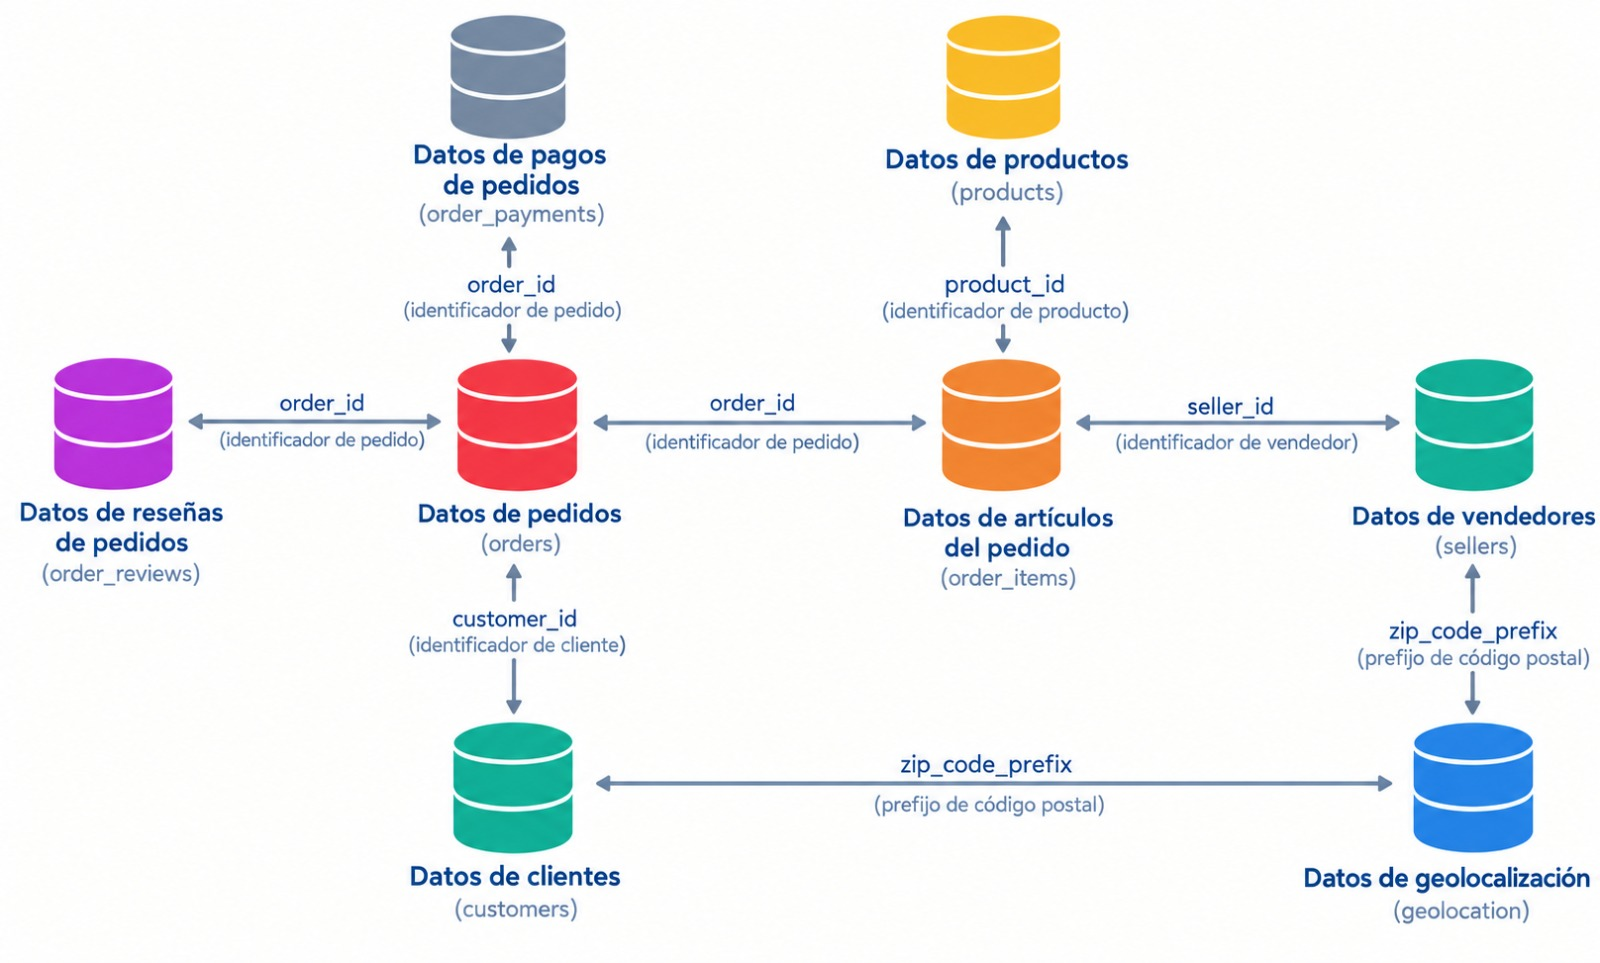

# BLOQUE A – Configuración e importación
## A.1 Instalación de librerías
`kagglehub` descarga el dataset desde Kaggle e `imbalanced-learn` aporta SMOTE (se usa en el Paso 7).

In [4]:
# Instala kagglehub (descarga de datasets) e imbalanced-learn (SMOTE); -q silencia la salida
!pip install -q kagglehub imbalanced-learn

## A.2 Importación de librerías

In [5]:
import os                                   # manejo de rutas y archivos del sistema
import warnings                             # control de avisos de Python
import numpy as np                          # cálculo numérico y arrays
import pandas as pd                         # manipulación de DataFrames
import matplotlib.pyplot as plt             # gráficos base
import seaborn as sns                       # gráficos estadísticos
from scipy import stats                     # tests estadísticos (chi-cuadrado, z-score)

warnings.filterwarnings('ignore')           # oculta advertencias para mantener limpia la salida
pd.set_option('display.max_columns', 60)    # muestra hasta 60 columnas al imprimir un DataFrame
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')  # formatea los decimales a 3 cifras
sns.set_theme(style='whitegrid')            # estilo visual por defecto de seaborn

## A.3 Descarga del dataset desde Kaggle

In [6]:
import kagglehub                            # importa la librería de descarga

# Descarga la última versión del dataset y guarda en `path` la carpeta local donde quedó
path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")

print("Path to dataset files:", path)       # muestra la ruta de la carpeta descargada

Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.
Path to dataset files: /kaggle/input/brazilian-ecommerce


In [7]:
# Lista los archivos CSV disponibles en la carpeta descargada
for archivo in sorted(os.listdir(path)):    # recorre los nombres de archivo en orden alfabético
    print(archivo)                          # imprime cada nombre (deben ser 9 CSV)

olist_customers_dataset.csv
olist_geolocation_dataset.csv
olist_order_items_dataset.csv
olist_order_payments_dataset.csv
olist_order_reviews_dataset.csv
olist_orders_dataset.csv
olist_products_dataset.csv
olist_sellers_dataset.csv
product_category_name_translation.csv


# BLOQUE B – Carga y vista de cada tabla (originales `raw_*`)
Para cada tabla se hace lo mismo: leer el CSV, ver dimensiones, primeras filas, tipos de dato (`info`), nulos y estadísticos descriptivos.

## B.1 Tabla `orders`
Estado del pedido y marcas de tiempo del ciclo de vida (compra, aprobación, entrega, fecha estimada).

In [8]:
# Lee el CSV de la tabla orders y lo guarda como original intocable (raw_orders)
raw_orders = pd.read_csv(os.path.join(path, 'olist_orders_dataset.csv'))  # une la carpeta con el nombre del archivo y lo lee

print('Forma (filas, columnas):', raw_orders.shape)  # cantidad de filas y columnas
display(raw_orders.head())                           # primeras 5 filas para ver el contenido

raw_orders.info()                                    # tipos de dato y cantidad de no-nulos por columna

nulos = raw_orders.isnull().sum()                    # cuenta los nulos de cada columna
print('\nColumnas con nulos:')                  # título de la salida
print(nulos[nulos > 0] if (nulos > 0).any() else 'Sin nulos')  # muestra solo las columnas con nulos

print('Filas duplicadas exactas:', raw_orders.duplicated().sum())  # unicidad: filas totalmente repetidas
display(raw_orders.describe(include='all').T)        # estadísticos descriptivos (numéricos y categóricos)

Forma (filas, columnas): (99441, 8)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

Columnas con nulos:
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64
Filas duplicadas exactas: 0


,count,unique,top,freq
order_id,99441,99441,e481f51cbdc54678b7cc49136f2d6af7,1
customer_id,99441,99441,9ef432eb6251297304e76186b10a928d,1
order_status,99441,8,delivered,96478
order_purchase_timestamp,99441,98875,2018-02-19 15:37:47,3
order_approved_at,99281,90733,2018-02-27 04:31:10,9
order_delivered_carrier_date,97658,81018,2018-05-09 15:48:00,47
order_delivered_customer_date,96476,95664,2016-10-27 17:32:07,3
order_estimated_delivery_date,99441,459,2017-12-20 00:00:00,522


## B.2 Tabla `customers`
Datos del cliente: `customer_id` (por orden), `customer_unique_id` (persona real), ciudad, estado y prefijo postal.

In [9]:
# Lee el CSV de la tabla customers y lo guarda como original intocable (raw_customers)
raw_customers = pd.read_csv(os.path.join(path, 'olist_customers_dataset.csv'))  # une la carpeta con el nombre del archivo y lo lee

print('Forma (filas, columnas):', raw_customers.shape)  # cantidad de filas y columnas
display(raw_customers.head())                           # primeras 5 filas para ver el contenido

raw_customers.info()                                    # tipos de dato y cantidad de no-nulos por columna

nulos = raw_customers.isnull().sum()                    # cuenta los nulos de cada columna
print('\nColumnas con nulos:')                  # título de la salida
print(nulos[nulos > 0] if (nulos > 0).any() else 'Sin nulos')  # muestra solo las columnas con nulos

print('Filas duplicadas exactas:', raw_customers.duplicated().sum())  # unicidad: filas totalmente repetidas
display(raw_customers.describe(include='all').T)        # estadísticos descriptivos (numéricos y categóricos)

Forma (filas, columnas): (99441, 5)


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB

Columnas con nulos:
Sin nulos
Filas duplicadas exactas: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,99441,99441,06b8999e2fba1a1fbc88172c00ba8bc7,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_unique_id,99441,96096,8d50f5eadf50201ccdcedfb9e2ac8455,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_zip_code_prefix,"99,441.000",NaN,NaN,NaN,"35,137.475","29,797.939","1,003.000","11,347.000","24,416.000","58,900.000","99,990.000"
customer_city,99441,4119,sao paulo,15540,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_state,99441,27,SP,41746,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## B.3 Tabla `order_items`
Detalle de productos por orden: producto, vendedor, precio y valor del flete. Una orden puede tener varios ítems.

In [10]:
# Lee el CSV de la tabla order_items y lo guarda como original intocable (raw_items)
raw_items = pd.read_csv(os.path.join(path, 'olist_order_items_dataset.csv'))  # une la carpeta con el nombre del archivo y lo lee

print('Forma (filas, columnas):', raw_items.shape)  # cantidad de filas y columnas
display(raw_items.head())                           # primeras 5 filas para ver el contenido

raw_items.info()                                    # tipos de dato y cantidad de no-nulos por columna

nulos = raw_items.isnull().sum()                    # cuenta los nulos de cada columna
print('\nColumnas con nulos:')                  # título de la salida
print(nulos[nulos > 0] if (nulos > 0).any() else 'Sin nulos')  # muestra solo las columnas con nulos

print('Filas duplicadas exactas:', raw_items.duplicated().sum())  # unicidad: filas totalmente repetidas
display(raw_items.describe(include='all').T)        # estadísticos descriptivos (numéricos y categóricos)

Forma (filas, columnas): (112650, 7)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.900,13.290
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.900,19.930
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.000,17.870
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.990,12.790
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.900,18.140


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB

Columnas con nulos:
Sin nulos
Filas duplicadas exactas: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,112650,98666,8272b63d03f5f79c56e9e4120aec44ef,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_item_id,"112,650.000",NaN,NaN,NaN,1.198,0.705,1.000,1.000,1.000,1.000,21.000
product_id,112650,32951,aca2eb7d00ea1a7b8ebd4e68314663af,527,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_id,112650,3095,6560211a19b47992c3666cc44a7e94c0,2033,NaN,NaN,NaN,NaN,NaN,NaN,NaN
shipping_limit_date,112650,93318,2018-03-01 02:50:48,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,"112,650.000",NaN,NaN,NaN,120.654,183.634,0.850,39.900,74.990,134.900,"6,735.000"
freight_value,"112,650.000",NaN,NaN,NaN,19.990,15.806,0.000,13.080,16.260,21.150,409.680


## B.4 Tabla `order_payments`
Pagos por orden: tipo, cuotas y monto. Una orden puede tener varios métodos de pago.

In [11]:
# Lee el CSV de la tabla order_payments y lo guarda como original intocable (raw_payments)
raw_payments = pd.read_csv(os.path.join(path, 'olist_order_payments_dataset.csv'))  # une la carpeta con el nombre del archivo y lo lee

print('Forma (filas, columnas):', raw_payments.shape)  # cantidad de filas y columnas
display(raw_payments.head())                           # primeras 5 filas para ver el contenido

raw_payments.info()                                    # tipos de dato y cantidad de no-nulos por columna

nulos = raw_payments.isnull().sum()                    # cuenta los nulos de cada columna
print('\nColumnas con nulos:')                  # título de la salida
print(nulos[nulos > 0] if (nulos > 0).any() else 'Sin nulos')  # muestra solo las columnas con nulos

print('Filas duplicadas exactas:', raw_payments.duplicated().sum())  # unicidad: filas totalmente repetidas
display(raw_payments.describe(include='all').T)        # estadísticos descriptivos (numéricos y categóricos)

Forma (filas, columnas): (103886, 5)


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.330
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.390
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.710
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.780
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.450


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  object 
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  object 
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 4.0+ MB

Columnas con nulos:
Sin nulos
Filas duplicadas exactas: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,103886,99440,fa65dad1b0e818e3ccc5cb0e39231352,29,NaN,NaN,NaN,NaN,NaN,NaN,NaN
payment_sequential,"103,886.000",NaN,NaN,NaN,1.093,0.707,1.000,1.000,1.000,1.000,29.000
payment_type,103886,5,credit_card,76795,NaN,NaN,NaN,NaN,NaN,NaN,NaN
payment_installments,"103,886.000",NaN,NaN,NaN,2.853,2.687,0.000,1.000,1.000,4.000,24.000
payment_value,"103,886.000",NaN,NaN,NaN,154.100,217.494,0.000,56.790,100.000,171.838,"13,664.080"


## B.5 Tabla `order_reviews`
Reseñas: puntaje 1–5, título, comentario (en portugués) y fechas. Puede haber más de una reseña por orden.

In [12]:
# Lee el CSV de la tabla order_reviews y lo guarda como original intocable (raw_reviews)
raw_reviews = pd.read_csv(os.path.join(path, 'olist_order_reviews_dataset.csv'))  # une la carpeta con el nombre del archivo y lo lee

print('Forma (filas, columnas):', raw_reviews.shape)  # cantidad de filas y columnas
display(raw_reviews.head())                           # primeras 5 filas para ver el contenido

raw_reviews.info()                                    # tipos de dato y cantidad de no-nulos por columna

nulos = raw_reviews.isnull().sum()                    # cuenta los nulos de cada columna
print('\nColumnas con nulos:')                  # título de la salida
print(nulos[nulos > 0] if (nulos > 0).any() else 'Sin nulos')  # muestra solo las columnas con nulos

print('Filas duplicadas exactas:', raw_reviews.duplicated().sum())  # unicidad: filas totalmente repetidas
display(raw_reviews.describe(include='all').T)        # estadísticos descriptivos (numéricos y categóricos)

Forma (filas, columnas): (99224, 7)


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB

Columnas con nulos:
review_comment_title      87656
review_comment_message    58247
dtype: int64
Filas duplicadas exactas: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
review_id,99224,98410,4548534449b1f572e357211b90724f1b,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_id,99224,98673,8e17072ec97ce29f0e1f111e598b0c85,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
review_score,"99,224.000",NaN,NaN,NaN,4.086,1.348,1.000,4.000,5.000,5.000,5.000
review_comment_title,11568,4527,Recomendo,423,NaN,NaN,NaN,NaN,NaN,NaN,NaN
review_comment_message,40977,36159,Muito bom,230,NaN,NaN,NaN,NaN,NaN,NaN,NaN
review_creation_date,99224,636,2017-12-19 00:00:00,463,NaN,NaN,NaN,NaN,NaN,NaN,NaN
review_answer_timestamp,99224,98248,2017-06-15 23:21:05,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## B.6 Tabla `products`
Atributos del producto: categoría, peso y dimensiones (cm / g).

In [13]:
# Lee el CSV de la tabla products y lo guarda como original intocable (raw_products)
raw_products = pd.read_csv(os.path.join(path, 'olist_products_dataset.csv'))  # une la carpeta con el nombre del archivo y lo lee

print('Forma (filas, columnas):', raw_products.shape)  # cantidad de filas y columnas
display(raw_products.head())                           # primeras 5 filas para ver el contenido

raw_products.info()                                    # tipos de dato y cantidad de no-nulos por columna

nulos = raw_products.isnull().sum()                    # cuenta los nulos de cada columna
print('\nColumnas con nulos:')                  # título de la salida
print(nulos[nulos > 0] if (nulos > 0).any() else 'Sin nulos')  # muestra solo las columnas con nulos

print('Filas duplicadas exactas:', raw_products.duplicated().sum())  # unicidad: filas totalmente repetidas
display(raw_products.describe(include='all').T)        # estadísticos descriptivos (numéricos y categóricos)

Forma (filas, columnas): (32951, 9)


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.000,287.000,1.000,225.000,16.000,10.000,14.000
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.000,276.000,1.000,"1,000.000",30.000,18.000,20.000
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.000,250.000,1.000,154.000,18.000,9.000,15.000
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.000,261.000,1.000,371.000,26.000,4.000,26.000
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.000,402.000,4.000,625.000,20.000,17.000,13.000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  object 
 1   product_category_name       32341 non-null  object 
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), object(2)
memory usage: 2.3+ MB

Columnas con nulos:
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm     

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
product_id,32951,32951,1e9e8ef04dbcff4541ed26657ea517e5,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_category_name,32341,73,cama_mesa_banho,3029,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_name_lenght,"32,341.000",NaN,NaN,NaN,48.477,10.246,5.000,42.000,51.000,57.000,76.000
product_description_lenght,"32,341.000",NaN,NaN,NaN,771.495,635.115,4.000,339.000,595.000,972.000,"3,992.000"
product_photos_qty,"32,341.000",NaN,NaN,NaN,2.189,1.737,1.000,1.000,1.000,3.000,20.000
product_weight_g,"32,949.000",NaN,NaN,NaN,"2,276.472","4,282.039",0.000,300.000,700.000,"1,900.000","40,425.000"
product_length_cm,"32,949.000",NaN,NaN,NaN,30.815,16.914,7.000,18.000,25.000,38.000,105.000
product_height_cm,"32,949.000",NaN,NaN,NaN,16.938,13.638,2.000,8.000,13.000,21.000,105.000
product_width_cm,"32,949.000",NaN,NaN,NaN,23.197,12.079,6.000,15.000,20.000,30.000,118.000


## B.7 Tabla `sellers`
Datos del vendedor: prefijo postal, ciudad y estado.

In [14]:
# Lee el CSV de la tabla sellers y lo guarda como original intocable (raw_sellers)
raw_sellers = pd.read_csv(os.path.join(path, 'olist_sellers_dataset.csv'))  # une la carpeta con el nombre del archivo y lo lee

print('Forma (filas, columnas):', raw_sellers.shape)  # cantidad de filas y columnas
display(raw_sellers.head())                           # primeras 5 filas para ver el contenido

raw_sellers.info()                                    # tipos de dato y cantidad de no-nulos por columna

nulos = raw_sellers.isnull().sum()                    # cuenta los nulos de cada columna
print('\nColumnas con nulos:')                  # título de la salida
print(nulos[nulos > 0] if (nulos > 0).any() else 'Sin nulos')  # muestra solo las columnas con nulos

print('Filas duplicadas exactas:', raw_sellers.duplicated().sum())  # unicidad: filas totalmente repetidas
display(raw_sellers.describe(include='all').T)        # estadísticos descriptivos (numéricos y categóricos)

Forma (filas, columnas): (3095, 4)


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   seller_id               3095 non-null   object
 1   seller_zip_code_prefix  3095 non-null   int64 
 2   seller_city             3095 non-null   object
 3   seller_state            3095 non-null   object
dtypes: int64(1), object(3)
memory usage: 96.8+ KB

Columnas con nulos:
Sin nulos
Filas duplicadas exactas: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
seller_id,3095,3095,3442f8959a84dea7ee197c632cb2df15,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_zip_code_prefix,"3,095.000",NaN,NaN,NaN,"32,291.059","32,713.454","1,001.000","7,093.500","14,940.000","64,552.500","99,730.000"
seller_city,3095,611,sao paulo,694,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_state,3095,23,SP,1849,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## B.8 Tabla `geolocation`
Coordenadas (lat/lng) por prefijo postal. **El prefijo se repite muchas veces** (hay que agregarlo antes del join).

In [15]:
# Lee el CSV de la tabla geolocation y lo guarda como original intocable (raw_geolocation)
raw_geolocation = pd.read_csv(os.path.join(path, 'olist_geolocation_dataset.csv'))  # une la carpeta con el nombre del archivo y lo lee

print('Forma (filas, columnas):', raw_geolocation.shape)  # cantidad de filas y columnas
display(raw_geolocation.head())                           # primeras 5 filas para ver el contenido

raw_geolocation.info()                                    # tipos de dato y cantidad de no-nulos por columna

nulos = raw_geolocation.isnull().sum()                    # cuenta los nulos de cada columna
print('\nColumnas con nulos:')                  # título de la salida
print(nulos[nulos > 0] if (nulos > 0).any() else 'Sin nulos')  # muestra solo las columnas con nulos

print('Filas duplicadas exactas:', raw_geolocation.duplicated().sum())  # unicidad: filas totalmente repetidas
display(raw_geolocation.describe(include='all').T)        # estadísticos descriptivos (numéricos y categóricos)

Forma (filas, columnas): (1000163, 5)


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.546,-46.639,sao paulo,SP
1,1046,-23.546,-46.645,sao paulo,SP
2,1046,-23.546,-46.643,sao paulo,SP
3,1041,-23.544,-46.639,sao paulo,SP
4,1035,-23.542,-46.642,sao paulo,SP


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  object 
 4   geolocation_state            1000163 non-null  object 
dtypes: float64(2), int64(1), object(2)
memory usage: 38.2+ MB

Columnas con nulos:
Sin nulos
Filas duplicadas exactas: 261831


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
geolocation_zip_code_prefix,"1,000,163.000",NaN,NaN,NaN,"36,574.166","30,549.336","1,001.000","11,075.000","26,530.000","63,504.000","99,990.000"
geolocation_lat,"1,000,163.000",NaN,NaN,NaN,-21.176,5.716,-36.605,-23.604,-22.919,-19.980,45.066
geolocation_lng,"1,000,163.000",NaN,NaN,NaN,-46.391,4.270,-101.467,-48.573,-46.638,-43.768,121.105
geolocation_city,1000163,8011,sao paulo,135800,NaN,NaN,NaN,NaN,NaN,NaN,NaN
geolocation_state,1000163,27,SP,404268,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## B.9 Tabla `category_translation`
Traducción de categorías de producto del portugués al inglés.

In [16]:
# Lee el CSV de la tabla category_translation y lo guarda como original intocable (raw_translation)
raw_translation = pd.read_csv(os.path.join(path, 'product_category_name_translation.csv'))  # une la carpeta con el nombre del archivo y lo lee

print('Forma (filas, columnas):', raw_translation.shape)  # cantidad de filas y columnas
display(raw_translation.head())                           # primeras 5 filas para ver el contenido

raw_translation.info()                                    # tipos de dato y cantidad de no-nulos por columna

nulos = raw_translation.isnull().sum()                    # cuenta los nulos de cada columna
print('\nColumnas con nulos:')                  # título de la salida
print(nulos[nulos > 0] if (nulos > 0).any() else 'Sin nulos')  # muestra solo las columnas con nulos

print('Filas duplicadas exactas:', raw_translation.duplicated().sum())  # unicidad: filas totalmente repetidas
display(raw_translation.describe(include='all').T)        # estadísticos descriptivos (numéricos y categóricos)

Forma (filas, columnas): (71, 2)


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71 entries, 0 to 70
Data columns (total 2 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   product_category_name          71 non-null     object
 1   product_category_name_english  71 non-null     object
dtypes: object(2)
memory usage: 1.2+ KB

Columnas con nulos:
Sin nulos
Filas duplicadas exactas: 0


,count,unique,top,freq
product_category_name,71,71,beleza_saude,1
product_category_name_english,71,71,health_beauty,1


# BLOQUE C – Copias de trabajo
`.copy()` crea una copia independiente: cualquier cambio sobre `orders`, `customers`, etc. **no** afecta a los `raw_*`.

In [17]:
orders = raw_orders.copy()                  # copia de trabajo de órdenes
customers = raw_customers.copy()            # copia de trabajo de clientes
items = raw_items.copy()                    # copia de trabajo de ítems por orden
payments = raw_payments.copy()              # copia de trabajo de pagos
reviews = raw_reviews.copy()                # copia de trabajo de reseñas
products = raw_products.copy()              # copia de trabajo de productos
sellers = raw_sellers.copy()                # copia de trabajo de vendedores
geolocation = raw_geolocation.copy()        # copia de trabajo de geolocalización
translation = raw_translation.copy()        # copia de trabajo de traducción de categorías

# Verificación: son objetos distintos en memoria (modificar uno no altera el otro)
print('orders es el mismo objeto que raw_orders?:', orders is raw_orders)  # debe imprimir False

orders es el mismo objeto que raw_orders?: False


In [18]:
# Resumen de control: filas y columnas de cada copia de trabajo
resumen = pd.DataFrame({
    'tabla': ['orders', 'customers', 'items', 'payments', 'reviews', 'products', 'sellers', 'geolocation', 'translation'],
    'filas': [len(d) for d in [orders, customers, items, payments, reviews, products, sellers, geolocation, translation]],
    'columnas': [d.shape[1] for d in [orders, customers, items, payments, reviews, products, sellers, geolocation, translation]],
})
display(resumen)                            # tabla resumen de tamaños

,tabla,filas,columnas
0,orders,99441,8
1,customers,99441,5
2,items,112650,7
3,payments,103886,5
4,reviews,99224,7
5,products,32951,9
6,sellers,3095,4
7,geolocation,1000163,5
8,translation,71,2


# BLOQUE D – Joins para vincular los DataFrames
**Idea central:** la unidad de análisis es la **orden** (`order_id`). Como `items`, `payments` y `reviews` tienen varias filas por orden, primero se **agregan a nivel de orden** y recién después se hace el `merge`; si no, el join multiplicaría las filas.

Orden de trabajo:
1. D.1 Agregar ítems, pagos, reseñas y geolocalización.
2. D.2 Enriquecer productos con la traducción de categorías.
3. D.3 Unir todo a partir de `orders` con `how='left'` y controlar que las filas no se dupliquen.

## D.1 Agregaciones a nivel de orden

In [19]:
# --- Ítems: una fila por orden con precio total, flete total y conteos ---
items_agg = (items.groupby('order_id')                      # agrupa los ítems por orden
    .agg(precio_total=('price', 'sum'),                     # suma de precios de la orden
         flete_total=('freight_value', 'sum'),              # suma de fletes de la orden
         n_items=('order_item_id', 'count'),                # cantidad de ítems en la orden
         n_productos_distintos=('product_id', 'nunique'),   # cantidad de productos distintos
         n_vendedores=('seller_id', 'nunique'))             # cantidad de vendedores distintos
    .reset_index())                                         # vuelve order_id a columna normal

# --- Producto y vendedor principal de la orden (primer ítem) para poder unir con products y sellers ---
items_principal = (items.sort_values(['order_id', 'order_item_id'])   # ordena por orden e ítem
    .drop_duplicates('order_id', keep='first')                        # se queda con el primer ítem de cada orden
    [['order_id', 'product_id', 'seller_id']])                        # solo las columnas necesarias

print('items_agg:', items_agg.shape, '| items_principal:', items_principal.shape)  # una fila por orden en ambos

items_agg: (98666, 6) | items_principal: (98666, 3)


In [20]:
# --- Pagos: una fila por orden con monto total, cuotas y tipo de pago dominante ---
pago_dominante = (payments.sort_values('payment_value', ascending=False)  # ordena del pago más grande al más chico
    .drop_duplicates('order_id', keep='first')                            # se queda con el pago de mayor monto por orden
    [['order_id', 'payment_type']])                                       # tipo de pago dominante

payments_agg = (payments.groupby('order_id')                # agrupa los pagos por orden
    .agg(pago_total=('payment_value', 'sum'),               # suma de los montos pagados
         cuotas_max=('payment_installments', 'max'),        # máximo de cuotas utilizado
         n_metodos_pago=('payment_sequential', 'count'))    # cantidad de pagos registrados
    .reset_index()                                          # order_id vuelve a ser columna
    .merge(pago_dominante, on='order_id', how='left'))      # agrega el tipo de pago dominante

print('payments_agg:', payments_agg.shape)                  # una fila por orden

payments_agg: (99440, 5)


In [21]:
# --- Reseñas: puede haber varias por orden; nos quedamos con la más reciente ---
reviews_agg = (reviews.sort_values('review_answer_timestamp')   # ordena por fecha de respuesta (ascendente)
    .drop_duplicates('order_id', keep='last'))                  # conserva la última reseña de cada orden

print('reviews_agg:', reviews_agg.shape, '| order_id únicos:', reviews_agg['order_id'].is_unique)  # control de unicidad

reviews_agg: (98673, 7) | order_id únicos: True


In [22]:
# --- Geolocalización: el prefijo postal se repite, se promedia lat/lng por prefijo ---
geo_agg = (geolocation.groupby('geolocation_zip_code_prefix')       # agrupa por prefijo postal
    .agg(lat=('geolocation_lat', 'mean'),                           # latitud promedio del prefijo
         lng=('geolocation_lng', 'mean'))                           # longitud promedio del prefijo
    .reset_index())                                                 # prefijo vuelve a ser columna

# Versión para clientes: renombra columnas para no confundirlas con las del vendedor
geo_cliente = geo_agg.rename(columns={'geolocation_zip_code_prefix': 'customer_zip_code_prefix',
                                      'lat': 'cliente_lat', 'lng': 'cliente_lng'})

# Versión para vendedores: renombra columnas con el prefijo del vendedor
geo_vendedor = geo_agg.rename(columns={'geolocation_zip_code_prefix': 'seller_zip_code_prefix',
                                       'lat': 'vendedor_lat', 'lng': 'vendedor_lng'})

print('geo_agg:', geo_agg.shape, '| prefijos únicos:', geo_agg['geolocation_zip_code_prefix'].is_unique)  # debe ser True

geo_agg: (19015, 3) | prefijos únicos: True


## D.2 Productos con categoría traducida

In [23]:
# Une productos con su traducción al inglés (left: conserva los productos sin traducción)
products_en = products.merge(translation, on='product_category_name', how='left')

# Reemplaza por 'desconocido' los productos sin categoría o sin traducción
products_en['product_category_name_english'] = products_en['product_category_name_english'].fillna('desconocido')

print('products_en:', products_en.shape)                        # misma cantidad de filas que products

products_en: (32951, 10)


## D.3 Unión final (DataFrame maestro)

In [24]:
n_ordenes = len(orders)                                         # filas de referencia: una por orden

# 1) orders + customers (por customer_id)
df_master = orders.merge(customers, on='customer_id', how='left')
# 2) + agregado de ítems (por order_id)
df_master = df_master.merge(items_agg, on='order_id', how='left')
# 3) + producto y vendedor principal (por order_id)
df_master = df_master.merge(items_principal, on='order_id', how='left')
# 4) + agregado de pagos (por order_id)
df_master = df_master.merge(payments_agg, on='order_id', how='left')
# 5) + atributos del producto principal (por product_id)
df_master = df_master.merge(products_en.drop(columns=['product_category_name']), on='product_id', how='left')
# 6) + datos del vendedor principal (por seller_id)
df_master = df_master.merge(sellers, on='seller_id', how='left')
# 7) + reseña (por order_id)
df_master = df_master.merge(reviews_agg, on='order_id', how='left')
# 8) + coordenadas del cliente (por prefijo postal del cliente)
df_master = df_master.merge(geo_cliente, on='customer_zip_code_prefix', how='left')
# 9) + coordenadas del vendedor (por prefijo postal del vendedor)
df_master = df_master.merge(geo_vendedor, on='seller_zip_code_prefix', how='left')

# Controles de integridad del join
print('Filas orders:', n_ordenes, '| Filas df_master:', len(df_master))  # deben coincidir
print('order_id único en df_master:', df_master['order_id'].is_unique)   # debe ser True
print('Forma final:', df_master.shape)                                   # (filas, columnas)
display(df_master.head())                                                # vista previa del maestro

Filas orders: 99441 | Filas df_master: 99441
order_id único en df_master: True
Forma final: (99441, 44)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,precio_total,flete_total,n_items,n_productos_distintos,n_vendedores,product_id,seller_id,pago_total,cuotas_max,n_metodos_pago,payment_type,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english,seller_zip_code_prefix,seller_city,seller_state,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,cliente_lat,cliente_lng,vendedor_lat,vendedor_lng
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,29.990,8.720,1.000,1.000,1.000,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,38.710,1.000,3.000,voucher,40.000,268.000,4.000,500.000,19.000,8.000,13.000,housewares,"9,350.000",maua,SP,a54f0611adc9ed256b57ede6b6eb5114,4.000,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11 00:00:00,2017-10-12 03:43:48,-23.577,-46.587,-23.681,-46.444
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,118.700,22.760,1.000,1.000,1.000,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,141.460,1.000,1.000,boleto,29.000,178.000,1.000,400.000,19.000,13.000,19.000,perfumery,"31,570.000",belo horizonte,SP,8d5266042046a06655c8db133d120ba5,4.000,Muito boa a loja,Muito bom o produto.,2018-08-08 00:00:00,2018-08-08 18:37:50,-12.178,-44.661,-19.808,-43.980
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,159.900,19.220,1.000,1.000,1.000,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,179.120,3.000,1.000,credit_card,46.000,232.000,1.000,420.000,24.000,19.000,21.000,auto,"14,840.000",guariba,SP,e73b67b67587f7644d5bd1a52deb1b01,5.000,NaN,NaN,2018-08-18 00:00:00,2018-08-22 19:07:58,-16.745,-48.515,-21.364,-48.230
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,45.000,27.200,1.000,1.000,1.000,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,72.200,1.000,1.000,credit_card,59.000,468.000,3.000,450.000,30.000,10.000,20.000,pet_shop,"31,842.000",belo horizonte,MG,359d03e676b3c069f62cadba8dd3f6e8,5.000,NaN,O produto foi exatamente o que eu esperava e e...,2017-12-03 00:00:00,2017-12-05 19:21:58,-5.774,-35.271,-19.838,-43.924
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,19.900,8.720,1.000,1.000,1.000,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,28.620,1.000,1.000,credit_card,38.000,316.000,4.000,250.000,51.000,15.000,15.000,stationery,"8,752.000",mogi das cruzes,SP,e50934924e227544ba8246aeb3770dd4,5.000,NaN,NaN,2018-02-17 00:00:00,2018-02-18 13:02:51,-23.676,-46.515,-23.543,-46.262


In [25]:
# Copia de trabajo del maestro: sobre df_work se hace todo el pipeline, df_master queda como respaldo
df_work = df_master.copy()

# Convierte a fecha las columnas de tiempo (errors='coerce' deja NaT si hay un valor inválido)
cols_fecha = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
              'order_delivered_customer_date', 'order_estimated_delivery_date',
              'review_creation_date', 'review_answer_timestamp']
for c in cols_fecha:                                            # recorre cada columna de fecha
    df_work[c] = pd.to_datetime(df_work[c], errors='coerce')    # la convierte a datetime

df_work.info()                                                  # verifica tipos y nulos del maestro

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 44 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  object        
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99281 non-null  datetime64[ns]
 5   order_delivered_carrier_date   97658 non-null  datetime64[ns]
 6   order_delivered_customer_date  96476 non-null  datetime64[ns]
 7   order_estimated_delivery_date  99441 non-null  datetime64[ns]
 8   customer_unique_id             99441 non-null  object        
 9   customer_zip_code_prefix       99441 non-null  int64         
 10  customer_city                  99441 non-null  object        
 11  customer_state 

# BLOQUE E – Los 7 pasos del pipeline
Esqueleto genérico basado en el modelo de la Parte 2 (churn). Las consignas definirán el **target**, las **columnas** y las **reglas de negocio**; mientras tanto se centralizan en la celda de configuración.

Consignas:

https://docs.google.com/document/d/1I13NCOrtJACXbc9nAqrx8wiAyl6mcIHV2GeIQmRHWDM/edit?usp=sharing

## E.0 Configuración del caso (se completa con cada consigna)

In [26]:
# ----- PARÁMETROS DEL CASO (editar según la consigna) -----
TARGET = 'is_delayed'                       # variable objetivo (ej.: retraso = 1 si dias_retraso > 0)
COL_FECHA_SPLIT = 'order_purchase_timestamp'  # columna de fecha para la partición temporal
FECHA_CORTE = '2018-06-01'                  # fecha que separa train (antes) de test (después)
USAR_SPLIT_TEMPORAL = True                  # True = temporal (recomendado en Olist) | False = estratificado aleatorio

# Numéricas con distribución simétrica o uniforme (escala estándar)
NUM_STD = ['product_photos_qty', 'product_name_lenght', 'product_description_lenght']

# Numéricas asimétricas (transformación Yeo-Johnson; usamos preferentemente las winsorizadas '_w')
NUM_POW = ['precio_total_w', 'flete_total_w', 'product_weight_g_w', 'pago_total', 'cuotas_max', 'n_items']

# Categóricas nominales sin orden jerárquico
CAT_NOMINAL = ['payment_type', 'customer_state', 'seller_state']

# Categóricas ordinales con orden jerárquico definido
CAT_ORDINAL = []

# Lista de listas con el orden de cada ordinal
ORDEN_ORDINAL = []

# Variables posteriores al evento que deben eliminarse para evitar Target Leakage
COLS_LEAKAGE = [
    'order_delivered_customer_date',
    'order_delivered_carrier_date',
    'order_approved_at',
    'order_status',
    'review_score',
    'review_comment_message',
    'review_comment_title',
    'review_id',
    'review_creation_date',
    'review_answer_timestamp'
]

## Paso 1: Exploración inicial, diagnóstico de calidad y auditoría previa
**Objetivo:** inspeccionar estructura, diagnosticar las 4 dimensiones de calidad (Completitud, Consistencia, Validez, Unicidad) y auditar *Target Leakage*.

> **Atención en Olist:** para predecir retrasos o satisfacción, son sospechosas las variables que solo se conocen **después** del evento (`order_delivered_customer_date`, `review_score`, `review_comment_*`, `dias_retraso`, etc.).

In [27]:
df1 = df_work.copy()                                            # copia para el diagnóstico

print('--- Diagnóstico estructural ---')
print(df1.shape)                                                # dimensiones
display(df1.head())                                             # primeras filas
df1.info()                                                      # tipos y no-nulos
display(df1.describe().T)                                       # descriptivos numéricos

# 1) COMPLETITUD: porcentaje de datos presentes por columna
completitud = (df1.notna().mean() * 100).round(1).rename('completitud_%')
print('\nCOMPLETITUD\n', completitud.sort_values().head(20))   # las 20 columnas más incompletas

# 2) CONSISTENCIA: categorías escritas distinto / valores no esperados
print('\nCONSISTENCIA - order_status:')
print(df1['order_status'].value_counts(dropna=False))           # estados de pedido y su frecuencia

# 3) VALIDEZ: valores imposibles según reglas de negocio
print('\nVALIDEZ')
print('  Precios <= 0:', (df1['precio_total'] <= 0).sum())       # precios no positivos
print('  Entrega anterior a la compra:',
      (df1['order_delivered_customer_date'] < df1['order_purchase_timestamp']).sum())  # fechas ilógicas
print('  review_score fuera de [1,5]:', (~df1['review_score'].between(1, 5) & df1['review_score'].notna()).sum())

# 4) UNICIDAD: duplicados
print('\nUNICIDAD')
print('  Filas duplicadas exactas:', df1.duplicated().sum())     # filas idénticas
print('  order_id repetidos:', df1['order_id'].duplicated().sum())  # debe ser 0 tras los joins

--- Diagnóstico estructural ---
(99441, 44)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,precio_total,flete_total,n_items,n_productos_distintos,n_vendedores,product_id,seller_id,pago_total,cuotas_max,n_metodos_pago,payment_type,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english,seller_zip_code_prefix,seller_city,seller_state,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,cliente_lat,cliente_lng,vendedor_lat,vendedor_lng
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,29.990,8.720,1.000,1.000,1.000,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,38.710,1.000,3.000,voucher,40.000,268.000,4.000,500.000,19.000,8.000,13.000,housewares,"9,350.000",maua,SP,a54f0611adc9ed256b57ede6b6eb5114,4.000,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11,2017-10-12 03:43:48,-23.577,-46.587,-23.681,-46.444
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,118.700,22.760,1.000,1.000,1.000,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,141.460,1.000,1.000,boleto,29.000,178.000,1.000,400.000,19.000,13.000,19.000,perfumery,"31,570.000",belo horizonte,SP,8d5266042046a06655c8db133d120ba5,4.000,Muito boa a loja,Muito bom o produto.,2018-08-08,2018-08-08 18:37:50,-12.178,-44.661,-19.808,-43.980
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,159.900,19.220,1.000,1.000,1.000,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,179.120,3.000,1.000,credit_card,46.000,232.000,1.000,420.000,24.000,19.000,21.000,auto,"14,840.000",guariba,SP,e73b67b67587f7644d5bd1a52deb1b01,5.000,NaN,NaN,2018-08-18,2018-08-22 19:07:58,-16.745,-48.515,-21.364,-48.230
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,45.000,27.200,1.000,1.000,1.000,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,72.200,1.000,1.000,credit_card,59.000,468.000,3.000,450.000,30.000,10.000,20.000,pet_shop,"31,842.000",belo horizonte,MG,359d03e676b3c069f62cadba8dd3f6e8,5.000,NaN,O produto foi exatamente o que eu esperava e e...,2017-12-03,2017-12-05 19:21:58,-5.774,-35.271,-19.838,-43.924
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,19.900,8.720,1.000,1.000,1.000,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,28.620,1.000,1.000,credit_card,38.000,316.000,4.000,250.000,51.000,15.000,15.000,stationery,"8,752.000",mogi das cruzes,SP,e50934924e227544ba8246aeb3770dd4,5.000,NaN,NaN,2018-02-17,2018-02-18 13:02:51,-23.676,-46.515,-23.543,-46.262


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 44 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  object        
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99281 non-null  datetime64[ns]
 5   order_delivered_carrier_date   97658 non-null  datetime64[ns]
 6   order_delivered_customer_date  96476 non-null  datetime64[ns]
 7   order_estimated_delivery_date  99441 non-null  datetime64[ns]
 8   customer_unique_id             99441 non-null  object        
 9   customer_zip_code_prefix       99441 non-null  int64         
 10  customer_city                  99441 non-null  object        
 11  customer_state 

,count,mean,min,25%,50%,75%,max,std
order_purchase_timestamp,99441,2017-12-31 08:43:12.776581120,2016-09-04 21:15:19,2017-09-12 14:46:19,2018-01-18 23:04:36,2018-05-04 15:42:16,2018-10-17 17:30:18,NaN
order_approved_at,99281,2017-12-31 18:35:24.098800128,2016-09-15 12:16:38,2017-09-12 23:24:16,2018-01-19 11:36:13,2018-05-04 20:35:10,2018-09-03 17:40:06,NaN
order_delivered_carrier_date,97658,2018-01-04 21:49:48.138278656,2016-10-08 10:34:01,2017-09-15 22:28:50.249999872,2018-01-24 16:10:58,2018-05-08 13:37:45,2018-09-11 19:48:28,NaN
order_delivered_customer_date,96476,2018-01-14 12:09:19.035542272,2016-10-11 13:46:32,2017-09-25 22:07:22.249999872,2018-02-02 19:28:10.500000,2018-05-15 22:48:52.249999872,2018-10-17 13:22:46,NaN
order_estimated_delivery_date,99441,2018-01-24 03:08:37.730111232,2016-09-30 00:00:00,2017-10-03 00:00:00,2018-02-15 00:00:00,2018-05-25 00:00:00,2018-11-12 00:00:00,NaN
customer_zip_code_prefix,"99,441.000","35,137.475","1,003.000","11,347.000","24,416.000","58,900.000","99,990.000","29,797.939"
precio_total,"98,666.000",137.754,0.850,45.900,86.900,149.900,"13,440.000",210.645
flete_total,"98,666.000",22.824,0.000,13.850,17.170,24.040,"1,794.960",21.651
n_items,"98,666.000",1.142,1.000,1.000,1.000,1.000,21.000,0.538
n_productos_distintos,"98,666.000",1.038,1.000,1.000,1.000,1.000,8.000,0.226



COMPLETITUD
 review_comment_title            11.600
review_comment_message          41.000
order_delivered_customer_date   97.000
product_photos_qty              97.800
product_description_lenght      97.800
product_name_lenght             97.800
order_delivered_carrier_date    98.200
vendedor_lat                    99.000
vendedor_lng                    99.000
seller_id                       99.200
product_weight_g                99.200
product_length_cm               99.200
product_id                      99.200
precio_total                    99.200
n_items                         99.200
n_productos_distintos           99.200
product_category_name_english   99.200
seller_zip_code_prefix          99.200
review_id                       99.200
review_score                    99.200
Name: completitud_%, dtype: float64

CONSISTENCIA - order_status:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
c

In [28]:
# --- Auditoría de Target Leakage ---
# Una variable es sospechosa si (a) se registra DESPUÉS del evento o (b) separa el target casi perfectamente.
# Ejemplo (descomentar cuando exista el target):
# print(df1.groupby(TARGET)['review_score'].describe())          # ¿el puntaje separa el target?
# print(pd.crosstab(df1['order_status'], df1[TARGET]))           # ¿el estado separa el target?

# Eliminación preventiva de las variables de fuga definidas en la configuración
df_clean = df1.drop(columns=COLS_LEAKAGE, errors='ignore').copy()   # errors='ignore' evita fallar si la lista está vacía
print('Columnas restantes:', df_clean.shape[1])

Columnas restantes: 34


## Paso 2: Limpieza operativa, deduplicación y estandarización
**Objetivo:** remover duplicados, corregir tipos, estandarizar texto y filtrar errores lógicos.
1. Deduplicación · 2. Normalización de texto · 3. Casting numérico · 4. Fechas · 5. Reglas de rango / negocio

In [29]:
# 1. Deduplicación
antes = len(df_clean)
df_clean = df_clean.drop_duplicates(keep='first').reset_index(drop=True)  # elimina duplicados exactos
print(f'Filas: {antes} -> {len(df_clean)}')                     # cuántas se eliminaron

# 2. Normalización de texto (espacios y mayúsculas)
cols_texto = ['order_status', 'customer_state', 'seller_state', 'payment_type', 'product_category_name_english']
# Filtramos para quedarnos solo con las columnas que existen actualmente en df_clean
cols_texto_presentes = [c for c in cols_texto if c in df_clean.columns]
for c in cols_texto_presentes:                                            # recorre cada columna de texto existente
    df_clean[c] = df_clean[c].astype('string').str.strip().str.lower()  # quita espacios y pasa a minúscula

# 3. Casting numérico
cols_num = ['precio_total', 'flete_total', 'pago_total', 'product_weight_g']
cols_num_presentes = [c for c in cols_num if c in df_clean.columns]
for c in cols_num_presentes:                                              # recorre cada columna numérica existente
    df_clean[c] = pd.to_numeric(df_clean[c], errors='coerce')   # valores no numéricos pasan a NaN

# 4. Fechas imposibles (ejemplo: entrega antes de la compra se marca como nula)
if 'order_delivered_customer_date' in df_clean.columns and 'order_purchase_timestamp' in df_clean.columns:
    fecha_invalida = df_clean['order_delivered_customer_date'] < df_clean['order_purchase_timestamp']
    df_clean['order_delivered_customer_date'] = df_clean['order_delivered_customer_date'].mask(fecha_invalida)

# 5. Rangos de negocio
if 'precio_total' in df_clean.columns:
    df_clean['precio_total'] = np.where(df_clean['precio_total'] <= 0, np.nan, df_clean['precio_total'])

print(df_clean.dtypes)                                          # verifica tipos finales

Filas: 99441 -> 99441
order_id                                 object
customer_id                              object
order_purchase_timestamp         datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
customer_unique_id                       object
customer_zip_code_prefix                  int64
customer_city                            object
customer_state                   string[python]
precio_total                            float64
flete_total                             float64
n_items                                 float64
n_productos_distintos                   float64
n_vendedores                            float64
product_id                               object
seller_id                                object
pago_total                              float64
cuotas_max                              float64
n_metodos_pago                          float64
payment_type                     string[python]
product_name_lenght                     float64
product_descriptio

## Paso 3: Visualización y tratamiento de datos faltantes
**MCAR** (al azar) · **MAR** (depende de otra variable observada; se detecta con chi-cuadrado) · **MNAR** (depende del propio valor; se argumenta con el negocio).

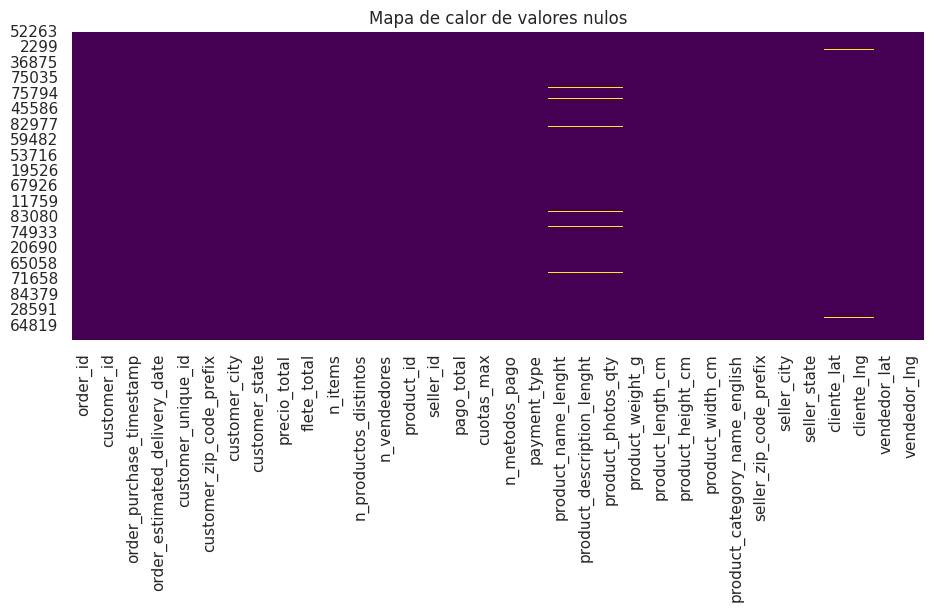

product_photos_qty              2.200
product_description_lenght      2.200
product_name_lenght             2.200
vendedor_lat                    1.000
vendedor_lng                    1.000
product_width_cm                0.800
seller_city                     0.800
precio_total                    0.800
n_productos_distintos           0.800
flete_total                     0.800
product_weight_g                0.800
product_height_cm               0.800
product_length_cm               0.800
seller_id                       0.800
product_id                      0.800
n_vendedores                    0.800
n_items                         0.800
seller_state                    0.800
product_category_name_english   0.800
seller_zip_code_prefix          0.800
dtype: float64
product_weight_g                 vs customer_state  | p = 0.0654 | sin relación -> compatible con MCAR


In [30]:
# Mapa de calor de nulos (una muestra de 5.000 filas para que sea liviano)
plt.figure(figsize=(11, 4))                                     # tamaño del gráfico
sns.heatmap(df_clean.sample(5000, random_state=42).isnull(), cbar=False, cmap='viridis')  # nulos en amarillo
plt.title('Mapa de calor de valores nulos')                     # título
plt.show()                                                      # muestra el gráfico

print((df_clean.isnull().mean() * 100).round(1).sort_values(ascending=False).head(20))  # % de nulos por columna

# Test de mecanismo de faltantes: ¿la ausencia depende de otra variable observada?
# Filtramos las columnas a evaluar y los grupos para asegurar que existan en df_clean
cols_evaluar = [col for col in ['order_delivered_customer_date', 'product_weight_g'] if col in df_clean.columns]
grupos_evaluar = [grupo for grupo in ['order_status', 'customer_state'] if grupo in df_clean.columns]

for col in cols_evaluar:   # columnas a evaluar (editar según consigna)
    faltante = df_clean[col].isna()                             # máscara de nulos
    for grupo in grupos_evaluar:            # variables candidatas a explicar la ausencia
        tabla = pd.crosstab(df_clean[grupo], faltante)          # tabla de contingencia
        chi2, p, _, _ = stats.chi2_contingency(tabla)           # test chi-cuadrado
        veredicto = 'depende del grupo -> MAR' if p < 0.05 else 'sin relación -> compatible con MCAR'
        print(f'{col:32s} vs {grupo:15s} | p = {p:.4f} | {veredicto}')

In [31]:
# 1. Eliminación de columnas con más de 50% de nulos
umbral_50 = len(df_clean) * 0.5                                 # mínimo de datos no nulos exigido
cols_antes = set(df_clean.columns)                              # columnas antes
df_clean = df_clean.dropna(axis=1, thresh=umbral_50)            # descarta las que no llegan al umbral
print('Columnas descartadas:', cols_antes - set(df_clean.columns))

# 2. Reglas de la consigna B de Olist
df_clean['review_comment_title'] = df_clean.get('review_comment_title', pd.Series(index=df_clean.index)).fillna('sin_comentario')
df_clean['review_comment_message'] = df_clean.get('review_comment_message', pd.Series(index=df_clean.index)).fillna('sin_comentario')
df_clean['product_category_name_english'] = df_clean['product_category_name_english'].fillna('desconocido')

# 3. Imputación condicional por grupo (ejemplo: peso del producto según su categoría)
df_clean['product_weight_g'] = df_clean.groupby('product_category_name_english')['product_weight_g'] \
    .transform(lambda x: x.fillna(x.median()))                  # mediana dentro de cada categoría

print(df_clean.isnull().sum().sort_values(ascending=False).head(15))  # nulos restantes

Columnas descartadas: set()
product_description_lenght    2191
product_photos_qty            2191
product_name_lenght           2191
vendedor_lat                   993
vendedor_lng                   993
product_length_cm              791
product_height_cm              791
product_width_cm               791
seller_city                    775
seller_state                   775
flete_total                    775
n_items                        775
seller_zip_code_prefix         775
n_productos_distintos          775
n_vendedores                   775
dtype: int64


> **Nota metodológica:** la guía imputa y winsoriza antes del split por claridad didáctica. En un proyecto real, medianas y percentiles se calculan solo con *train* (por ejemplo con `SimpleImputer` dentro del `Pipeline`).

## Paso 4: Detección y tratamiento de outliers
| Método | Criterio | Uso |
|---|---|---|
| IQR | Límite = Q3 + 1.5 × (Q3 − Q1) | Distribuciones asimétricas (precios, fletes, peso) |
| Z-Score | \|Z\| > 3 | Distribuciones con tendencia gaussiana |
| Winsorización | `np.clip(x, p1, p99)` | Acota extremos sin eliminar filas |

precio_total       | IQR [-110.1, 305.9] -> 7913 | Z>3 -> 1709
flete_total        | IQR [-1.4, 39.3] -> 9941 | Z>3 -> 1581
product_weight_g   | IQR [-1950.0, 4050.0] -> 14040 | Z>3 -> 2549
precio_total: máximo antes 13440.0 | después 998.9
flete_total: máximo antes 1795.0 | después 105.0
product_weight_g: máximo antes 40425.0 | después 18250.0


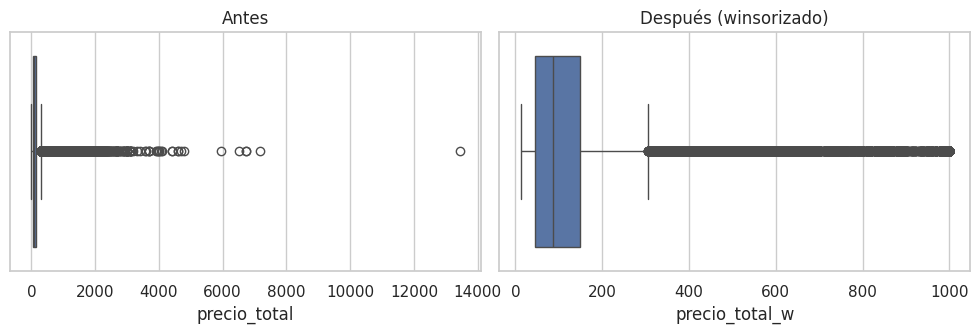

In [32]:
cols_outliers = ['precio_total', 'flete_total', 'product_weight_g']   # columnas a revisar (editar según consigna)

for c in cols_outliers:                                         # recorre cada columna
    serie = df_clean[c].dropna()                                # descarta nulos para calcular
    Q1, Q3 = serie.quantile(0.25), serie.quantile(0.75)         # cuartiles
    IQR = Q3 - Q1                                               # rango intercuartílico
    lim_inf, lim_sup = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR           # límites IQR
    out_iqr = ((serie < lim_inf) | (serie > lim_sup)).sum()     # outliers por IQR
    out_z = (np.abs(stats.zscore(serie)) > 3).sum()             # outliers por Z-Score
    print(f'{c:18s} | IQR [{lim_inf:.1f}, {lim_sup:.1f}] -> {out_iqr} | Z>3 -> {out_z}')

# Winsorización al 1% - 99% (crea una columna nueva y conserva la original)
for c in cols_outliers:                                         # recorre cada columna
    p1, p99 = df_clean[c].quantile(0.01), df_clean[c].quantile(0.99)   # percentiles 1 y 99
    df_clean[c + '_w'] = np.clip(df_clean[c], p1, p99)          # acota los extremos
    print(f'{c}: máximo antes {df_clean[c].max():.1f} | después {df_clean[c + "_w"].max():.1f}')

# Gráfico antes / después de la primera columna
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))                 # dos paneles
sns.boxplot(x=df_clean[cols_outliers[0]], ax=ax[0]); ax[0].set_title('Antes')
sns.boxplot(x=df_clean[cols_outliers[0] + '_w'], ax=ax[1]); ax[1].set_title('Después (winsorizado)')
plt.tight_layout(); plt.show()

## Paso 5: Partición y aislamiento de datos (Train-Test Split)
**Regla de oro:** dividir **antes** de escalar, codificar o balancear.
En Olist las órdenes son transacciones en el tiempo, por lo que se recomienda **partición temporal** (entrenar con el pasado, evaluar con el futuro). Si se usa partición aleatoria, `stratify=y` mantiene la proporción de clases.

In [33]:
from sklearn.model_selection import train_test_split            # función de partición

# Creamos la columna objetivo 'is_delayed' de forma segura desde df_work (que contiene las fechas originales antes de la auditoría de leakage)
df_clean['is_delayed'] = (df_work['order_delivered_customer_date'] > df_work['order_estimated_delivery_date']).astype(int)

# Columnas predictoras: se definen según la consigna (se toman de la configuración E.0)
FEATURES = NUM_STD + NUM_POW + CAT_NOMINAL + CAT_ORDINAL        # lista total de predictoras

if USAR_SPLIT_TEMPORAL:                                         # --- partición cronológica ---
    es_train = df_clean[COL_FECHA_SPLIT] < pd.Timestamp(FECHA_CORTE)   # True = pasado (train)
    X_train, y_train = df_clean.loc[es_train, FEATURES], df_clean.loc[es_train, TARGET]    # set de entrenamiento
    X_test, y_test = df_clean.loc[~es_train, FEATURES], df_clean.loc[~es_train, TARGET]    # set de prueba
else:                                                           # --- partición aleatoria estratificada ---
    X_train, X_test, y_train, y_test = train_test_split(
        df_clean[FEATURES], df_clean[TARGET], test_size=0.2, random_state=42, stratify=df_clean[TARGET])

print(f'Train: {X_train.shape} | Test: {X_test.shape}')         # tamaños
print(pd.DataFrame({'train': y_train.value_counts(normalize=True),
                    'test': y_test.value_counts(normalize=True)}).round(4))  # proporción del target por conjunto

Train: (80450, 12) | Test: (18991, 12)
            train  test
is_delayed             
0           0.915 0.946
1           0.085 0.054


## Paso 6: Transformación de variables e integración en Pipeline
`fit()` **exclusivamente** sobre train. Yeo-Johnson para asimétricas, StandardScaler para simétricas, OneHot para nominales, Ordinal para ordenadas.

In [34]:
from sklearn.compose import ColumnTransformer                   # aplica transformaciones distintas por columna
from sklearn.pipeline import Pipeline                           # encadena pasos
from sklearn.impute import SimpleImputer                        # imputación aprendida solo con train
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, PowerTransformer

transformers = []                                               # lista de transformaciones activas
if NUM_STD:                                                     # numéricas simétricas
    transformers.append(('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                                          ('sc', StandardScaler())]), NUM_STD))
if NUM_POW:                                                     # numéricas asimétricas
    transformers.append(('pow', Pipeline([('imp', SimpleImputer(strategy='median')),
                                          ('pt', PowerTransformer(method='yeo-johnson'))]), NUM_POW))
if CAT_NOMINAL:                                                 # categóricas nominales
    transformers.append(('cat_nom', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), CAT_NOMINAL))
if CAT_ORDINAL:                                                 # categóricas ordinales
    transformers.append(('cat_ord', OrdinalEncoder(categories=ORDEN_ORDINAL, handle_unknown='use_encoded_value',
                                                   unknown_value=-1), CAT_ORDINAL))

preprocessor = ColumnTransformer(transformers=transformers)     # ensambla el preprocesador

# Para evitar conflictos con Pandas 'NAType' en OneHotEncoder, forzamos casteo a tipo string clásico de Python en las categóricas
X_train_clean = X_train.copy()
X_test_clean = X_test.copy()

for col in CAT_NOMINAL + CAT_ORDINAL:
    if col in X_train_clean.columns:
        X_train_clean[col] = X_train_clean[col].astype(str)
        X_test_clean[col] = X_test_clean[col].astype(str)

X_train_trans = preprocessor.fit_transform(X_train_clean)       # AJUSTA y transforma solo con train
X_test_trans = preprocessor.transform(X_test_clean)             # solo transforma test (sin ajustar)

print('Columnas resultantes:', list(preprocessor.get_feature_names_out()))
print('Forma Train:', X_train_trans.shape, '| Forma Test:', X_test_trans.shape)

Columnas resultantes: ['num__product_photos_qty', 'num__product_name_lenght', 'num__product_description_lenght', 'pow__precio_total_w', 'pow__flete_total_w', 'pow__product_weight_g_w', 'pow__pago_total', 'pow__cuotas_max', 'pow__n_items', 'cat_nom__payment_type_boleto', 'cat_nom__payment_type_credit_card', 'cat_nom__payment_type_debit_card', 'cat_nom__payment_type_voucher', 'cat_nom__customer_state_al', 'cat_nom__customer_state_am', 'cat_nom__customer_state_ap', 'cat_nom__customer_state_ba', 'cat_nom__customer_state_ce', 'cat_nom__customer_state_df', 'cat_nom__customer_state_es', 'cat_nom__customer_state_go', 'cat_nom__customer_state_ma', 'cat_nom__customer_state_mg', 'cat_nom__customer_state_ms', 'cat_nom__customer_state_mt', 'cat_nom__customer_state_pa', 'cat_nom__customer_state_pb', 'cat_nom__customer_state_pe', 'cat_nom__customer_state_pi', 'cat_nom__customer_state_pr', 'cat_nom__customer_state_rj', 'cat_nom__customer_state_rn', 'cat_nom__customer_state_ro', 'cat_nom__customer_stat

## Paso 7: Balanceo (SMOTE), entrenamiento y evaluación
- SMOTE **solo** sobre train. El test conserva su distribución real.
- Modelo *cost-sensitive* (`class_weight='balanced'`) y *moving threshold* para ganar Recall.
- Métricas: **PR-AUC** (contra la prevalencia como línea base) y **F1** de la clase positiva; la accuracy es engañosa con clases desbalanceadas.

In [35]:
from imblearn.over_sampling import SMOTE                        # sobremuestreo sintético
from sklearn.ensemble import RandomForestClassifier             # modelo base
from sklearn.metrics import (classification_report, confusion_matrix, precision_recall_curve, auc,
                             roc_auc_score, f1_score, precision_score, recall_score)

print('Train antes de SMOTE:', dict(pd.Series(y_train).value_counts()))
smote = SMOTE(random_state=42)                                  # define SMOTE
X_train_res, y_train_res = smote.fit_resample(X_train_trans, y_train)   # balancea SOLO train
print('Train después de SMOTE:', dict(pd.Series(y_train_res).value_counts()))

clf = RandomForestClassifier(random_state=42, class_weight='balanced', n_jobs=-1)  # modelo cost-sensitive
clf.fit(X_train_res, y_train_res)                               # entrena con train balanceado

y_probs = clf.predict_proba(X_test_trans)[:, 1]                 # probabilidad de clase positiva en test
y_pred = (y_probs >= 0.25).astype(int)                          # umbral movido de 0.50 a 0.25

print('\nMatriz de confusión (umbral 0.25):\n', confusion_matrix(y_test, y_pred))
print('\n', classification_report(y_test, y_pred))             # precision, recall y f1 por clase

precision, recall, _ = precision_recall_curve(y_test, y_probs)  # puntos de la curva PR
pr_auc = auc(recall, precision)                                 # área bajo la curva PR
print(f'PR-AUC: {pr_auc:.4f} | ROC-AUC: {roc_auc_score(y_test, y_probs):.4f}')
print(f'Línea base (azar) = prevalencia: {np.mean(y_test):.4f}')

Train antes de SMOTE: {0: np.int64(73642), 1: np.int64(6808)}
Train después de SMOTE: {0: np.int64(73642), 1: np.int64(73642)}

Matriz de confusión (umbral 0.25):
 [[12855  5117]
 [  693   326]]

               precision    recall  f1-score   support

           0       0.95      0.72      0.82     17972
           1       0.06      0.32      0.10      1019

    accuracy                           0.69     18991
   macro avg       0.50      0.52      0.46     18991
weighted avg       0.90      0.69      0.78     18991

PR-AUC: 0.0578 | ROC-AUC: 0.5254
Línea base (azar) = prevalencia: 0.0537


 umbral  precision  recall    f1  positivos_predichos
  0.100      0.056   0.742 0.105                13402
  0.150      0.058   0.577 0.105                10219
  0.200      0.059   0.433 0.104                 7483
  0.250      0.060   0.320 0.101                 5443
  0.300      0.058   0.222 0.091                 3921
  0.400      0.061   0.117 0.080                 1949
  0.500      0.064   0.058 0.061                  922


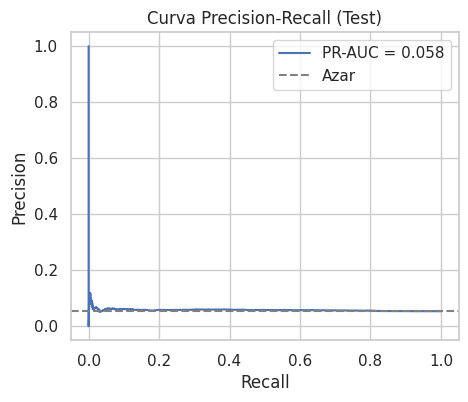

In [36]:
# Comparación de umbrales sobre test
filas = []                                                      # acumula resultados
for t in [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]:            # umbrales a probar
    pred = (y_probs >= t).astype(int)                           # predicción con ese umbral
    filas.append({'umbral': t,
                  'precision': precision_score(y_test, pred, zero_division=0),
                  'recall': recall_score(y_test, pred),
                  'f1': f1_score(y_test, pred, zero_division=0),
                  'positivos_predichos': pred.sum()})
print(pd.DataFrame(filas).round(3).to_string(index=False))      # tabla comparativa

plt.figure(figsize=(5, 4))                                      # gráfico de la curva PR
plt.plot(recall, precision, label=f'PR-AUC = {pr_auc:.3f}')     # curva del modelo
plt.axhline(np.mean(y_test), ls='--', c='gray', label='Azar')   # línea base
plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title('Curva Precision-Recall (Test)')
plt.legend(); plt.show()

## Lista de comprobación final (checklist pre-entrenamiento)
| Verificación | Requisito técnico | Riesgo si no se cumple |
|---|---|---|
| ☐ | Partición Train/Test realizada **antes** de transformar y balancear | Data Leakage |
| ☐ | Partición temporal (o estratificada) según corresponda | Distorsión del target / fuga del futuro |
| ☐ | `fit()` solo en Train (ColumnTransformer, SMOTE, modelo) | Contaminación estadística |
| ☐ | `handle_unknown` definido en los encoders | Errores en ejecución |
| ☐ | SMOTE exclusivamente sobre Train | Métricas falsas |
| ☐ | Evaluación con PR-AUC / F1 y no solo Accuracy | Paradoja de la exactitud |
| ☐ | Variables de fuga eliminadas (`COLS_LEAKAGE`) | Rendimiento irreal en producción |

#BLOQUE F - Informe de mejoras realizado por alumna Gargiulo Yessica Camila.

>FECHA: 28/10/2026

## Aciertos Estructurales y Lógicos

La "Regla de oro" sobre la inmutabilidad de los DataFrames raw_* asegura la trazabilidad y previene la corrupción accidental de los datos base a lo largo del análisis.

La estrategia de uniones (Bloque D) es analíticamente precisa: pre-agregar ítems y pagos a nivel de orden y conservar solo la reseña más reciente evita la duplicación del identificador único order_id durante el ensamblaje del DataFrame maestro.

La división en bloques secuenciales (A-E) crea un flujo reproducible, mientras que la parametrización de variables de fuga y fecha de corte en el Bloque E demuestra un enfoque metodológico maduro para modelos predictivos.

El esquema relacional documenta correctamente las claves primarias (PK) y foráneas (FK), identificando de antemano excepciones estructurales de las tablas


## Hallazgos de Revisión: Errores, Faltas y Riesgos

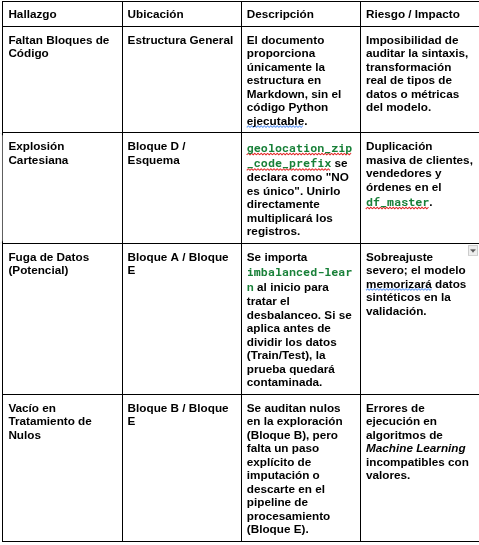


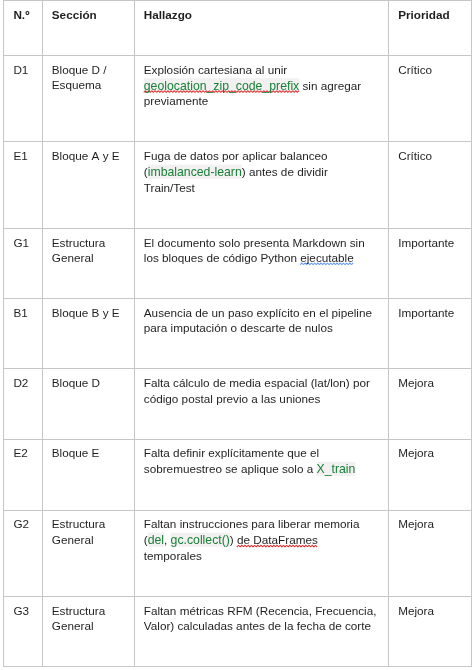

## Posibilidades de Mejora
Agregación Geoespacial Previa: Antes de ejecutar los joins en el Bloque D, agrupa la tabla geolocation por el prefijo del código postal y calcula la media espacial (latitud y longitud). Esto convertirá la clave en única y permitirá una relación 1 a 1 segura con clientes y vendedores.

Control Estricto de SMOTE/Balanceo: Define explícitamente en el Bloque E que cualquier técnica de sobremuestreo (proveniente de imbalanced-learn) se ejecutará estrictamente sobre el conjunto de entrenamiento (X_train, y_train), dejando el conjunto de prueba inalterado.

Optimización de Memoria: Al trabajar con aproximadamente 100.000 órdenes y 9 tablas, incorpora instrucciones explícitas para usar del o gc.collect() sobre los DataFrames de trabajo temporales (items, payments) una vez que el df_master esté completamente consolidado.

Ingeniería de Características RFM: Al tratarse de un modelo transaccional de e-commerce, incorpora explícitamente en el pipeline métricas calculadas de Recencia, Frecuencia y Valor Monetario a nivel de cliente antes de aplicar la fecha de corte.


## Conclusión
La plantilla presenta una arquitectura conceptual sólida y defensiva, destacando por su rigor en el aislamiento de los datos crudos y su meticulosa planificación para evitar la duplicación de órdenes al integrar tablas transaccionales de 1 a N. El principal punto de fallo estructural reside en la integración de la tabla geoespacial, cuya falta de exclusividad romperá la integridad del DataFrame maestro si no se aborda mediante una etapa previa de agregación. Resolviendo esta anomalía espacial y garantizando la ubicación metodológica correcta para el balanceo de clases y la imputación de nulos, el esqueleto se convertirá en un flujo de trabajo analítico de grado de producción.

#BLOQUE G: Segunda Parte con Machine Learning: TP Integrador
>FECHA: 04/11/2026




##Consignas:

Desarrollar las consignas de al menos 1 de los siguientes documentos:

https://docs.google.com/document/d/1gKGo0AsCOngrE0SLbzmKZHnmR_xH6cs-/edit

https://docs.google.com/document/d/1rmnM_mRQujx05B0-Ekte2eXLQwUc8spDca0ezHTEICA/edit?tab=t.0

El segundo link debería estar avanzado en el procesmiento.

Fecha límite para promoción: 13/11/26.

---
# BLOQUE H – Resolución de las consignas del documento.

**Cómo trabajamos a partir de acá (política del Colab que se mantiene):**
* Los `raw_*` **nunca se modifican**. Todo se hace sobre copias (`df_f`, `df_ent`, `df_c1`, …).
* Cada línea de código lleva su comentario explicando qué hace y por qué.
* Primero se aclara **qué ya estaba resuelto**, luego se resuelve **solo lo que falta**, y al final hay un **informe** con los resultados.

## H.0 Auditoría previa: ¿qué ya está resuelto, qué está incompleto y qué falta?

### H.0.1 Los 8 puntos del *Informe de mejoras* contrastados con el código que ya existe

| N° | Hallazgo del informe | Estado en este Colab | Dónde se ve | Qué hacemos ahora |
|---|---|---|---|---|
| D1 | Explosión cartesiana por `geolocation_zip_code_prefix` | ✅ **Ya resuelto** | Celda D.1 (`geo_agg`: media de lat/lng por prefijo) y control `is_unique` | Solo lo verificamos en H.0.2 |
| D2 | Falta la media espacial por código postal | ✅ **Ya resuelto** | Misma celda D.1 | Solo lo verificamos |
| E1 | Fuga de datos al balancear con `imbalanced-learn` antes del split | ✅ **Ya resuelto** | Paso 5 divide primero; Paso 7 aplica `SMOTE` solo a `X_train_trans` | Lo repetimos con un `Pipeline` de *imblearn* (H.7) |
| E2 | Definir que el sobremuestreo solo toca `X_train` | ✅ **Resuelto en el código**, ❌ no escrito como regla | Paso 7 | Regla escrita en H.1 + `assert` en H.7 |
| G1 | Faltaban los bloques de código Python | ✅ **Ya resuelto** | Bloques A–E tienen código ejecutable estaba incluso antes de que se realice el informe | — |
| B1 | Paso explícito de imputación/descarte de nulos | 🟡 **Parcial** | Paso 3 imputa y Paso 6 usa `SimpleImputer`, pero medianas y percentiles se calcularon con **todo** el dataset (lo admite la nota del Paso 3) | Imputación y winsorización **aprendidas solo con train** (H.5) |
| G2 | Liberar memoria (`del`, `gc.collect()`) | ❌ **Pendiente** | — | Celda H.4.1 |
| G3 | Métricas **RFM** calculadas antes de la fecha de corte | ❌ **Pendiente** | — | Caso 4 (H.10) con corte temporal |

### H.0.2 Las consignas del documento Word del TP, contrastadas con el Colab

| Consigna del Word | Estado | Detalle |
|---|---|---|
| **A** – Agregar ítems (SUM precio, SUM flete, COUNT) y pagos (SUM valor, tipo dominante) y unir las 7 tablas | ✅ **Ya resuelto** (Bloque D) | **Falta un complemento**: el peso y el volumen **totales de la orden** (Proyecto, punto 4.B). Hoy solo se conserva el producto del *primer* ítem → H.2 |
| **B** – Fechas de entrega: marcar `canceled`/`unavailable` | ❌ Pendiente | `order_status` se elimina en `COLS_LEAKAGE` antes de poder marcarlo → H.3 |
| **B** – Reseñas nulas → `"sin_comentario"` | 🟡 Parcial | El Paso 3 la aplica **después** de haber borrado esas columnas por *leakage*, así que crea columnas nuevas llenas de `"sin_comentario"` (columnas «fantasma») → H.3 |
| **B** – Categoría nula → `"desconocido"` | ✅ **Ya resuelto** | Celda D.2 y Paso 3 |
| **C** – Métricas temporales (`dias_retraso`, tiempo real/estimado) | ❌ Pendiente | → H.4 |
| **C** – Distancia Haversine cliente–vendedor | ❌ Pendiente | Las coordenadas ya están unidas en el maestro (`cliente_lat`, `vendedor_lat`, …) → H.4 |
| **C** – Volumen y ratio flete/precio | ❌ Pendiente | → H.4 |
| **D** – One-Hot / Target Encoding y escalado | 🟡 Parcial | Paso 6 ya hace One-Hot + Yeo-Johnson/StandardScaler. Falta **Target Encoding** (categoría de producto), **RobustScaler/log(1+x)** y usar las variables nuevas → H.5 |
| **Caso 1** – Retrasos (clasificación) | 🟡 Parcial | `is_delayed` y un Random Forest ya existen (Pasos 5–7). Faltan: baseline logístico, XGBoost, LightGBM y las variables pedidas (distancia, volumen, mes, día de la semana) → H.7 |
| **Caso 2** – Satisfacción del cliente | ❌ Pendiente | → H.8 |
| **Caso 3** – Ventas / series temporales | ❌ Pendiente | → H.9 |
| **Caso 4** – Segmentación RFM | ❌ Pendiente | → H.10 |
| **Sección 4** – División temporal | ✅ **Ya resuelto** | `FECHA_CORTE = 2018-06-01` coincide con el Word (train hasta mayo 2018). Falta fijar la ventana de test (jun–ago 2018) → H.6 |
| **Proyecto** – Predicción del *lead time* (regresión) | ❌ Pendiente | → H.11 |

### H.0.3 Defectos adicionales que encontre en el codigo pero que no figuraban en el informe de mejoras

1. **Las órdenes no entregadas quedan etiquetadas como `is_delayed = 0`** (en el Paso 5, `NaT > fecha` da `False`). Esto contamina sobre todo el *test*, que incluye pedidos aún sin entregar a fines de 2018.
2. **Columnas fantasma de reseñas** (ver consigna B arriba).
3. **`order_status` se descarta antes de filtrar** canceladas/no disponibles.
4. **Peso y dimensiones solo del primer ítem** de cada orden, cuando el Word pide la **suma** por orden.
5. **El modelo del Paso 7 rinde casi como el azar** (ROC-AUC = 0,52; PR-AUC = 0,057 contra una prevalencia de 0,054): faltaban las variables predictoras que pide la consigna (distancia, volumen, mes, día de la semana).

In [37]:
# ---------- F.0.2b  Comprobaciones automáticas de lo que decimos que "ya estaba resuelto" ----------
def marca(cond):                                                  # convierte True/False en un símbolo fácil de leer
    return '✔' if cond else '✘'                                   # ✔ = se cumple | ✘ = no se cumple

chequeos = {                                                      # diccionario: descripción de la verificación -> resultado (True/False)
    'raw_orders conserva las fechas como texto (el original no se modificó)':
        not pd.api.types.is_datetime64_any_dtype(raw_orders['order_purchase_timestamp']),   # si fuera fecha, alguien lo habría convertido
    'raw_* y copias de trabajo son objetos distintos en memoria':
        (orders is not raw_orders) and (items is not raw_items) and (reviews is not raw_reviews),  # `is not` compara identidad de objeto
    'orders (copia) sigue idéntica a raw_orders':
        orders.equals(raw_orders),                                # .equals compara contenido celda por celda
    'D1/D2: geo_agg tiene exactamente 1 fila por prefijo postal':
        geo_agg['geolocation_zip_code_prefix'].is_unique,         # clave única => el join no multiplica filas
    'D1: df_master tiene 1 fila por orden (sin explosión cartesiana)':
        (len(df_master) == len(raw_orders)) and df_master['order_id'].is_unique,  # mismas filas que orders y order_id sin repetir
    'D.1: reviews_agg conserva una sola reseña por orden':
        reviews_agg['order_id'].is_unique,                        # se había quedado con la última reseña
    'E.0: FECHA_CORTE definida (partición temporal)':
        'FECHA_CORTE' in globals(),                               # existe la variable de configuración
}
resumen_chequeos = pd.DataFrame({'verificación': list(chequeos.keys()),             # tabla con descripción
                                 'resultado': [marca(v) for v in chequeos.values()]})  # y su símbolo
display(resumen_chequeos)                                         # muestra la tabla

# ---- Medición del defecto 1: órdenes sin entregar que el Paso 5 etiquetó como "no atrasadas" ----
sin_entrega = df_work['order_delivered_customer_date'].isna()     # True si la orden no tiene fecha de entrega
etiqueta_vieja = (df_work['order_delivered_customer_date'] > df_work['order_estimated_delivery_date']).astype(int)  # así se calculó en el Paso 5
n_mal = int((sin_entrega & (etiqueta_vieja == 0)).sum())          # sin entrega Y etiquetadas con 0
print(f'Defecto 1 -> órdenes sin entrega etiquetadas como is_delayed = 0: {n_mal:,} de {len(df_work):,} ({n_mal/len(df_work):.1%})')

,verificación,resultado
0,raw_orders conserva las fechas como texto (el ...,✔
1,raw_* y copias de trabajo son objetos distinto...,✔
2,orders (copia) sigue idéntica a raw_orders,✔
3,D1/D2: geo_agg tiene exactamente 1 fila por pr...,✔
4,D1: df_master tiene 1 fila por orden (sin expl...,✔
5,D.1: reviews_agg conserva una sola reseña por ...,✔
6,E.0: FECHA_CORTE definida (partición temporal),✔


Defecto 1 -> órdenes sin entrega etiquetadas como is_delayed = 0: 2,965 de 99,441 (3.0%)


## H.1 Configuración y librerías del Bloque H

**Reglas que quedan escritas (respuesta a E2 y B1):**
1. Toda técnica de remuestreo (`SMOTE`) se ajusta **solo con el conjunto de entrenamiento**; el *test* conserva su distribución real.
2. Imputación, winsorización, escalado y codificación se **aprenden solo con train** (dentro de un `Pipeline`) y luego se aplican a test.
3. La partición es **cronológica** (nada del futuro entra al entrenamiento).

In [38]:
# Instala (si hiciera falta) las librerías de modelado; en Colab suelen venir instaladas. -q = salida silenciosa
!pip install -q lightgbm xgboost statsmodels prophet imbalanced-learn

In [39]:
import gc                                                        # recolector de basura (liberar memoria, mejora G2)
import logging                                                    # para bajar el "ruido" de mensajes de Prophet
from sklearn.base import BaseEstimator, TransformerMixin, clone   # clases base para crear transformadores propios y clonar modelos
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor  # preprocesado por columnas / regresor con objetivo transformado
from sklearn.pipeline import Pipeline                             # encadena pasos (preprocesado + modelo)
from sklearn.impute import SimpleImputer                          # imputa nulos con una estadística aprendida
from sklearn.preprocessing import (StandardScaler, RobustScaler, OneHotEncoder,
                                   FunctionTransformer, TargetEncoder)  # escaladores y codificadores
from sklearn.linear_model import LogisticRegression, Ridge        # modelos lineales (baselines)
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
                              HistGradientBoostingClassifier, HistGradientBoostingRegressor)  # árboles / boosting de sklearn
from sklearn.naive_bayes import ComplementNB                      # Naive Bayes para texto (Caso 2 NLP)
from sklearn.feature_extraction.text import TfidfVectorizer       # convierte texto en vectores TF-IDF
from sklearn.dummy import DummyRegressor                          # regresor "tonto" (media) como referencia
from sklearn.inspection import permutation_importance             # importancia de variables por permutación
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering  # algoritmos de clustering (Caso 4)
from sklearn.neighbors import NearestNeighbors                    # para estimar el parámetro eps de DBSCAN
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score, recall_score,
                             precision_recall_curve, roc_curve, accuracy_score, confusion_matrix,
                             ConfusionMatrixDisplay, mean_absolute_error, mean_squared_error, r2_score,
                             silhouette_score, davies_bouldin_score)  # todas las métricas pedidas en el Word

# ---- Librerías opcionales: si no están instaladas, el notebook sigue funcionando con un sustituto ----
try:                                                              # intenta importar LightGBM
    import lightgbm as lgb                                        # boosting rápido
    HAY_LGBM = True                                               # bandera: disponible
except ImportError:                                               # si no está instalada...
    HAY_LGBM = False                                              # ...se anota que no hay
try:                                                              # intenta importar XGBoost
    import xgboost as xgb                                         # boosting clásico
    HAY_XGB = True                                                # bandera: disponible
except ImportError:
    HAY_XGB = False
try:                                                              # intenta importar Prophet (series temporales de Meta)
    from prophet import Prophet                                   # modelo aditivo de series temporales
    logging.getLogger('cmdstanpy').setLevel(logging.WARNING)      # silencia mensajes internos
    logging.getLogger('prophet').setLevel(logging.WARNING)        # silencia mensajes internos
    HAY_PROPHET = True
except Exception:                                                 # Exception: Prophet puede fallar por motivos distintos al import
    HAY_PROPHET = False
try:                                                              # intenta importar SARIMAX
    from statsmodels.tsa.statespace.sarimax import SARIMAX        # ARIMA estacional con variables exógenas
    HAY_SARIMAX = True
except ImportError:
    HAY_SARIMAX = False
try:                                                              # intenta importar el Pipeline que admite SMOTE
    from imblearn.pipeline import Pipeline as ImbPipeline         # Pipeline de imblearn (aplica SMOTE solo al fit)
    from imblearn.over_sampling import SMOTE                      # sobremuestreo sintético
    HAY_IMB = True
except ImportError:
    HAY_IMB = False
print({'LightGBM': HAY_LGBM, 'XGBoost': HAY_XGB, 'Prophet': HAY_PROPHET, 'SARIMAX': HAY_SARIMAX, 'imblearn': HAY_IMB})  # resumen de disponibilidad

# ---- Parámetros del Bloque F (se pueden editar en un solo lugar) ----
SEMILLA = 42                                                      # semilla aleatoria para que todo sea reproducible
F_INI_TRAIN = pd.Timestamp('2016-10-01')                          # inicio del entrenamiento (Word: octubre de 2016)
F_CORTE = pd.Timestamp(FECHA_CORTE)                               # fecha de corte definida en E.0 (2018-06-01): train < corte <= test
F_FIN_TEST = pd.Timestamp('2018-09-01')                           # fin del test (Word: hasta agosto de 2018)
MAX_DIAS_ENTREGA = 120                                            # tiempo de entrega máximo aceptado (Word: 90-120 días)
RESULTADOS = {}                                                   # diccionario donde cada caso guarda sus resultados para el informe final

{'LightGBM': True, 'XGBoost': True, 'Prophet': True, 'SARIMAX': True, 'imblearn': True}


## H.2 Consigna A (complemento): peso y volumen **totales** de cada orden

El Bloque D ya agregó ítems y pagos, pero conservó solo el producto del **primer ítem** para traer peso y dimensiones.
El Proyecto pide el **peso total** y el **volumen total** del paquete, es decir, sumar **todos** los ítems de la orden.
Se calcula a nivel de ítem y se agrega a nivel de orden (así no se multiplican filas).

In [40]:
# 1) Copia de trabajo del maestro: df_work y los raw_* quedan intactos
df_f = df_work.copy()                                             # df_f será el DataFrame sobre el que trabaja todo el Bloque F

# 2) Une cada ítem con las dimensiones y el peso de SU producto (no solo el del primer ítem)
items_prod = items.merge(                                         # items = copia de trabajo de order_items
    products_en[['product_id', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']],  # solo columnas físicas
    on='product_id', how='left')                                  # left: conserva ítems aunque el producto no tenga datos

# 3) Volumen de cada ítem en cm3 = largo x alto x ancho (fórmula del Word)
items_prod['volumen_cm3'] = (items_prod['product_length_cm'] * items_prod['product_height_cm'] * items_prod['product_width_cm'])

# 4) Agrega a nivel de orden: suma de pesos y de volúmenes (min_count=1: si todos son nulos el resultado es nulo, no 0)
fisicas = (items_prod.groupby('order_id')[['product_weight_g', 'volumen_cm3']]   # agrupa por orden las dos columnas a sumar
           .sum(min_count=1)                                      # suma ignorando nulos pero exigiendo al menos 1 dato
           .rename(columns={'product_weight_g': 'peso_total_g', 'volumen_cm3': 'volumen_total_cm3'})  # nombres claros
           .reset_index())                                        # order_id vuelve a ser columna

# 5) Une al DataFrame de trabajo (how='left' conserva todas las órdenes) y controla que no se dupliquen filas
n_antes = len(df_f)                                               # filas antes del join
df_f = df_f.merge(fisicas, on='order_id', how='left')             # agrega peso_total_g y volumen_total_cm3
assert len(df_f) == n_antes and df_f['order_id'].is_unique        # control: mismas filas y order_id único
print('df_f:', df_f.shape, '| órdenes con peso total:', df_f['peso_total_g'].notna().sum())  # resumen

df_f: (99441, 46) | órdenes con peso total: 98650


## H.3 Consigna B: valores faltantes (con las correcciones de los defectos 1–3)

* **Estandarizamos el texto** (minúsculas, sin espacios) *antes* de comparar estados o categorías.
* **Fechas de entrega:** en vez de borrar o dejar nulos sin explicación, **marcamos** las órdenes (`es_entregada`, `es_cancelada_o_no_disponible`). Las no entregadas no tienen `is_delayed` ni tiempo de entrega: su valor será nulo (no 0).
* **Reseñas:** los nulos se rellenan con `"sin_comentario"`, pero **sobre el dataset de trabajo que sí conserva esas columnas** (se evitan las columnas fantasma).
* **Categorías:** nulas → `"desconocido"`.

In [41]:
# 1) Estandariza texto y rellena categorías nulas de las columnas categóricas del modelado
cols_cat = ['order_status', 'customer_state', 'seller_state', 'payment_type', 'product_category_name_english']  # columnas de texto categórico
for c in cols_cat:                                                # recorre cada columna
    df_f[c] = (df_f[c].astype('string')                           # tipo texto de pandas (admite nulos)
               .str.strip().str.lower()                           # quita espacios y pasa a minúscula
               .fillna('desconocido')                             # nulo -> "desconocido" (cubre también la consigna de categorías)
               .astype(object))                                   # vuelve a object (lo que esperan los codificadores)

# 2) Marcas de entrega: en lugar de descartar, dejamos registrado el motivo
df_f['es_entregada'] = (df_f['order_status'] == 'delivered') & df_f['order_delivered_customer_date'].notna()  # entregada de verdad
df_f['es_cancelada_o_no_disponible'] = df_f['order_status'].isin(['canceled', 'unavailable'])   # estados sin fecha de entrega por definición
display(pd.crosstab(df_f['order_status'], df_f['order_delivered_customer_date'].notna(), margins=True)
        .rename(columns={False: 'sin fecha entrega', True: 'con fecha entrega'}))   # cruce estado x fecha de entrega

# 3) Reseñas: nulos -> "sin_comentario" (consigna B), ahora sobre columnas que SÍ existen en df_f
df_f['review_comment_title'] = df_f['review_comment_title'].fillna('sin_comentario')      # título nulo -> marca
df_f['review_comment_message'] = df_f['review_comment_message'].fillna('sin_comentario')  # mensaje nulo -> marca

# 4) Control: ya no quedan nulos en las columnas tratadas
print('Nulos restantes en columnas tratadas:\n',
      df_f[cols_cat + ['review_comment_title', 'review_comment_message']].isna().sum().to_string())
print('\nÓrdenes entregadas:', int(df_f['es_entregada'].sum()),
      '| canceladas/no disponibles:', int(df_f['es_cancelada_o_no_disponible'].sum()))

order_delivered_customer_date,sin fecha entrega,con fecha entrega,All
order_status,,,
approved,2,0,2
canceled,619,6,625
created,5,0,5
delivered,8,96470,96478
invoiced,314,0,314
processing,301,0,301
shipped,1107,0,1107
unavailable,609,0,609
All,2965,96476,99441


Nulos restantes en columnas tratadas:
 order_status                     0
customer_state                   0
seller_state                     0
payment_type                     0
product_category_name_english    0
review_comment_title             0
review_comment_message           0

Órdenes entregadas: 96470 | canceladas/no disponibles: 1234


## H.4 Consigna C: ingeniería de características

Fórmulas del Word (los tiempos se expresan en **días**, dividiendo la diferencia de fechas por 24 horas):

| Variable | Fórmula |
|---|---|
| `tiempo_entrega_real_dias` (**y** del Proyecto) | (`order_delivered_customer_date` − `order_purchase_timestamp`) / 24 h |
| `tiempo_estimado_dias` | (`order_estimated_delivery_date` − `order_purchase_timestamp`) / 24 h |
| `dias_retraso` | `order_delivered_customer_date` − `order_estimated_delivery_date` (**> 0 = llegó tarde**) |
| `is_delayed` | 1 si `dias_retraso > 0`, 0 si no; **nulo** si no hubo entrega |
| `distancia_km` | Haversine entre vendedor y comprador |
| `mismo_estado` | 1 si `customer_state == seller_state` |
| `volumen_total_cm3` / `_dm3` | largo × alto × ancho (sumado por orden) / 1000 |
| `ratio_flete_precio` | `flete_total / precio_total` |
| Temporales | día de la semana (0–6), hora (0–23), mes (1–12), fin de semana |

In [42]:
UN_DIA = pd.Timedelta(days=1)                                     # "24 horas" para convertir diferencias de fechas en días (número decimal)

# ---- Métricas temporales ----
df_f['tiempo_entrega_real_dias'] = (df_f['order_delivered_customer_date'] - df_f['order_purchase_timestamp']) / UN_DIA   # y del Proyecto
df_f['tiempo_estimado_dias'] = (df_f['order_estimated_delivery_date'] - df_f['order_purchase_timestamp']) / UN_DIA       # promesa de la plataforma
df_f['dias_retraso'] = (df_f['order_delivered_customer_date'] - df_f['order_estimated_delivery_date']) / UN_DIA          # > 0 = tarde
df_f['is_delayed'] = np.where(df_f['dias_retraso'].notna(),       # si hay fecha de entrega...
                              (df_f['dias_retraso'] > 0).astype(float),   # ...1.0 si llegó tarde, 0.0 si no
                              np.nan)                             # si NO hubo entrega -> nulo (corrige el defecto 1)

# ---- Distancia de Haversine (distancia sobre la esfera terrestre, en km) ----
def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0088                                                 # radio medio de la Tierra en km
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])  # pasa grados a radianes
    dlat = lat2 - lat1                                            # diferencia de latitudes
    dlon = lon2 - lon1                                            # diferencia de longitudes
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2   # término "a" de la fórmula
    return 2 * R * np.arcsin(np.sqrt(np.clip(a, 0, 1)))           # distancia = 2R·asin(√a); clip evita errores numéricos

df_f['distancia_km'] = haversine_km(df_f['vendedor_lat'], df_f['vendedor_lng'],
                                    df_f['cliente_lat'], df_f['cliente_lng'])   # vendedor principal -> comprador
df_f['mismo_estado'] = (df_f['customer_state'] == df_f['seller_state']).astype(int)   # 1 si comprador y vendedor están en el mismo estado

# ---- Métricas físicas y financieras ----
df_f['volumen_total_dm3'] = df_f['volumen_total_cm3'] / 1000     # cm3 -> dm3 (litros), escala más manejable
df_f['ratio_flete_precio'] = df_f['flete_total'] / df_f['precio_total'].where(df_f['precio_total'] > 0)  # evita dividir por 0

# ---- Variables temporales de la compra ----
df_f['dia_semana'] = df_f['order_purchase_timestamp'].dt.dayofweek    # 0 = lunes ... 6 = domingo
df_f['hora'] = df_f['order_purchase_timestamp'].dt.hour               # 0 a 23
df_f['mes'] = df_f['order_purchase_timestamp'].dt.month               # 1 a 12
df_f['es_fin_de_semana'] = (df_f['dia_semana'] >= 5).astype(int)      # 1 = sábado o domingo

# ---- Subconjunto de órdenes entregadas (base de los Casos 1, 2 y del Proyecto) ----
df_ent = df_f[df_f['es_entregada']].copy()                        # solo órdenes con entrega efectiva
df_ent['is_delayed'] = df_ent['is_delayed'].astype(int)           # ahora sí es 0/1 sin nulos

cols_nuevas = ['tiempo_entrega_real_dias', 'tiempo_estimado_dias', 'dias_retraso', 'distancia_km',
               'volumen_total_dm3', 'peso_total_g', 'ratio_flete_precio']   # variables nuevas para resumir
display(df_ent[cols_nuevas].describe().T)                         # resumen estadístico para detectar valores raros
print(f'Entregadas: {len(df_ent):,} | % con retraso: {df_ent["is_delayed"].mean():.2%} | '
      f'sin distancia (prefijo sin coordenadas): {df_ent["distancia_km"].isna().mean():.2%}')

,count,mean,std,min,25%,50%,75%,max
tiempo_entrega_real_dias,"96,470.000",12.558,9.546,0.533,6.766,10.217,15.720,209.629
tiempo_estimado_dias,"96,470.000",23.736,8.761,2.008,18.330,23.231,28.408,155.135
dias_retraso,"96,470.000",-11.178,10.184,-146.016,-16.244,-11.948,-6.390,188.975
distancia_km,"95,992.000",600.758,593.713,0.000,185.934,433.873,798.550,"8,677.924"
volumen_total_dm3,"96,454.000",17.332,30.144,0.168,2.964,7.254,19.866,"1,476.000"
peso_total_g,"96,454.000","2,386.868","4,770.110",0.000,300.000,750.000,"2,050.000","184,400.000"
ratio_flete_precio,"96,470.000",0.308,0.312,0.000,0.132,0.224,0.381,21.447


Entregadas: 96,470 | % con retraso: 8.11% | sin distancia (prefijo sin coordenadas): 0.50%


### H.4.1 Mejora G2: liberar memoria

Con el maestro ya consolidado y las variables físicas calculadas, las tablas temporales (`items`, `payments`, `reviews`, `geolocation` y los agregados intermedios) ya no se usan.
Se eliminan con `del` y se llama a `gc.collect()`.
Los **`raw_*` se conservan** (son los originales). Si se quisiera volver a ejecutar el Bloque D, bastaría con correr de nuevo el Bloque C (que recrea las copias).

In [43]:
def mb(obj):                                                      # función auxiliar: tamaño en memoria de un DataFrame, en MB
    return obj.memory_usage(deep=True).sum() / 1024 ** 2          # deep=True cuenta también el texto

temporales = ['items', 'payments', 'reviews', 'geolocation',      # copias de trabajo ya utilizadas
              'items_agg', 'items_principal', 'payments_agg', 'pago_dominante',   # agregados intermedios
              'reviews_agg', 'geo_agg', 'geo_cliente', 'geo_vendedor',            # reseñas y geolocalización agregadas
              'items_prod', 'fisicas']                            # auxiliares de F.2

liberado = 0.0                                                    # acumulador de MB liberados
for nombre in temporales:                                         # recorre cada nombre de variable
    if nombre in globals():                                       # solo si todavía existe (permite re-ejecutar la celda)
        liberado += mb(globals()[nombre])                         # suma su tamaño
        del globals()[nombre]                                     # elimina la variable
gc.collect()                                                      # fuerza al recolector a devolver la memoria
print(f'Memoria liberada: ~{liberado:,.0f} MB | raw_* conservados: {len([v for v in globals() if v.startswith("raw_")])} tablas')

Memoria liberada: ~377 MB | raw_* conservados: 9 tablas


## H.5 Consigna D: codificación y escalado (todo aprendido **solo con train**)

Se arma **un único preprocesador reutilizable** (`ColumnTransformer`) para los Casos 1–2 y el Proyecto:

| Tipo de variable | Tratamiento | Por qué |
|---|---|---|
| Numéricas **sesgadas** (distancia, peso, volumen, precio, flete, ratio) | imputar mediana → **winsorizar p1–p99** → **log(1+x)** → **RobustScaler** | colas largas; el RobustScaler usa mediana/IQR y resiste outliers |
| Numéricas con signo o simétricas (`dias_retraso`, hora, mes, cuotas, …) | imputar mediana → **StandardScaler** (o RobustScaler si tienen colas) | no admiten log |
| Binarias (`mismo_estado`, fin de semana) | pasan sin cambios | ya valen 0/1 |
| Categóricas de **baja cardinalidad** (estados) | **One-Hot** (`handle_unknown='ignore'`) | ~27 categorías |
| Categórica de **alta cardinalidad** (categoría de producto, ~74) | **Target Encoding** (con validación cruzada interna) | evita ~74 columnas y no filtra el objetivo |

Los percentiles de la winsorización y las medianas del imputador se calculan **solo con las filas de train** gracias al `Pipeline`.

In [44]:
class Winsorizador(BaseEstimator, TransformerMixin):
    """Acota cada columna entre los percentiles p_inf y p_sup APRENDIDOS EN TRAIN (no elimina filas)."""
    def __init__(self, p_inf=1, p_sup=99):                        # percentiles de corte (1% y 99%, como pide el Word)
        self.p_inf = p_inf                                        # percentil inferior
        self.p_sup = p_sup                                        # percentil superior
    def fit(self, X, y=None):                                     # fit: aprende los límites SOLO con los datos de entrenamiento
        X = np.asarray(X, dtype=float)                            # pasa a matriz numérica
        self.lim_inf_ = np.nanpercentile(X, self.p_inf, axis=0)   # límite inferior de cada columna
        self.lim_sup_ = np.nanpercentile(X, self.p_sup, axis=0)   # límite superior de cada columna
        return self                                               # convención sklearn: devolver el propio objeto
    def transform(self, X):                                       # transform: aplica los límites aprendidos (a train y a test)
        return np.clip(np.asarray(X, dtype=float), self.lim_inf_, self.lim_sup_)  # recorta los extremos
    def get_feature_names_out(self, input_features=None):         # nombres de salida = nombres de entrada
        return np.asarray(input_features, dtype=object)

def log1p_seguro(x):                                              # log(1+x) protegido contra valores negativos
    return np.log1p(np.clip(x, 0, None))                          # clip a 0 evita NaN si apareciera un negativo

def armar_preprocesador(sesgadas=(), simetricas=(), robustas=(), binarias=(), cat_ohe=(), cat_te=()):
    """Devuelve un ColumnTransformer sin ajustar (se ajusta dentro del Pipeline, solo con train)."""
    pasos = []                                                    # lista de (nombre, transformador, columnas)
    if sesgadas:                                                  # variables positivas con cola larga
        pasos.append(('sesgadas', Pipeline([
            ('imp', SimpleImputer(strategy='median')),            # 1) imputa nulos con la mediana de train
            ('win', Winsorizador(1, 99)),                         # 2) acota percentiles 1%-99%
            ('log', FunctionTransformer(log1p_seguro, feature_names_out='one-to-one')),  # 3) log(1+x)
            ('rob', RobustScaler())]), list(sesgadas)))           # 4) centra con la mediana y escala con el IQR
    if simetricas:                                                # variables sin cola marcada
        pasos.append(('simetricas', Pipeline([
            ('imp', SimpleImputer(strategy='median')),            # imputa con la mediana
            ('sc', StandardScaler())]), list(simetricas)))        # estandariza: media 0 y desvío 1
    if robustas:                                                  # variables con signo y colas (ej.: días de retraso)
        pasos.append(('robustas', Pipeline([
            ('imp', SimpleImputer(strategy='median')),            # imputa con la mediana
            ('win', Winsorizador(1, 99)),                         # acota extremos
            ('rob', RobustScaler())]), list(robustas)))           # escala robusta
    if binarias:                                                  # 0/1
        pasos.append(('binarias', 'passthrough', list(binarias))) # se dejan pasar sin tocar
    if cat_ohe:                                                   # categóricas de pocas categorías
        pasos.append(('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False), list(cat_ohe)))  # una columna por categoría
    if cat_te:                                                    # categóricas con muchas categorías
        pasos.append(('te', TargetEncoder(random_state=SEMILLA), list(cat_te)))  # reemplaza la categoría por la media (suavizada) del objetivo
    return ColumnTransformer(pasos, remainder='drop')             # remainder='drop': lo no listado se descarta

# ---- Listas de variables reutilizables ----
SESGADAS = ['distancia_km', 'peso_total_g', 'volumen_total_dm3', 'precio_total', 'flete_total', 'ratio_flete_precio']  # positivas y asimétricas
BINARIAS = ['mismo_estado', 'es_fin_de_semana']                   # 0/1
CAT_OHE = ['customer_state', 'seller_state']                      # estados (baja cardinalidad)
CAT_TE = ['product_category_name_english']                         # categoría de producto (alta cardinalidad)
print('Preprocesador listo. Ejemplo:', [p[0] for p in armar_preprocesador(SESGADAS, ['hora'], [], BINARIAS, CAT_OHE, CAT_TE).transformers])

Preprocesador listo. Ejemplo: ['sesgadas', 'simetricas', 'binarias', 'ohe', 'te']


## H.6 Sección 4 del Word: estrategia de validación (división temporal)

* **Train:** compras desde octubre de 2016 hasta mayo de 2018 (`< FECHA_CORTE`).
* **Test:** compras de junio a agosto de 2018 (`>= FECHA_CORTE` y `< F_FIN_TEST`).
* Nunca se usa `train_test_split` aleatorio. Un `assert` comprueba que **todo el train es anterior al test**.

In [45]:
def dividir_temporal(df, col_fecha='order_purchase_timestamp'):
    """Parte un DataFrame en (train, test) respetando el orden cronológico."""
    es_train = (df[col_fecha] >= F_INI_TRAIN) & (df[col_fecha] < F_CORTE)     # pasado: oct-2016 .. mayo-2018
    es_test = (df[col_fecha] >= F_CORTE) & (df[col_fecha] < F_FIN_TEST)       # futuro: jun-2018 .. ago-2018
    tr, te = df[es_train].copy(), df[es_test].copy()              # copias independientes
    assert tr[col_fecha].max() < te[col_fecha].min(), 'FUGA TEMPORAL: el train llega más allá del inicio del test'  # control anti-fuga
    return tr, te                                                 # devuelve ambos conjuntos

tr_demo, te_demo = dividir_temporal(df_ent)                       # prueba con las órdenes entregadas
resumen_split = pd.DataFrame({                                    # tabla resumen de la partición
    'conjunto': ['train', 'test'],
    'desde': [tr_demo['order_purchase_timestamp'].min(), te_demo['order_purchase_timestamp'].min()],   # primera compra
    'hasta': [tr_demo['order_purchase_timestamp'].max(), te_demo['order_purchase_timestamp'].max()],   # última compra
    'filas': [len(tr_demo), len(te_demo)],                        # tamaño
    '% con retraso': [tr_demo['is_delayed'].mean() * 100, te_demo['is_delayed'].mean() * 100]})   # prevalencia del retraso
display(resumen_split.round(2))                                   # muestra la tabla
print(f'Proporción train/test: {len(tr_demo)/(len(tr_demo)+len(te_demo)):.0%} / {len(te_demo)/(len(tr_demo)+len(te_demo)):.0%}')
del tr_demo, te_demo                                              # libera las copias de demostración

,conjunto,desde,hasta,filas,% con retraso
0,train,2016-10-03 09:44:50,2018-05-31 23:51:24,77866,8.740
1,test,2018-06-01 00:39:55,2018-08-29 15:00:37,18603,5.480


Proporción train/test: 81% / 19%


## H.7 Caso 1 – Predicción de retrasos en la entrega (clasificación binaria)

**Qué ya existía:** `is_delayed` y un Random Forest con SMOTE (Pasos 5–7), que rindió **ROC-AUC = 0,52** (≈ azar).
**Qué falta según el Word:** las variables predictoras pedidas, el baseline de **Regresión Logística**, y los modelos **XGBoost** y **LightGBM**.

* **Objetivo:** `is_delayed = 1` si `dias_retraso > 0`. Se entrena **solo con órdenes entregadas** (corrige el defecto 1).
* **Predictoras (solo información conocida al comprar):** distancia cliente–vendedor, peso y volumen, estado de origen/destino, mes y día de la semana, valor del flete.
* **Desbalance:** se usa ponderación de clases (*cost-sensitive*) en todos los modelos, y se agrega una variante `Regresión Logística + SMOTE` mediante un `Pipeline` de *imblearn*, que garantiza que **SMOTE solo se ajusta con train** (mejoras E1/E2).
* **Umbral de decisión:** se elige maximizando F1 en una **ventana de validación temporal** (los 2 últimos meses de train), nunca mirando el test.
* **Métricas:** ROC-AUC, **PR-AUC** (la más informativa con clases desbalanceadas; el azar vale la prevalencia) y F1.

In [46]:
def mejor_umbral_f1(y_true, prob):
    """Devuelve el umbral de probabilidad que maximiza el F1 sobre (y_true, prob)."""
    prec, rec, umbrales = precision_recall_curve(y_true, prob)    # precisión y recall para cada umbral posible
    f1 = 2 * prec * rec / (prec + rec + 1e-12)                    # F1 = media armónica (1e-12 evita dividir por 0)
    return float(umbrales[np.argmax(f1[:-1])])                    # el último punto de la curva no tiene umbral asociado

def armar_pipe(clf, prep):
    """Encadena preprocesador + modelo en un único Pipeline (todo se ajusta solo con train)."""
    return Pipeline([('prep', clone(prep)), ('clf', clf)])        # clone: cada modelo recibe un preprocesador "limpio"

def evaluar_clasificador(nombre, pipe, df_tr, df_te, cols, target):
    """Entrena, elige el umbral con validación temporal y evalúa en test. Devuelve (fila de métricas, probabilidades de test)."""
    corte_val = F_CORTE - pd.DateOffset(months=2)                 # los últimos 2 meses de train se reservan para elegir el umbral
    es_fit = df_tr['order_purchase_timestamp'] < corte_val        # True = parte "más antigua" de train
    p_val_pipe = clone(pipe)                                      # copia del modelo para la etapa de validación
    p_val_pipe.fit(df_tr.loc[es_fit, cols], df_tr.loc[es_fit, target])   # entrena con lo más antiguo
    prob_val = p_val_pipe.predict_proba(df_tr.loc[~es_fit, cols])[:, 1]  # probabilidades sobre los 2 meses de validación
    umbral = mejor_umbral_f1(df_tr.loc[~es_fit, target], prob_val)       # umbral óptimo según validación
    pipe.fit(df_tr[cols], df_tr[target])                          # reentrena con TODO el train (SMOTE, si lo hay, solo actúa acá)
    prob = pipe.predict_proba(df_te[cols])[:, 1]                  # probabilidad de retraso en test
    assert len(prob) == len(df_te)                                # el test NO fue remuestreado: mismas filas que el original
    y = df_te[target].values                                      # etiqueta real del test
    pred = (prob >= umbral).astype(int)                           # clase predicha con el umbral elegido
    fila = {'modelo': nombre,
            'ROC-AUC': roc_auc_score(y, prob),                    # capacidad de ordenar positivos sobre negativos
            'PR-AUC': average_precision_score(y, prob),           # área bajo la curva precisión-recall
            'F1 (umbral 0.5)': f1_score(y, (prob >= .5).astype(int), zero_division=0),
            'F1 (umbral óptimo)': f1_score(y, pred, zero_division=0),
            'umbral': umbral,
            'precisión': precision_score(y, pred, zero_division=0),
            'recall': recall_score(y, pred, zero_division=0)}
    return fila, prob

# ---- Datos del Caso 1 ----
FEAT_C1_SESG = ['distancia_km', 'peso_total_g', 'volumen_total_dm3', 'flete_total']   # numéricas asimétricas
FEAT_C1_SIM = ['mes', 'dia_semana']                               # calendario de la compra
FEAT_C1 = FEAT_C1_SESG + FEAT_C1_SIM + CAT_OHE                    # lista total de predictoras
TARGET_C1 = 'is_delayed'                                          # objetivo binario
df_c1_tr, df_c1_te = dividir_temporal(df_ent)                     # partición cronológica (solo entregadas)
prep_c1 = armar_preprocesador(sesgadas=FEAT_C1_SESG, simetricas=FEAT_C1_SIM, cat_ohe=CAT_OHE)   # preprocesador del caso
prev_tr, prev_te = df_c1_tr[TARGET_C1].mean(), df_c1_te[TARGET_C1].mean()   # prevalencia del retraso en train y test
print(f'Train: {len(df_c1_tr):,} (retrasos {prev_tr:.2%}) | Test: {len(df_c1_te):,} (retrasos {prev_te:.2%})')
peso_pos = (df_c1_tr[TARGET_C1] == 0).sum() / max((df_c1_tr[TARGET_C1] == 1).sum(), 1)   # nº negativos / nº positivos (para XGBoost)

# ---- Modelos a comparar ----
modelos_c1 = {                                                    # nombre -> Pipeline completo
    'Regresión Logística (baseline)': armar_pipe(LogisticRegression(max_iter=1000, class_weight='balanced'), prep_c1),
    'Random Forest': armar_pipe(RandomForestClassifier(n_estimators=200, min_samples_leaf=20, class_weight='balanced_subsample',
                                                       n_jobs=-1, random_state=SEMILLA), prep_c1)}
if HAY_IMB:                                                       # variante con SMOTE dentro del Pipeline (solo se aplica en fit, nunca en test)
    modelos_c1['Reg. Logística + SMOTE'] = ImbPipeline([('prep', clone(prep_c1)), ('smote', SMOTE(random_state=SEMILLA)),
                                                        ('clf', LogisticRegression(max_iter=1000))])
if HAY_XGB:                                                       # XGBoost si está instalado
    modelos_c1['XGBoost'] = armar_pipe(xgb.XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                                                         colsample_bytree=0.8, scale_pos_weight=peso_pos, eval_metric='aucpr',
                                                         n_jobs=-1, random_state=SEMILLA), prep_c1)
if HAY_LGBM:                                                      # LightGBM si está instalado
    modelos_c1['LightGBM'] = armar_pipe(lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8,
                                                           subsample_freq=1, colsample_bytree=0.8, class_weight='balanced',
                                                           n_jobs=-1, random_state=SEMILLA, verbose=-1), prep_c1)
if not (HAY_XGB and HAY_LGBM):                                    # sustituto si faltara alguna librería de boosting
    modelos_c1['HistGradientBoosting (sustituto)'] = armar_pipe(HistGradientBoostingClassifier(
        max_iter=300, learning_rate=0.05, class_weight='balanced', random_state=SEMILLA), prep_c1)

# ---- Entrenamiento y evaluación ----
filas_c1, probs_c1 = [], {}                                       # acumuladores de métricas y de probabilidades
for nombre, pipe in modelos_c1.items():                           # recorre los modelos
    try:                                                          # si una librería falla, se informa y se sigue con las demás
        fila, prob = evaluar_clasificador(nombre, pipe, df_c1_tr, df_c1_te, FEAT_C1, TARGET_C1)   # entrena y evalúa
    except Exception as e:                                        # captura cualquier error de ese modelo
        print(f'AVISO: {nombre} no pudo entrenarse ({type(e).__name__}: {e})')
        continue                                                  # pasa al siguiente modelo
    filas_c1.append(fila); probs_c1[nombre] = prob                # guarda resultados
tabla_c1 = pd.DataFrame(filas_c1).set_index('modelo')             # tabla comparativa
print(f'Referencia: el azar tiene PR-AUC = prevalencia = {prev_te:.4f} y ROC-AUC = 0.5000')
display(tabla_c1.round(4))                                        # muestra la tabla
RESULTADOS['caso1'] = {'tabla': tabla_c1, 'prevalencia_test': prev_te}   # guarda para el informe final

Train: 77,866 (retrasos 8.74%) | Test: 18,603 (retrasos 5.48%)
Referencia: el azar tiene PR-AUC = prevalencia = 0.0548 y ROC-AUC = 0.5000


,ROC-AUC,PR-AUC,F1 (umbral 0.5),F1 (umbral óptimo),umbral,precisión,recall
modelo,,,,,,,
Regresión Logística (baseline),0.414,0.054,0.078,0.074,0.594,0.047,0.174
Random Forest,0.527,0.061,0.068,0.078,0.411,0.053,0.150
Reg. Logística + SMOTE,0.419,0.054,0.076,0.072,0.607,0.047,0.156
XGBoost,0.566,0.067,0.074,0.064,0.537,0.101,0.047
LightGBM,0.558,0.068,0.066,0.060,0.512,0.075,0.050


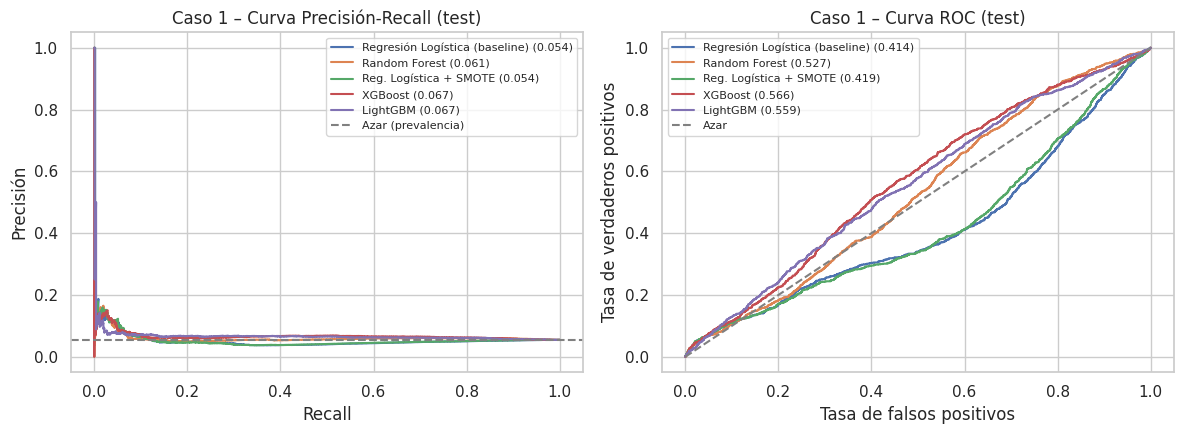

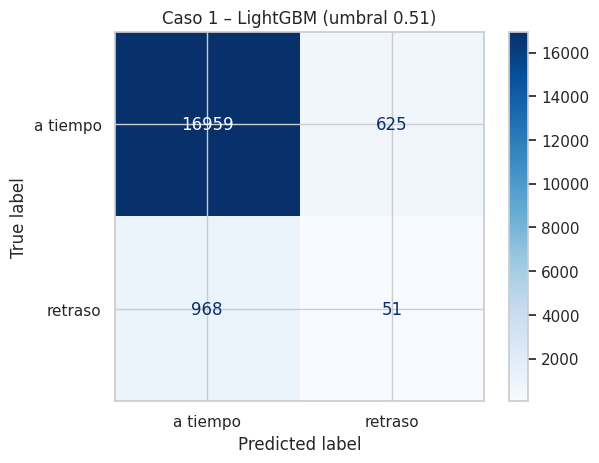

In [47]:
# ---- Curvas Precisión-Recall y ROC de todos los modelos (sobre test) ----
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))                 # dos paneles lado a lado
y_te_c1 = df_c1_te[TARGET_C1].values                              # etiquetas reales de test
for nombre, prob in probs_c1.items():                             # una curva por modelo
    pr, rc, _ = precision_recall_curve(y_te_c1, prob)             # puntos de la curva PR
    ejes[0].plot(rc, pr, label=f'{nombre} ({tabla_c1.loc[nombre, "PR-AUC"]:.3f})')   # curva con su PR-AUC en la leyenda
    fpr, tpr, _ = roc_curve(y_te_c1, prob)                        # puntos de la curva ROC
    ejes[1].plot(fpr, tpr, label=f'{nombre} ({tabla_c1.loc[nombre, "ROC-AUC"]:.3f})')  # curva con su ROC-AUC
ejes[0].axhline(prev_te, ls='--', c='gray', label='Azar (prevalencia)')   # línea base de PR
ejes[0].set(xlabel='Recall', ylabel='Precisión', title='Caso 1 – Curva Precisión-Recall (test)')   # títulos PR
ejes[1].plot([0, 1], [0, 1], ls='--', c='gray', label='Azar')     # línea base de ROC
ejes[1].set(xlabel='Tasa de falsos positivos', ylabel='Tasa de verdaderos positivos', title='Caso 1 – Curva ROC (test)')
for e in ejes: e.legend(fontsize=8)                               # leyendas
plt.tight_layout(); plt.show()                                    # acomoda y muestra

# ---- Matriz de confusión del mejor modelo (por PR-AUC) con su umbral óptimo ----
mejor_c1 = tabla_c1['PR-AUC'].idxmax()                            # nombre del mejor modelo
pred_mejor = (probs_c1[mejor_c1] >= tabla_c1.loc[mejor_c1, 'umbral']).astype(int)   # predicción con su umbral
ConfusionMatrixDisplay(confusion_matrix(y_te_c1, pred_mejor), display_labels=['a tiempo', 'retraso']).plot(cmap='Blues')
plt.title(f'Caso 1 – {mejor_c1} (umbral {tabla_c1.loc[mejor_c1, "umbral"]:.2f})'); plt.show()   # título con el umbral
RESULTADOS['caso1']['mejor'] = mejor_c1                           # guarda el mejor modelo para el informe

## H.8 Caso 2 – Predicción de la satisfacción del cliente (clasificación / NLP)

* **Objetivo:** `review_negativa = 1` si `review_score` ∈ {1, 2, 3}; `0` si ∈ {4, 5}.
* **Predictoras (Word):** días de retraso, diferencia precio − flete, número de ítems e **historial del vendedor**.
* **Historial del vendedor sin fuga:** para cada orden se usa el puntaje promedio de las reseñas **anteriores** del mismo vendedor (acumulado menos la propia reseña, ordenado por fecha de entrega) y se **suaviza** hacia el promedio global de train para vendedores con pocas ventas.
* **Métricas pedidas:** Accuracy y **F1 ponderado**. Se agregan ROC-AUC y F1 de la clase negativa, porque la *accuracy* sola es engañosa si hay desbalance (se muestra también la regla ingenua «todos positivos»).
* **Variante NLP (opcional):** TF-IDF sobre `review_comment_message` (portugués) con Naive Bayes y Regresión Logística.

In [48]:
from sklearn.dummy import DummyClassifier                         # clasificador "tonto" para tener una referencia mínima

# ---- 1) Base del caso: órdenes entregadas que tienen reseña ----
df_c2 = df_ent[df_ent['review_score'].notna()].copy()             # sin reseña no hay objetivo
df_c2['review_negativa'] = (df_c2['review_score'] <= 3).astype(int)   # 1 = negativa (1-3 estrellas), 0 = positiva (4-5)
df_c2['dif_precio_flete'] = df_c2['precio_total'] - df_c2['flete_total']   # diferencia de precio vs. flete (puede ser negativa)

# ---- 2) Historial del vendedor SIN usar la propia reseña ni reseñas posteriores ----
df_c2 = df_c2.sort_values('order_delivered_customer_date').reset_index(drop=True)   # orden cronológico de entrega
grupo_vend = df_c2.groupby('seller_id')['review_score']           # puntajes agrupados por vendedor
suma_previa = grupo_vend.cumsum() - df_c2['review_score']         # suma acumulada MENOS la fila actual = solo reseñas anteriores
n_previas = grupo_vend.cumcount()                                 # cuántas reseñas anteriores tiene el vendedor (0 para la primera)
prior = df_c2.loc[df_c2['order_purchase_timestamp'] < F_CORTE, 'review_score'].mean()   # promedio global de train
K_SUAV = 5                                                        # "peso" del prior: equivale a 5 reseñas ficticias con el promedio global
df_c2['vend_hist_score'] = (suma_previa + K_SUAV * prior) / (n_previas + K_SUAV)   # promedio suavizado (shrinkage)
df_c2['vend_hist_n'] = n_previas                                  # cantidad de reseñas previas (confianza del promedio)

# ---- 3) Variables, partición temporal y preprocesador ----
FEAT_C2_ROB = ['dias_retraso', 'dif_precio_flete']                # con signo y colas -> RobustScaler
FEAT_C2_SESG = ['ratio_flete_precio', 'vend_hist_n']              # positivas y asimétricas -> log + RobustScaler
FEAT_C2_SIM = ['n_items', 'vend_hist_score']                      # estandarizadas
FEAT_C2 = FEAT_C2_ROB + FEAT_C2_SESG + FEAT_C2_SIM                # lista total
df_c2_tr, df_c2_te = dividir_temporal(df_c2)                      # partición cronológica
prep_c2 = armar_preprocesador(sesgadas=FEAT_C2_SESG, simetricas=FEAT_C2_SIM, robustas=FEAT_C2_ROB)   # preprocesador del caso
print(f'Train: {len(df_c2_tr):,} | Test: {len(df_c2_te):,} | % negativas en train: {df_c2_tr["review_negativa"].mean():.1%} | en test: {df_c2_te["review_negativa"].mean():.1%}')

# ---- 4) Función de evaluación (accuracy y F1 ponderado según el Word) ----
def evaluar_multi(nombre, pipe, X_tr, y_tr, X_te, y_te, binario=True):
    pipe.fit(X_tr, y_tr)                                          # entrena SOLO con train
    pred = pipe.predict(X_te)                                     # clase predicha en test
    fila = {'modelo': nombre,
            'Accuracy': accuracy_score(y_te, pred),               # % de aciertos
            'F1 ponderado': f1_score(y_te, pred, average='weighted', zero_division=0)}   # F1 promediado según frecuencia de clase
    if binario:                                                   # métricas extra solo para el caso binario
        fila['F1 clase negativa'] = f1_score(y_te, pred, pos_label=1, zero_division=0)   # qué tan bien detecta las reseñas negativas
        fila['ROC-AUC'] = roc_auc_score(y_te, pipe.predict_proba(X_te)[:, 1])             # ordenamiento por probabilidad
    return fila

# ---- 5) Modelos tabulares ----
modelos_c2 = {
    'Referencia: todo positivo': Pipeline([('clf', DummyClassifier(strategy='most_frequent'))]),   # regla ingenua
    'Regresión Logística': armar_pipe(LogisticRegression(max_iter=1000, class_weight='balanced'), prep_c2),
    'Random Forest': armar_pipe(RandomForestClassifier(n_estimators=200, min_samples_leaf=20, class_weight='balanced_subsample',
                                                       n_jobs=-1, random_state=SEMILLA), prep_c2)}
if HAY_LGBM:                                                      # LightGBM (recomendado en el Word)
    modelos_c2['LightGBM'] = armar_pipe(lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, class_weight='balanced',
                                                           n_jobs=-1, random_state=SEMILLA, verbose=-1), prep_c2)
else:                                                             # sustituto si no está instalado
    modelos_c2['HistGradientBoosting (sustituto)'] = armar_pipe(HistGradientBoostingClassifier(
        max_iter=300, learning_rate=0.05, class_weight='balanced', random_state=SEMILLA), prep_c2)

filas_c2 = []                                                     # acumulador de resultados
for nombre, pipe in modelos_c2.items():                           # recorre modelos
    try:                                                          # si un modelo falla, se informa y se sigue
        if nombre.startswith('Referencia'):                       # la referencia no usa preprocesador: recibe las columnas con relleno trivial
            X_tr_ref = df_c2_tr[FEAT_C2].fillna(0); X_te_ref = df_c2_te[FEAT_C2].fillna(0)   # relleno trivial
            filas_c2.append(evaluar_multi(nombre, pipe, X_tr_ref, df_c2_tr['review_negativa'], X_te_ref, df_c2_te['review_negativa']))
        else:
            filas_c2.append(evaluar_multi(nombre, pipe, df_c2_tr[FEAT_C2], df_c2_tr['review_negativa'],
                                          df_c2_te[FEAT_C2], df_c2_te['review_negativa']))
    except Exception as e:                                        # captura el error de ese modelo
        print(f'AVISO: {nombre} no pudo entrenarse ({type(e).__name__}: {e})')
tabla_c2 = pd.DataFrame(filas_c2).set_index('modelo')             # tabla comparativa
display(tabla_c2.round(4))                                        # muestra la tabla

Train: 77,303 | Test: 18,520 | % negativas en train: 22.1% | en test: 16.6%


,Accuracy,F1 ponderado,F1 clase negativa,ROC-AUC
modelo,,,,
Referencia: todo positivo,0.834,0.759,0.000,0.500
Regresión Logística,0.612,0.661,0.314,0.615
Random Forest,0.771,0.776,0.351,0.653
LightGBM,0.728,0.749,0.350,0.652


In [49]:
# ---- Variante NLP: TF-IDF sobre el comentario (solo reseñas que SÍ tienen texto) ----
STOP_PT = ['a', 'o', 'e', 'de', 'do', 'da', 'dos', 'das', 'em', 'um', 'uma', 'para', 'com', 'que', 'os', 'as', 'no', 'na',
           'por', 'foi', 'ao', 'ele', 'ela', 'se', 'eu', 'meu', 'minha', 'me', 'é', 'ou', 'pra', 'à', 'pelo', 'pela',
           'nos', 'nas', 'num', 'numa', 'tem', 'ser']             # stopwords básicas SIN negaciones (não, nunca) ni intensificadores (muito, mais)
df_txt = df_c2[df_c2['review_comment_message'] != 'sin_comentario'].copy()   # descarta las reseñas sin texto (marcadas en F.3)
tr_t, te_t = dividir_temporal(df_txt)                             # misma partición cronológica
print(f'Reseñas con texto -> train: {len(tr_t):,} | test: {len(te_t):,}')

def nuevo_tfidf():                                                # fábrica de vectorizadores (uno nuevo por modelo)
    return TfidfVectorizer(lowercase=True, strip_accents='unicode', ngram_range=(1, 2),   # palabras sueltas y pares de palabras
                           min_df=5, max_features=30000, stop_words=STOP_PT)              # ignora términos rarísimos

modelos_nlp = {
    'TF-IDF + Naive Bayes (Complement)': Pipeline([('tfidf', nuevo_tfidf()), ('clf', ComplementNB())]),
    'TF-IDF + Regresión Logística': Pipeline([('tfidf', nuevo_tfidf()),
                                              ('clf', LogisticRegression(max_iter=1000, class_weight='balanced'))])}
filas_nlp = []                                                    # acumulador
for nombre, pipe in modelos_nlp.items():                          # recorre los dos modelos de texto
    filas_nlp.append(evaluar_multi(nombre, pipe, tr_t['review_comment_message'], tr_t['review_negativa'],
                                   te_t['review_comment_message'], te_t['review_negativa']))   # entrena con train, evalúa en test
tabla_nlp = pd.DataFrame(filas_nlp).set_index('modelo')           # tabla de resultados del NLP binario
display(tabla_nlp.round(4))

# ---- Variante 5 clases: predecir el review_score exacto (1 a 5) ----
pipe_5 = Pipeline([('tfidf', nuevo_tfidf()), ('clf', LogisticRegression(max_iter=1000, class_weight='balanced'))])   # multinomial
fila_5 = evaluar_multi('TF-IDF + Reg. Logística (5 clases)', pipe_5, tr_t['review_comment_message'], tr_t['review_score'].astype(int),
                       te_t['review_comment_message'], te_t['review_score'].astype(int), binario=False)
print('5 clases ->', {k: (round(v, 4) if not isinstance(v, str) else v) for k, v in fila_5.items()})

# ---- ¿Qué palabras empujan hacia "reseña negativa"? (coeficientes del modelo logístico binario) ----
pipe_lr = modelos_nlp['TF-IDF + Regresión Logística']             # modelo ya entrenado
vocab = np.array(pipe_lr.named_steps['tfidf'].get_feature_names_out())   # vocabulario aprendido
coef = pipe_lr.named_steps['clf'].coef_[0]                        # peso de cada término (positivo = hacia "negativa")
orden = np.argsort(coef)                                          # índices de menor a mayor peso
print('Términos más ligados a reseña NEGATIVA :', list(vocab[orden[-10:]][::-1]))   # los 10 de mayor peso
print('Términos más ligados a reseña POSITIVA :', list(vocab[orden[:10]]))          # los 10 de menor peso
RESULTADOS['caso2'] = {'tabla': tabla_c2, 'tabla_nlp': tabla_nlp, 'fila_5': fila_5,
                       'neg_test': df_c2_te['review_negativa'].mean()}   # guarda para el informe

Reseñas con texto -> train: 31,777 | test: 7,120


,Accuracy,F1 ponderado,F1 clase negativa,ROC-AUC
modelo,,,,
TF-IDF + Naive Bayes (Complement),0.887,0.889,0.813,0.946
TF-IDF + Regresión Logística,0.896,0.898,0.824,0.950


5 clases -> {'modelo': 'TF-IDF + Reg. Logística (5 clases)', 'Accuracy': 0.6055, 'F1 ponderado': 0.6294}
Términos más ligados a reseña NEGATIVA : ['nao', 'nao recebi', 'comprei', 'nao recomendo', 'ruim', 'inferior', 'pessima', 'veio', 'pessimo', 'diferente']
Términos más ligados a reseña POSITIVA : ['parabens', 'antes', 'excelente', 'lindo', 'perfeito', 'amei', 'rapido', 'adorei', 'tudo', 'sempre']


## H.9 Caso 3 – Predicción de ventas y demanda temporal (series de tiempo)

* **Objetivo:** predecir las **órdenes diarias** (total del país y, como ejemplo de segmento, el estado de São Paulo). La función admite cualquier otro filtro (por ejemplo una categoría).
* **Qué se cuenta como venta:** órdenes por **fecha de compra**, excluyendo `canceled` y `unavailable`.
* **Partición:** train hasta el 31/05/2018, test desde el 01/06/2018 (≈ 12 semanas). El pronóstico se hace **de una sola vez sobre todo el horizonte** (no se corrige con datos reales a medida que pasan los días), que es el escenario más exigente y honesto.
* **Variables (para XGBoost):** *lags* de 7, 14, 21 y 28 días, medias y desvío móviles (calculados **solo con valores anteriores a `t − 7`**), día de la semana, día del mes, mes, feriados brasileños y eventos comerciales (Black Friday, Cyber Monday, Día de las Madres, Día de los Enamorados).
* **Modelos:** referencia (promedio de las últimas 4 semanas para el mismo día de la semana), **SARIMAX**, **Prophet** y **XGBoost** con *lags*. Como en test no se conocen los valores reales, XGBoost pronostica **de forma recursiva** (usa sus propias predicciones como *lags*).
* **Métricas:** MAE, RMSE y MAPE (el MAPE se calcula solo en días con ventas > 0).

In [50]:
# ---- Calendario brasileño (2016-2018) ----
feriados_fijos = ['01-01', '04-21', '05-01', '09-07', '10-12', '11-02', '11-15', '12-25']   # feriados nacionales de fecha fija (mes-día)
FERIADOS = [pd.Timestamp(f'{anio}-{md}') for anio in (2016, 2017, 2018) for md in feriados_fijos]   # los combina con cada año
FERIADOS += list(pd.to_datetime(['2017-02-27', '2017-02-28', '2018-02-12', '2018-02-13',    # Carnaval
                                 '2017-04-14', '2018-03-30',                                  # Viernes Santo
                                 '2017-06-15', '2018-05-31']))                                # Corpus Christi
BLACK_FRIDAY = list(pd.to_datetime(['2016-11-25', '2017-11-24', '2018-11-23',                # Black Friday
                                    '2017-11-27']))                                           # Cyber Monday 2017: picos de ventas MUY grandes
EVENTOS_MENORES = list(pd.to_datetime(['2017-05-14', '2018-05-13',                            # Día de las Madres (2º domingo de mayo)
                                       '2017-06-12', '2018-06-12']))                          # Día de los Enamorados (12/06): efecto leve
EVENTOS_COM = BLACK_FRIDAY + EVENTOS_MENORES                      # unión de ambos (se conserva el nombre por compatibilidad)
SET_FERIADOS, SET_BF, SET_EVENTOS = set(FERIADOS), set(BLACK_FRIDAY), set(EVENTOS_MENORES)       # sets: búsqueda instantánea de "¿esta fecha es feriado?"

SERIE_INI = pd.Timestamp('2017-01-01')                            # antes de 2017 hay muy pocas ventas (serie poco informativa)
SERIE_FIN = pd.Timestamp('2018-08-20')                            # últimos días completos del dataset (editar si se desea)

def serie_diaria(df, filtro=None):
    """Serie diaria de órdenes (por fecha de compra). filtro=(columna, valor) permite segmentar por estado, categoría, etc."""
    d = df[~df['es_cancelada_o_no_disponible']]                   # solo ventas "reales"
    if filtro is not None:                                        # si se pidió un segmento...
        d = d[d[filtro[0]] == filtro[1]]                          # ...se queda con esas filas
    por_dia = d.groupby(d['order_purchase_timestamp'].dt.normalize()).size()   # cuenta órdenes por día
    dias = pd.date_range(SERIE_INI, SERIE_FIN, freq='D')          # calendario completo, sin días faltantes
    return por_dia.reindex(dias, fill_value=0).astype(float)      # días sin ventas = 0

s_total = serie_diaria(df_f)                                      # serie total del país
print('Últimos 7 días de la serie (verificar que no estén incompletos):\n', s_total.tail(7).to_string())

def features_ts(fecha, s):
    """Variables de un día usando SOLO información de hace 7 días o más (permite pronosticar 1 semana adelante)."""
    f = {}                                                        # diccionario de variables
    for lag in (7, 14, 21, 28):                                   # rezagos pedidos
        f[f'lag_{lag}'] = s.get(fecha - pd.Timedelta(days=lag), np.nan)   # valor de hace "lag" días (nulo si no existe)
    v7 = s.loc[fecha - pd.Timedelta(days=13): fecha - pd.Timedelta(days=7)]    # ventana de 7 días que termina en t-7
    v28 = s.loc[fecha - pd.Timedelta(days=34): fecha - pd.Timedelta(days=7)]   # ventana de 28 días que termina en t-7
    f['media_7'] = v7.mean()                                      # media móvil de 7 días
    f['media_28'] = v28.mean()                                    # media móvil de 28 días
    f['desvio_7'] = v7.std()                                      # variabilidad reciente
    f['dia_semana'] = fecha.dayofweek                             # 0 = lunes ... 6 = domingo
    f['dia_mes'] = fecha.day                                      # día del mes
    f['mes'] = fecha.month                                        # mes del año
    f['es_feriado'] = int(fecha in SET_FERIADOS)                  # 1 si es feriado nacional
    f['es_black_friday'] = int(fecha in SET_BF)                   # 1 si es Black Friday / Cyber Monday (efecto enorme: va separado)
    f['es_evento'] = int(fecha in SET_EVENTOS)                    # 1 si es un evento comercial menor (Madres, Enamorados)
    return f

def mape(y, yhat):                                                # error porcentual absoluto medio, solo donde y > 0
    y, yhat = np.asarray(y, float), np.asarray(yhat, float)       # a arrays numéricos
    m = y > 0                                                     # evita dividir por cero
    return float(np.mean(np.abs((y[m] - yhat[m]) / y[m])) * 100)  # en porcentaje

def metricas_serie(nombre, y, yhat):                              # arma la fila de métricas del Word
    return {'modelo': nombre, 'MAE': mean_absolute_error(y, yhat),
            'RMSE': float(np.sqrt(mean_squared_error(y, yhat))), 'MAPE %': mape(y, yhat)}

Últimos 7 días de la serie (verificar que no estén incompletos):
 2018-08-14   312.000
2018-08-15   283.000
2018-08-16   316.000
2018-08-17   254.000
2018-08-18   196.000
2018-08-19   204.000
2018-08-20   252.000
Freq: D


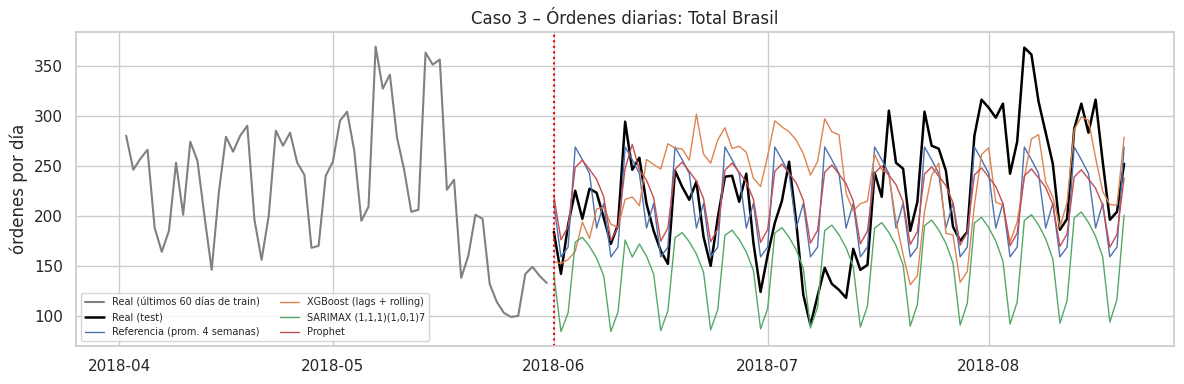

Resultados – Total Brasil (horizonte = test completo):


,MAE,RMSE,MAPE %
modelo,,,
Referencia (prom. 4 semanas),43.320,53.600,21.190
XGBoost (lags + rolling),57.800,70.060,31.320
"SARIMAX (1,1,1)(1,0,1)7",74.190,83.030,32.800
Prophet,40.660,51.580,20.570


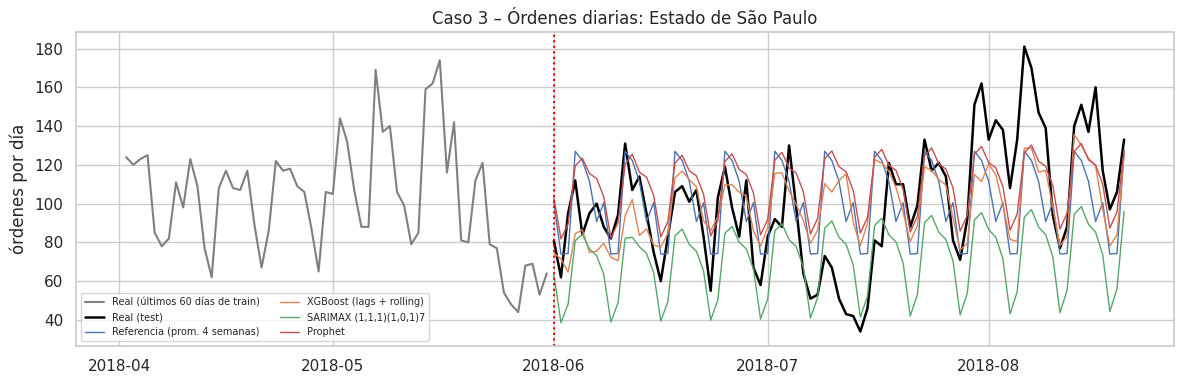

Resultados – São Paulo:


,MAE,RMSE,MAPE %
modelo,,,
Referencia (prom. 4 semanas),24.370,29.190,28.660
XGBoost (lags + rolling),20.740,26.230,25.620
"SARIMAX (1,1,1)(1,0,1)7",32.940,38.480,31.920
Prophet,22.200,28.110,29.260


In [51]:
def correr_caso3(filtro=None, etiqueta='Total Brasil'):
    """Entrena y evalúa los modelos de series de tiempo para el segmento indicado."""
    s = serie_diaria(df_f, filtro)                                # serie del segmento
    idx_tr = s.index[s.index < F_CORTE]                           # fechas de entrenamiento
    idx_te = s.index[s.index >= F_CORTE]                          # fechas de prueba
    y_tr, y_te = s.loc[idx_tr], s.loc[idx_te].values              # valores reales
    preds, filas = {}, []                                         # predicciones y métricas por modelo

    # --- Referencia: promedio de las últimas 4 semanas para el mismo día de la semana ---
    ult = y_tr.iloc[-28:]                                         # últimas 4 semanas de train
    prom_dow = ult.groupby(ult.index.dayofweek).mean()            # promedio por día de la semana
    preds['Referencia (prom. 4 semanas)'] = prom_dow.reindex(idx_te.dayofweek).values   # lo repite sobre todo el test

    # --- XGBoost (o sustituto) con lags, recursivo ---
    s_hist = s.copy(); s_hist.loc[idx_te] = np.nan                # serie "conocida": el test queda oculto
    X_tr = pd.DataFrame([features_ts(f, s_hist) for f in idx_tr], index=idx_tr)   # variables de cada día de train
    ok = X_tr['lag_28'].notna()                                   # descarta los primeros días sin 28 días de historia
    X_tr, y_fit = X_tr[ok], y_tr[ok]                              # filas válidas
    cols = list(X_tr.columns)                                     # orden de columnas del modelo
    if HAY_XGB:                                                   # modelo pedido por el Word
        reg = xgb.XGBRegressor(n_estimators=400, max_depth=3, learning_rate=0.05, subsample=0.8,
                               colsample_bytree=0.8, random_state=SEMILLA, n_jobs=-1)
        nombre_gb = 'XGBoost (lags + rolling)'
    else:                                                         # sustituto si no está instalado
        reg = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, max_depth=3, random_state=SEMILLA)
        nombre_gb = 'HistGradientBoosting (sustituto, lags + rolling)'
    reg.fit(X_tr[cols], y_fit)                                    # entrena SOLO con train
    s_rec = s_hist.copy()                                         # serie sobre la que se irán escribiendo las predicciones
    for fecha in idx_te:                                          # recorre el horizonte día por día
        x = pd.DataFrame([features_ts(fecha, s_rec)])[cols]       # variables del día (usa predicciones previas como lags)
        s_rec.loc[fecha] = max(float(reg.predict(x)[0]), 0.0)     # predice y guarda (las ventas no pueden ser negativas)
    preds[nombre_gb] = s_rec.loc[idx_te].values                   # predicciones del horizonte completo

    # --- SARIMAX con feriados/eventos como variables exógenas ---
    exog = pd.DataFrame({'feriado': [float(f in SET_FERIADOS) for f in s.index],
                         'black_friday': [float(f in SET_BF) for f in s.index],      # efecto enorme, variable propia
                         'evento': [float(f in SET_EVENTOS) for f in s.index]}, index=s.index)   # variables conocidas de antemano
    if HAY_SARIMAX:
        try:                                                      # SARIMAX puede fallar en convergencia: se protege
            mod = SARIMAX(y_tr, exog=exog.loc[idx_tr], order=(1, 1, 1), seasonal_order=(1, 0, 1, 7),   # estacionalidad semanal
                          enforce_stationarity=False, enforce_invertibility=False)
            res = mod.fit(disp=False, maxiter=200)                # ajusta el modelo
            preds['SARIMAX (1,1,1)(1,0,1)7'] = np.clip(res.forecast(steps=len(idx_te), exog=exog.loc[idx_te]).values, 0, None)
        except Exception as e:                                    # si falla, se informa y se sigue
            print('SARIMAX no pudo ajustarse:', e)

    # --- Prophet (Meta) ---
    if HAY_PROPHET:
        try:
            hol = pd.concat([pd.DataFrame({'holiday': 'feriado', 'ds': FERIADOS}),                # tabla de feriados
                             pd.DataFrame({'holiday': 'black_friday', 'ds': BLACK_FRIDAY}),            # Black Friday con su propio efecto
                             pd.DataFrame({'holiday': 'evento_menor', 'ds': EVENTOS_MENORES})])      # Madres/Enamorados con otro efecto
            m = Prophet(weekly_seasonality=True, yearly_seasonality=False, daily_seasonality=False,
                        holidays=hol, seasonality_mode='multiplicative')    # solo hay ~1,4 años: sin estacionalidad anual
            m.fit(pd.DataFrame({'ds': idx_tr, 'y': y_tr.values}))           # ajusta con train
            preds['Prophet'] = np.clip(m.predict(pd.DataFrame({'ds': idx_te}))['yhat'].values, 0, None)
        except Exception as e:
            print('Prophet no pudo ajustarse:', e)

    for nombre, yhat in preds.items():                            # métricas de cada modelo
        filas.append(metricas_serie(nombre, y_te, yhat))
    tabla = pd.DataFrame(filas).set_index('modelo')               # tabla comparativa

    # --- Gráfico: real vs. pronósticos ---
    plt.figure(figsize=(12, 4))
    plt.plot(s.loc[idx_tr[-60:]], c='gray', label='Real (últimos 60 días de train)')   # contexto
    plt.plot(idx_te, y_te, c='black', lw=1.8, label='Real (test)')                      # valores reales de test
    for nombre, yhat in preds.items():                            # una línea por modelo
        plt.plot(idx_te, yhat, lw=1, label=nombre)
    plt.axvline(F_CORTE, ls=':', c='red')                         # fecha de corte
    plt.title(f'Caso 3 – Órdenes diarias: {etiqueta}'); plt.ylabel('órdenes por día'); plt.legend(fontsize=7, ncol=2)
    plt.tight_layout(); plt.show()
    return tabla

tabla_c3_total = correr_caso3(None, 'Total Brasil')               # serie nacional
print('Resultados – Total Brasil (horizonte = test completo):'); display(tabla_c3_total.round(2))
tabla_c3_sp = correr_caso3(('customer_state', 'sp'), 'Estado de São Paulo')   # ejemplo de segmento: un estado
print('Resultados – São Paulo:'); display(tabla_c3_sp.round(2))
RESULTADOS['caso3'] = {'total': tabla_c3_total, 'sp': tabla_c3_sp}   # guarda para el informe

## H.10 Caso 4 – Segmentación de clientes con RFM (clustering no supervisado)

**Mejora G3:** las métricas RFM se calculan con una función que recibe una **fecha de snapshot** y usa **solo compras anteriores a esa fecha**:
* con `snapshot = FECHA_CORTE` se obtienen las variables de cliente que podrían alimentar un modelo supervisado **sin fuga del futuro**;
* con `snapshot = última compra + 1 día` se obtiene la foto actual para segmentar.

**Definiciones (por `customer_unique_id`, no por `customer_id`):** Recencia = días desde la última compra · Frecuencia = nº de órdenes · Monetario = gasto acumulado.

**Preparación:** en Olist cerca del 97 % de los clientes compró una sola vez y el gasto es muy asimétrico; por eso se aplica **log(1+x)** y luego `StandardScaler`.
**Elección de *k*:** se prueba k = 2…8 y se elige el de mayor Silhouette **con k ≥ 3**, porque con k = 2 el algoritmo solo separa «compró una vez» de «volvió a comprar» (el 97 % vs. el 3 %), lo cual es cierto pero poco accionable.
**Algoritmos:** K-Means (con elección de *k*), DBSCAN y Clustering Jerárquico (Ward). **Métricas:** Silhouette (más alto = mejor) y Davies-Bouldin (más bajo = mejor).

In [52]:
def calcular_rfm(df, fecha_snapshot):
    """RFM por cliente usando SOLO compras anteriores a fecha_snapshot (sin mirar el futuro)."""
    d = df[(~df['es_cancelada_o_no_disponible']) & (df['order_purchase_timestamp'] < fecha_snapshot)].copy()   # compras válidas y previas
    d['monto'] = d['pago_total'].fillna(d['precio_total'] + d['flete_total']).fillna(0)   # gasto de la orden (pagos; si falta, precio + flete)
    rfm = (d.groupby('customer_unique_id')                        # una fila por persona real
           .agg(ultima_compra=('order_purchase_timestamp', 'max'),   # fecha de la última compra
                frecuencia=('order_id', 'nunique'),               # cantidad de órdenes distintas
                monetario=('monto', 'sum'))                       # gasto acumulado
           .reset_index())
    rfm['recencia'] = (fecha_snapshot - rfm['ultima_compra']) / UN_DIA   # días entre la última compra y el snapshot
    return rfm[['customer_unique_id', 'recencia', 'frecuencia', 'monetario']]

# ---- (a) RFM "al corte": válido como variable de un modelo supervisado (sin fuga) ----
rfm_corte = calcular_rfm(df_f, F_CORTE)                           # historia previa al 01/06/2018
despues = df_f[(df_f['order_purchase_timestamp'] >= F_CORTE) & (df_f['order_purchase_timestamp'] < F_FIN_TEST)
               & (~df_f['es_cancelada_o_no_disponible'])]['customer_unique_id'].unique()   # clientes que compraron en el periodo de test
n_recurr = int(np.isin(despues, rfm_corte['customer_unique_id']).sum())   # ¿cuántos ya tenían historial?
print(f'RFM al corte: {len(rfm_corte):,} clientes con historial | de {len(despues):,} clientes que compraron luego, '
      f'{n_recurr:,} ({n_recurr/max(len(despues),1):.1%}) ya eran clientes')

# ---- (b) RFM actual (foto final) para segmentar ----
snapshot = df_f['order_purchase_timestamp'].max().normalize() + pd.Timedelta(days=1)   # día siguiente a la última compra
rfm = calcular_rfm(df_f, snapshot)                                # RFM con todo el historial
print(f'RFM actual: {len(rfm):,} clientes | % con 1 sola compra: {(rfm["frecuencia"] == 1).mean():.1%}')
display(rfm[['recencia', 'frecuencia', 'monetario']].describe().T)   # distribución de R, F y M

# ---- Transformación: log(1+x) + estandarización ----
X_rfm = StandardScaler().fit_transform(np.log1p(rfm[['recencia', 'frecuencia', 'monetario']]))   # matriz lista para clustering

RFM al corte: 76,845 clientes con historial | de 18,577 clientes que compraron luego, 432 (2.3%) ya eran clientes
RFM actual: 94,990 clientes | % con 1 sola compra: 97.0%


,count,mean,std,min,25%,50%,75%,max
recencia,"94,990.000",287.712,152.999,44.620,163.579,268.409,396.565,773.114
frecuencia,"94,990.000",1.034,0.211,1.000,1.000,1.000,1.000,16.000
monetario,"94,990.000",165.694,226.740,9.590,63.100,107.910,182.940,"13,664.080"


,inercia,silhouette,davies_bouldin
k,,,
2,"193,521.416",0.707,0.488
3,"129,220.460",0.365,0.923
4,"86,570.784",0.376,0.782
5,"71,718.217",0.349,0.840
6,"60,902.710",0.337,0.890
7,"52,271.858",0.353,0.780
8,"46,208.372",0.345,0.801


k con mayor silhouette global: 2 | k elegido (>= 3): 4


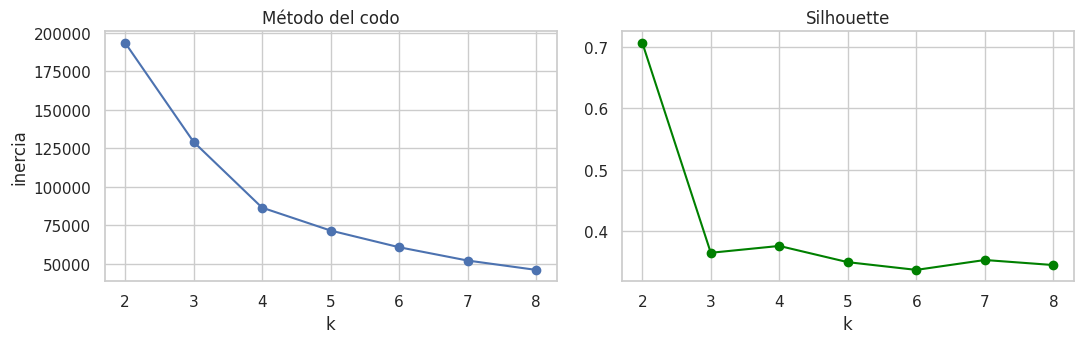

In [53]:
# ---- K-Means: ¿cuántos grupos? (k de 2 a 8) ----
rng = np.random.default_rng(SEMILLA)                              # generador aleatorio reproducible
idx_m = rng.choice(len(X_rfm), size=min(10000, len(X_rfm)), replace=False)   # muestra de 10.000 clientes para métricas y algoritmos costosos
X_m = X_rfm[idx_m]                                                # la muestra

prueba_k = []                                                     # acumula resultados para cada k
for k in range(2, 9):                                             # prueba k = 2..8
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(X_rfm)   # ajusta con todos los clientes
    etiquetas_m = km.labels_[idx_m]                               # etiquetas de la muestra
    prueba_k.append({'k': k, 'inercia': km.inertia_,              # inercia = suma de distancias internas (método del codo)
                     'silhouette': silhouette_score(X_m, etiquetas_m),       # cohesión/separación (más alto = mejor)
                     'davies_bouldin': davies_bouldin_score(X_m, etiquetas_m)})   # solapamiento entre grupos (más bajo = mejor)
tabla_k = pd.DataFrame(prueba_k).set_index('k')                   # tabla por k
display(tabla_k.round(3))
K_MIN_NEGOCIO = 3                                                 # k=2 solo separa "compró 1 vez" de "recurrentes": se exige k >= 3 para un segmento útil
K_BEST = int(tabla_k.loc[tabla_k.index >= K_MIN_NEGOCIO, 'silhouette'].idxmax())   # k (>= 3) con mayor silhouette
print(f'k con mayor silhouette global: {int(tabla_k["silhouette"].idxmax())} | k elegido (>= {K_MIN_NEGOCIO}): {K_BEST}')

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.6))                 # gráfico de selección de k
ejes[0].plot(tabla_k.index, tabla_k['inercia'], marker='o'); ejes[0].set(title='Método del codo', xlabel='k', ylabel='inercia')
ejes[1].plot(tabla_k.index, tabla_k['silhouette'], marker='o', c='green'); ejes[1].set(title='Silhouette', xlabel='k')
plt.tight_layout(); plt.show()

,n_grupos,% ruido,silhouette,davies_bouldin
algoritmo,,,,
K-Means (k=4),4,0.000,0.376,0.782
DBSCAN (eps=0.13),7,7.280,-0.028,0.552
"Jerárquico Ward (k=4, n=5.000)",4,0.000,0.255,0.964


,clientes,recencia,frecuencia,monetario,% clientes,etiqueta sugerida
cluster,,,,,,
0,38461,366.800,1.000,69.480,40.490,Dormidos de bajo valor
1,28530,333.860,1.000,319.560,30.030,En riesgo de alto valor
2,2888,270.760,2.110,308.360,3.040,Recurrentes / fieles
3,25111,116.100,1.000,121.850,26.440,Nuevos de alto valor


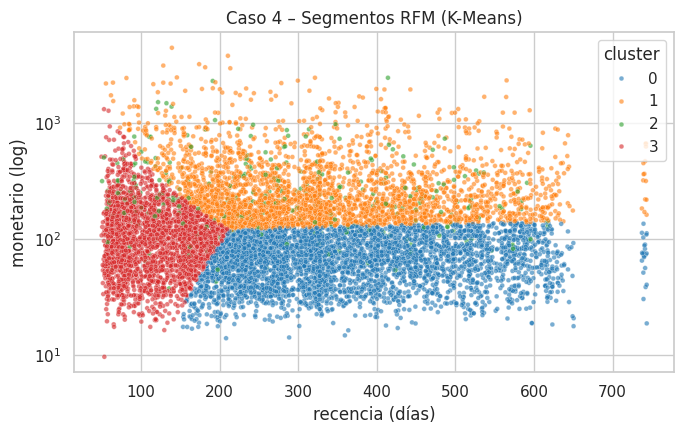

In [54]:
# ---- Modelo final K-Means ----
km_final = KMeans(n_clusters=K_BEST, n_init=10, random_state=SEMILLA).fit(X_rfm)   # ajusta con el k elegido
rfm['cluster'] = km_final.labels_                                 # asigna el grupo a cada cliente

# ---- DBSCAN: eps estimado con la distancia al 10º vecino (muestra de 10.000) ----
vecinos = NearestNeighbors(n_neighbors=10).fit(X_m)               # busca los 10 vecinos más cercanos de cada punto
dist, _ = vecinos.kneighbors(X_m)                                 # distancias a esos vecinos
eps = max(float(np.percentile(dist[:, -1], 90)), 0.05)            # eps = percentil 90 de la distancia al 10º vecino (mínimo 0.05)
lab_db = DBSCAN(eps=eps, min_samples=10).fit_predict(X_m)         # DBSCAN: -1 indica "ruido"

# ---- Jerárquico (Ward) sobre 5.000 clientes (la matriz de distancias crece con n²) ----
X_h = X_m[:5000]                                                  # sub-muestra
lab_h = AgglomerativeClustering(n_clusters=K_BEST, linkage='ward').fit_predict(X_h)   # dendrograma cortado en K_BEST grupos

def metricas_cluster(nombre, X, lab):                             # calcula Silhouette y Davies-Bouldin ignorando el ruido
    ok = lab != -1                                                # True = punto asignado a un grupo
    n_cl = len(set(lab[ok]))                                      # número de grupos encontrados
    fila = {'algoritmo': nombre, 'n_grupos': n_cl, '% ruido': float((~ok).mean() * 100),
            'silhouette': np.nan, 'davies_bouldin': np.nan}       # por defecto NaN si hay menos de 2 grupos
    if n_cl >= 2:                                                 # las métricas exigen al menos 2 grupos
        fila['silhouette'] = silhouette_score(X[ok], lab[ok])
        fila['davies_bouldin'] = davies_bouldin_score(X[ok], lab[ok])
    return fila

tabla_c4 = pd.DataFrame([
    metricas_cluster(f'K-Means (k={K_BEST})', X_m, km_final.labels_[idx_m]),              # sobre la muestra de 10.000
    metricas_cluster(f'DBSCAN (eps={eps:.2f})', X_m, lab_db),                              # sobre la muestra de 10.000
    metricas_cluster(f'Jerárquico Ward (k={K_BEST}, n=5.000)', X_h, lab_h)]).set_index('algoritmo')   # sobre 5.000
display(tabla_c4.round(3))

# ---- Perfil de cada grupo de K-Means + etiqueta sugerida (heurística) ----
perfil = (rfm.groupby('cluster').agg(clientes=('customer_unique_id', 'count'), recencia=('recencia', 'mean'),
                                     frecuencia=('frecuencia', 'mean'), monetario=('monetario', 'mean')))   # promedios por grupo
perfil['% clientes'] = perfil['clientes'] / perfil['clientes'].sum() * 100   # tamaño relativo
r_med, m_med = rfm['recencia'].median(), rfm['monetario'].median()          # medianas globales de referencia
def etiquetar(f):                                                 # reglas simples de negocio para nombrar cada grupo
    reciente, valioso = f['recencia'] <= r_med, f['monetario'] >= m_med       # ¿compró hace poco? ¿gasta más que la mediana?
    if f['frecuencia'] >= 1.5: return 'Recurrentes / fieles'      # compran más de una vez
    if reciente and valioso: return 'Nuevos de alto valor'
    if reciente: return 'Nuevos de bajo valor'
    if valioso: return 'En riesgo de alto valor'                  # gastaron mucho pero hace tiempo que no vuelven
    return 'Dormidos de bajo valor'
perfil['etiqueta sugerida'] = perfil.apply(etiquetar, axis=1)     # aplica las reglas a cada grupo
display(perfil.round(2))

# ---- Gráfico: grupos en el plano Recencia vs. Monetario (muestra) ----
muestra = rfm.iloc[idx_m]                                         # misma muestra de 10.000 clientes
plt.figure(figsize=(7, 4.5))
sns.scatterplot(data=muestra, x='recencia', y='monetario', hue='cluster', palette='tab10', s=12, alpha=.6)
plt.yscale('log'); plt.title('Caso 4 – Segmentos RFM (K-Means)'); plt.xlabel('recencia (días)'); plt.ylabel('monetario (log)')
plt.tight_layout(); plt.show()
RESULTADOS['caso4'] = {'tabla': tabla_c4, 'perfil': perfil, 'k': K_BEST, 'tabla_k': tabla_k,
                       'pct_una_compra': float((rfm['frecuencia'] == 1).mean()), 'recurrentes_post_corte': n_recurr / max(len(despues), 1)}

## H.11 Proyecto – Predicción del tiempo real de entrega (*lead time*, regresión)

**Objetivo:** predecir `y = tiempo_entrega_real_dias` (días entre la compra y la entrega al cliente) con modelos de regresión y compararlos entre sí y contra la **estimación estática** de la plataforma (`order_estimated_delivery_date`).

**Pasos (siguiendo los puntos del Word):**
1. **Variable objetivo y outliers (punto 3 y 5):** solo órdenes `delivered` con fecha; se eliminan tiempos ≤ 0 o > `MAX_DIAS_ENTREGA` (120 días; se muestra también cuántas se perderían con 90).
2. **Variables (punto 4):** distancia Haversine, mismo estado, volumen y peso totales, nº de ítems, nº de vendedores, precio, flete, ratio flete/precio, cuotas y variables del calendario de compra.
3. **Outliers de variables (punto 5):** winsorización p1–p99 aprendida en train (dentro del preprocesador), *log(1+x)* y `RobustScaler`. Estados con One-Hot y categoría de producto con Target Encoding.
4. **Validación (punto 6):** train = oct-2016 a may-2018; test = jun a ago-2018.
5. **Modelos (punto 7):** Ridge (baseline) · Random Forest · LightGBM / XGBoost (según estén instalados). Se entrena sobre `log(1+y)` y se devuelve a días (`TransformedTargetRegressor`), porque el tiempo de entrega es asimétrico.
6. **Métricas (punto 8):** MAE, RMSE, R² y MAPE.
7. **Entregables (punto 9):** gráficos de residuos, Top 10 de importancia de variables y conclusión de negocio frente a la estimación original.

Órdenes entregadas: 96,470
  tiempo <= 0 días (inconsistente): 0
  tiempo > 90 días: 77 | tiempo > 120 días: 43


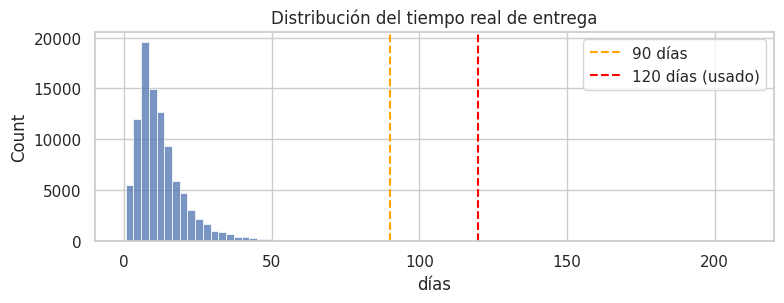

Filas tras el filtro: 96,427 (43 eliminadas)
Train: 77,824 | Test: 18,602 | y medio train: 13.4 d | y medio test: 8.6 d


In [55]:
# ---- 1) Objetivo y limpieza de outliers del objetivo ----
Y_COL = 'tiempo_entrega_real_dias'                                # variable objetivo (días)
df_p = df_ent.copy()                                              # df_ent ya contiene solo órdenes entregadas (order_status == delivered y fecha no nula)
n0 = len(df_p)                                                    # filas antes de filtrar
print(f'Órdenes entregadas: {n0:,}')
print(f'  tiempo <= 0 días (inconsistente): {(df_p[Y_COL] <= 0).sum():,}')
print(f'  tiempo > 90 días: {(df_p[Y_COL] > 90).sum():,} | tiempo > 120 días: {(df_p[Y_COL] > 120).sum():,}')

plt.figure(figsize=(8, 3.2))                                      # histograma del objetivo para justificar el umbral
sns.histplot(df_p[Y_COL], bins=80)
plt.axvline(90, ls='--', c='orange', label='90 días'); plt.axvline(MAX_DIAS_ENTREGA, ls='--', c='red', label=f'{MAX_DIAS_ENTREGA} días (usado)')
plt.title('Distribución del tiempo real de entrega'); plt.xlabel('días'); plt.legend(); plt.tight_layout(); plt.show()

df_p = df_p[(df_p[Y_COL] > 0) & (df_p[Y_COL] <= MAX_DIAS_ENTREGA)].copy()   # conserva solo entregas coherentes
print(f'Filas tras el filtro: {len(df_p):,} ({n0 - len(df_p):,} eliminadas)')

# ---- 2) Variables, preprocesador y partición temporal ----
FEAT_P_SESG = SESGADAS                                            # distancia, peso, volumen, precio, flete, ratio (log + robusto)
FEAT_P_SIM = ['n_items', 'n_vendedores', 'cuotas_max', 'dia_semana', 'hora', 'mes']   # numéricas sin cola marcada
FEAT_P = FEAT_P_SESG + FEAT_P_SIM + BINARIAS + CAT_OHE + CAT_TE   # lista total de predictoras
prep_p = armar_preprocesador(sesgadas=FEAT_P_SESG, simetricas=FEAT_P_SIM, binarias=BINARIAS, cat_ohe=CAT_OHE, cat_te=CAT_TE)
df_p_tr, df_p_te = dividir_temporal(df_p)                         # train: oct-2016..may-2018 | test: jun..ago-2018
y_tr, y_te = df_p_tr[Y_COL].values, df_p_te[Y_COL].values         # vectores objetivo
print(f'Train: {len(df_p_tr):,} | Test: {len(df_p_te):,} | y medio train: {y_tr.mean():.1f} d | y medio test: {y_te.mean():.1f} d')

# ---- 3) Función de métricas del Word ----
def metricas_reg(nombre, y, yhat):
    return {'modelo': nombre,
            'MAE (días)': mean_absolute_error(y, yhat),           # error absoluto medio
            'RMSE (días)': float(np.sqrt(mean_squared_error(y, yhat))),   # raíz del error cuadrático medio
            'R²': r2_score(y, yhat),                              # proporción de varianza explicada
            'MAPE %': float(np.mean(np.abs((y - yhat) / y)) * 100)}   # error porcentual (y > 0 está garantizado por el filtro)

In [56]:
# ---- 4) Modelos ----
LOG_TARGET = True                                                 # True: se entrena sobre log(1+y) y se devuelve a días
def armar_reg(reg):
    """Preprocesador + regresor (opcionalmente con objetivo logarítmico). Todo se ajusta solo con train."""
    modelo = TransformedTargetRegressor(regressor=reg, func=np.log1p, inverse_func=np.expm1) if LOG_TARGET else reg
    return Pipeline([('prep', clone(prep_p)), ('reg', modelo)])

modelos_p = {
    'Ridge (baseline)': armar_reg(Ridge(alpha=1.0)),              # regresión lineal regularizada
    'Random Forest': armar_reg(RandomForestRegressor(n_estimators=300, min_samples_leaf=5, max_features=0.5,
                                                     n_jobs=-1, random_state=SEMILLA))}   # bosque de árboles
if HAY_LGBM:                                                      # boosting 1
    modelos_p['LightGBM'] = armar_reg(lgb.LGBMRegressor(n_estimators=600, learning_rate=0.05, num_leaves=31, subsample=0.8,
                                                        subsample_freq=1, colsample_bytree=0.8, random_state=SEMILLA,
                                                        n_jobs=-1, verbose=-1))
if HAY_XGB:                                                       # boosting 2
    modelos_p['XGBoost'] = armar_reg(xgb.XGBRegressor(n_estimators=600, max_depth=5, learning_rate=0.05, subsample=0.8,
                                                      colsample_bytree=0.8, random_state=SEMILLA, n_jobs=-1))
if not (HAY_LGBM or HAY_XGB):                                     # sustituto si no hay ninguna librería de boosting
    modelos_p['HistGradientBoosting (sustituto)'] = armar_reg(HistGradientBoostingRegressor(
        max_iter=400, learning_rate=0.05, random_state=SEMILLA))

filas_p, preds_p = [], {}                                         # métricas y predicciones por modelo
for nombre, pipe in modelos_p.items():                            # entrena y evalúa cada modelo
    try:                                                          # si una librería falla, se informa y se sigue
        pipe.fit(df_p_tr[FEAT_P], y_tr)                           # ajuste SOLO con train
        preds_p[nombre] = pipe.predict(df_p_te[FEAT_P])           # predicción en test (en días)
    except Exception as e:                                        # captura el error de ese modelo
        print(f'AVISO: {nombre} no pudo entrenarse ({type(e).__name__}: {e})')
        continue                                                  # pasa al siguiente
    filas_p.append(metricas_reg(nombre, y_te, preds_p[nombre]))
# ---- Referencias (no son modelos de ML) ----
filas_ref = [metricas_reg('Referencia: media de train', y_te, np.full(len(y_te), y_tr.mean())),     # predecir siempre el promedio
             metricas_reg('Estimación original de Olist', y_te, df_p_te['tiempo_estimado_dias'].values)]   # fecha prometida por la plataforma
tabla_p = pd.DataFrame(filas_p + filas_ref).set_index('modelo')   # tabla final
display(tabla_p.round(3))
mejor_p = tabla_p.loc[list(preds_p.keys()), 'MAE (días)'].idxmin()   # mejor modelo de ML (entre los que se entrenaron) por MAE
print('Mejor modelo de ML (menor MAE):', mejor_p)

,MAE (días),RMSE (días),R²,MAPE %
modelo,,,,
Ridge (baseline),4.519,5.884,-0.049,71.883
Random Forest,3.702,5.190,0.184,56.289
LightGBM,3.683,5.171,0.190,55.264
XGBoost,3.696,5.182,0.186,55.451
Referencia: media de train,6.389,7.480,-0.695,134.094
Estimación original de Olist,12.714,15.414,-6.199,197.605


Mejor modelo de ML (menor MAE): LightGBM


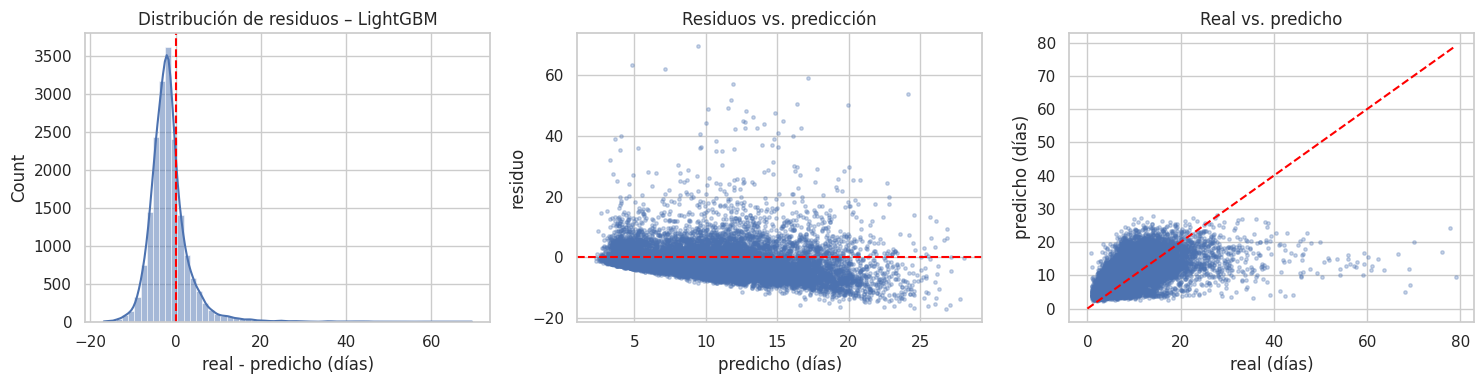

Residuo medio (sesgo): -1.53 d | desvío: 4.94 d | percentil 5 / 95: -7.5 / 6.1 d


,variable,aumento_MAE_dias,desvio
0,distancia_km,0.270,0.016
1,peso_total_g,0.120,0.002
2,dia_semana,0.066,0.009
3,volumen_total_dm3,0.065,0.007
4,flete_total,0.048,0.010
5,product_category_name_english,0.022,0.006
6,mes,0.019,0.004
7,seller_state,0.015,0.009
8,precio_total,0.014,0.004
9,hora,0.010,0.004


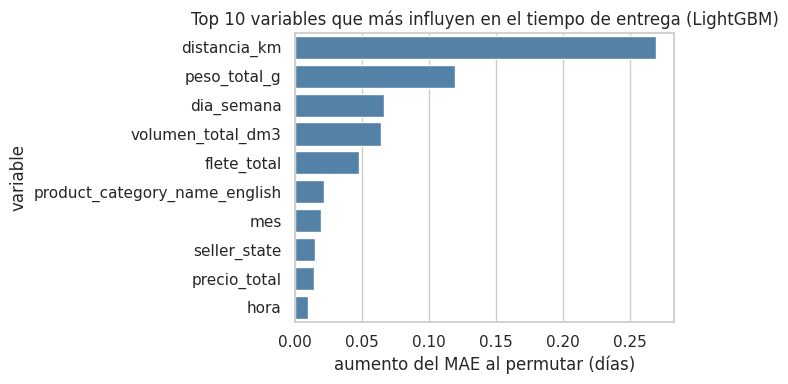

In [57]:
# ---- 5) Entregable: análisis de residuos del mejor modelo ----
pred_mejor_p = preds_p[mejor_p]                                   # predicciones del mejor modelo
resid = y_te - pred_mejor_p                                       # residuo = real - predicho (>0: el modelo se quedó corto)
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(resid, bins=60, kde=True, ax=ejes[0])                # distribución de errores (ideal: centrada en 0 y simétrica)
ejes[0].axvline(0, c='red', ls='--'); ejes[0].set(title=f'Distribución de residuos – {mejor_p}', xlabel='real - predicho (días)')
ejes[1].scatter(pred_mejor_p, resid, s=6, alpha=.3)               # residuos vs predicción (ideal: nube plana, sin patrón)
ejes[1].axhline(0, c='red', ls='--'); ejes[1].set(title='Residuos vs. predicción', xlabel='predicho (días)', ylabel='residuo')
ejes[2].scatter(y_te, pred_mejor_p, s=6, alpha=.3)                # real vs predicho (ideal: sobre la diagonal)
lim = [0, max(y_te.max(), pred_mejor_p.max())]; ejes[2].plot(lim, lim, c='red', ls='--')
ejes[2].set(title='Real vs. predicho', xlabel='real (días)', ylabel='predicho (días)')
plt.tight_layout(); plt.show()
print(f'Residuo medio (sesgo): {resid.mean():.2f} d | desvío: {resid.std():.2f} d | percentil 5 / 95: {np.percentile(resid, 5):.1f} / {np.percentile(resid, 95):.1f} d')

# ---- 6) Entregable: Top 10 de importancia de variables (por permutación, sobre test) ----
rng_p = np.random.default_rng(SEMILLA)                            # muestreo reproducible
idx_imp = rng_p.choice(len(df_p_te), size=min(3000, len(df_p_te)), replace=False)   # hasta 3.000 filas para que sea rápido
imp = permutation_importance(modelos_p[mejor_p], df_p_te.iloc[idx_imp][FEAT_P], y_te[idx_imp],
                             scoring='neg_mean_absolute_error', n_repeats=5, random_state=SEMILLA, n_jobs=1)   # mezcla cada columna y mide cuánto empeora el MAE
imp_df = (pd.DataFrame({'variable': FEAT_P, 'aumento_MAE_dias': imp.importances_mean, 'desvio': imp.importances_std})
          .sort_values('aumento_MAE_dias', ascending=False).head(10).reset_index(drop=True))   # Top 10
display(imp_df.round(4))
plt.figure(figsize=(7, 4))
sns.barplot(data=imp_df, y='variable', x='aumento_MAE_dias', color='steelblue')
plt.title(f'Top 10 variables que más influyen en el tiempo de entrega ({mejor_p})'); plt.xlabel('aumento del MAE al permutar (días)')
plt.tight_layout(); plt.show()

In [58]:
# ---- 7) Conclusión de negocio: modelo vs. estimación estática de la plataforma ----
est = df_p_te['tiempo_estimado_dias'].values                      # días prometidos por la plataforma (desde la compra)
pred = preds_p[mejor_p]                                           # días predichos por el modelo
mae_est, mae_mod = mean_absolute_error(y_te, est), mean_absolute_error(y_te, pred)   # error de cada uno
comparacion = {
    'MAE modelo (días)': mae_mod, 'MAE estimación Olist (días)': mae_est,
    'mejora del MAE': (mae_est - mae_mod) / mae_est,              # reducción relativa del error
    'sesgo modelo (pred - real, días)': float(np.mean(pred - y_te)),
    'sesgo Olist (estimado - real, días)': float(np.mean(est - y_te)),   # > 0: la plataforma promete de más (sobreestima)
    '% órdenes donde el modelo está más cerca que Olist': float(np.mean(np.abs(pred - y_te) < np.abs(est - y_te))),
    '% entregas posteriores a la estimación Olist': float(np.mean(y_te > est)),   # retrasos "oficiales"
    '% entregas posteriores a la predicción del modelo': float(np.mean(y_te > pred))}   # si se usara la predicción como promesa
display(pd.Series(comparacion).to_frame('valor').round(3))
RESULTADOS['proyecto'] = {'tabla': tabla_p, 'mejor': mejor_p, 'importancias': imp_df, 'comparacion': comparacion,
                          'n_train': len(df_p_tr), 'n_test': len(df_p_te), 'n_filtradas': n0 - len(df_p)}   # guarda para el informe

,valor
MAE modelo (días),3.683
MAE estimación Olist (días),12.714
mejora del MAE,0.710
"sesgo modelo (pred - real, días)",1.530
"sesgo Olist (estimado - real, días)",12.175
% órdenes donde el modelo está más cerca que Olist,0.879
% entregas posteriores a la estimación Olist,0.055
% entregas posteriores a la predicción del modelo,0.256


## H.12 Informe final

El informe se **genera automáticamente** a partir de los resultados calculados en las celdas anteriores, de modo que los números siempre coinciden con lo ejecutado.
Primero se resume qué estaba resuelto y qué se hizo; luego se presentan los resultados por consigna y las conclusiones de negocio.

In [59]:
from IPython.display import Markdown                              # permite mostrar texto con formato markdown generado por código

def pct(x): return f'{x:.1%}'.replace('.', ',')                   # formatea un porcentaje con coma decimal
def num(x, d=2): return f'{x:,.{d}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')   # formatea número con coma decimal y punto de miles

R1, R2, R3, R4, RP = (RESULTADOS['caso1'], RESULTADOS['caso2'], RESULTADOS['caso3'], RESULTADOS['caso4'], RESULTADOS['proyecto'])   # atajos

# ---------- 1. Datos y metodología ----------
display(Markdown(f"""
# INFORME FINAL – Análisis y modelado del dataset Olist (e-commerce Brasil)

## 1. Alcance y metodología
* **Datos:** {num(len(raw_orders), 0)} órdenes (2016-2018) en 9 tablas; los `raw_*` se conservaron intactos y todo el trabajo se hizo sobre copias.
* **Base de modelado:** {num(len(df_ent), 0)} órdenes entregadas; el **{pct(df_f['es_cancelada_o_no_disponible'].mean())}** del total son canceladas/no disponibles y quedaron marcadas, no mezcladas.
* **Validación:** división **cronológica** (train: oct-2016 a may-2018; test: jun-ago 2018). Imputación, winsorización p1-p99, escalado y codificación se **aprenden solo con train** (Pipeline).
* **Corrección de defectos previos:** las órdenes sin entrega ya no se etiquetan como «no atrasadas» ({num(n_mal, 0)} casos); se eliminaron las columnas «fantasma» de reseñas; el peso y el volumen ahora son **totales por orden**.
"""))

# ---------- 2. Estado de las mejoras ----------
mejoras = pd.DataFrame([
    ['D1 / D2', 'Geolocalización única por prefijo (media lat/lng)', 'Ya resuelto en D.1', 'Verificado con controles automáticos (H.0.2b)'],
    ['E1 / E2', 'SMOTE solo sobre train', 'Ya resuelto en Paso 7', 'Regla escrita; variante con Pipeline de imblearn (H.7)'],
    ['G1', 'Bloques de código ejecutables', 'Ya resuelto', '—'],
    ['B1', 'Imputación explícita sin fuga', 'Parcial', 'Imputador y winsorización aprendidos solo con train (H.5)'],
    ['G2', 'Liberar memoria (del / gc.collect)', 'Pendiente', 'Hecho en H.4.1'],
    ['G3', 'Métricas RFM antes de la fecha de corte', 'Pendiente', 'Hecho en H.10 (función con fecha de snapshot)']],
    columns=['Punto', 'Mejora', 'Estado inicial', 'Resolución'])
display(Markdown('## 2. Puntos del informe de mejoras'))
display(mejoras)

# ---------- 3. Caso 1 ----------
t1, m1 = R1['tabla'], R1['mejor']
display(Markdown(f"""
## 3. Resultados por consigna

### Caso 1 – Retraso en la entrega (clasificación)
Prevalencia de retraso en test: **{pct(R1['prevalencia_test'])}**. El mejor modelo por PR-AUC es **{m1}**:
ROC-AUC = **{num(t1.loc[m1, 'ROC-AUC'], 3)}**, PR-AUC = **{num(t1.loc[m1, 'PR-AUC'], 3)}** (el azar rinde {num(R1['prevalencia_test'], 3)}, es decir {num(t1.loc[m1, 'PR-AUC'] / R1['prevalencia_test'], 1)} veces la línea base),
F1 con umbral validado = **{num(t1.loc[m1, 'F1 (umbral óptimo)'], 3)}**. El modelo del Paso 7 original había obtenido ROC-AUC = 0,520 y PR-AUC = 0,057.
"""))
display(t1.round(3))

# ---------- 4. Caso 2 ----------
t2, tn = R2['tabla'], R2['tabla_nlp']
modelos_ml2 = [i for i in t2.index if not i.startswith('Referencia')]
m2 = t2.loc[modelos_ml2, 'F1 ponderado'].idxmax()
mn = tn['F1 ponderado'].idxmax()
display(Markdown(f"""
### Caso 2 – Satisfacción del cliente (reseña negativa = 1-3 estrellas)
Proporción de reseñas negativas en test: **{pct(R2['neg_test'])}**. Con variables tabulares, el mejor modelo por F1 ponderado es **{m2}**
(Accuracy = {num(t2.loc[m2, 'Accuracy'], 3)}, F1 ponderado = {num(t2.loc[m2, 'F1 ponderado'], 3)}, F1 de la clase negativa = {num(t2.loc[m2, 'F1 clase negativa'], 3)}, ROC-AUC = {num(t2.loc[m2, 'ROC-AUC'], 3)}).
La regla ingenua «todo positivo» logra Accuracy = {num(t2.loc['Referencia: todo positivo', 'Accuracy'], 3)} pero **no detecta ninguna reseña negativa** (F1 negativa = 0): por eso la accuracy sola no alcanza.
Con el **texto** del comentario ({mn}): Accuracy = {num(tn.loc[mn, 'Accuracy'], 3)}, F1 ponderado = {num(tn.loc[mn, 'F1 ponderado'], 3)}; en 5 clases (puntaje exacto) la Regresión Logística obtiene Accuracy = {num(R2['fila_5']['Accuracy'], 3)}.
"""))
display(t2.round(3)); display(tn.round(3))

# ---------- 5. Caso 3 ----------
tt, ts = R3['total'], R3['sp']
mejor_tt, mejor_ts = tt['MAPE %'].idxmin(), ts['MAPE %'].idxmin()
ref_t = tt.loc['Referencia (prom. 4 semanas)']                  # fila de la referencia ingenua (Total Brasil)
gana_ref = mejor_tt.startswith('Referencia')                      # ¿ningún modelo supera a la referencia?
txt_tt = ('**ningún modelo supera a la referencia ingenua** (promedio de las últimas 4 semanas)' if gana_ref
          else f'mejor modelo por MAPE = **{mejor_tt}**')            # frase que abre el punto de Total Brasil
txt_ref = '' if gana_ref else f'; la referencia ingenua obtiene MAPE = {num(ref_t["MAPE %"], 1)} %'   # cola solo si gana un modelo
display(Markdown(f"""
### Caso 3 – Ventas diarias (series temporales, horizonte ≈ 12 semanas)
* **Total Brasil:** {txt_tt} (MAE = {num(tt.loc[mejor_tt, 'MAE'], 1)} órdenes/día, RMSE = {num(tt.loc[mejor_tt, 'RMSE'], 1)}, MAPE = {num(tt.loc[mejor_tt, 'MAPE %'], 1)} %){txt_ref}.
* **São Paulo:** mejor modelo = **{mejor_ts}** (MAPE = {num(ts.loc[mejor_ts, 'MAPE %'], 1)} %). Las series de un solo estado tienen menos volumen y son proporcionalmente más ruidosas.
"""))
display(tt.round(2)); display(ts.round(2))

# ---------- 6. Caso 4 ----------
perf = R4['perfil']
display(Markdown(f"""
### Caso 4 – Segmentación RFM
El **{pct(R4['pct_una_compra'])}** de los clientes compró una sola vez; solo el **{pct(R4['recurrentes_post_corte'])}** de quienes compraron después del corte ya tenía historial previo.
K-Means con **k = {R4['k']}** (elegido por Silhouette con k ≥ 3) produce los siguientes segmentos:
"""))
display(perf.round(2)); display(R4['tabla'].round(3))

# ---------- 7. Proyecto ----------
tp, mp, cp = RP['tabla'], RP['mejor'], RP['comparacion']
top3 = ', '.join(RP['importancias']['variable'].head(3))
display(Markdown(f"""
### Proyecto – Predicción del tiempo real de entrega (regresión)
Train = {num(RP['n_train'], 0)} órdenes · Test = {num(RP['n_test'], 0)} órdenes ({num(RP['n_filtradas'], 0)} entregas eliminadas por tiempos > {MAX_DIAS_ENTREGA} días o ≤ 0).
Mejor modelo: **{mp}** con MAE = **{num(tp.loc[mp, 'MAE (días)'])} días**, RMSE = {num(tp.loc[mp, 'RMSE (días)'])} días, R² = {num(tp.loc[mp, 'R²'], 3)} y MAPE = {num(tp.loc[mp, 'MAPE %'], 1)} %.
Las tres variables más influyentes son: **{top3}**.
"""))
display(tp.round(3)); display(RP['importancias'].round(3))

# ---------- 8. Conclusión de negocio ----------
display(Markdown(f"""
## 4. Conclusión de negocio: modelo vs. estimación estática de Olist
* El error medio del modelo es de **{num(cp['MAE modelo (días)'])} días** frente a **{num(cp['MAE estimación Olist (días)'])} días** de la estimación original: {'una reducción' if cp['mejora del MAE'] > 0 else 'un aumento'} del **{pct(abs(cp['mejora del MAE']))}** en el MAE.
* La estimación de la plataforma tiene un sesgo de **{num(cp['sesgo Olist (estimado - real, días)'])} días** ({'positivo: promete más días de los necesarios, es decir, es *conservadora*' if cp['sesgo Olist (estimado - real, días)'] > 0 else 'negativo: promete menos días de los necesarios'}), mientras que el modelo tiene un sesgo de {num(cp['sesgo modelo (pred - real, días)'])} días.
* El modelo es más preciso que la estimación en el **{pct(cp['% órdenes donde el modelo está más cerca que Olist'])}** de las órdenes.
* Con la estimación original llegan tarde el **{pct(cp['% entregas posteriores a la estimación Olist'])}** de las entregas; si se usara la **predicción puntual** como fecha prometida llegarían tarde el **{pct(cp['% entregas posteriores a la predicción del modelo'])}**.
  **Implicancia:** una predicción puntual sirve para *planificar* y para mostrar un tiempo más realista, pero para **prometer** una fecha hace falta sumarle un margen (por ejemplo, un modelo de cuantiles al 90 %) para controlar la tasa de retrasos.

## 5. Limitaciones y supuestos
* El vendedor y el producto «principales» de una orden son los del **primer ítem**; las órdenes con varios vendedores usan la distancia al principal.
* Las coordenadas son el **promedio por prefijo postal**; los prefijos sin coordenadas dejan la distancia sin dato (NaN), que se imputa con la mediana de train.
* El historial del vendedor (Caso 2) y el *Target Encoding* usan solo información previa o validación cruzada interna, pero el prior de suavizado usa el promedio global de train.
* Las predicciones de ventas son *puntuales* y de horizonte largo; Prophet y SARIMAX disponen de apenas ~17 meses de historia.
* Los umbrales de outliers (p1-p99, 120 días) son decisiones de diseño y se pueden cambiar en `H.1`.

## 6. Próximos pasos
1. Modelo de **cuantiles** (LightGBM `objective='quantile'`) para fijar fechas prometidas con un nivel de riesgo controlado.
2. Variables de **clima, feriados regionales y capacidad logística** para mejorar el *lead time*.
3. Validación con **validación cruzada temporal** (`TimeSeriesSplit`) y ajuste de hiperparámetros.
4. Incorporar el **RFM al corte** y el historial del vendedor como variables de los modelos de retraso.
"""))


# INFORME FINAL – Análisis y modelado del dataset Olist (e-commerce Brasil)

## 1. Alcance y metodología
* **Datos:** 99.441 órdenes (2016-2018) en 9 tablas; los `raw_*` se conservaron intactos y todo el trabajo se hizo sobre copias.
* **Base de modelado:** 96.470 órdenes entregadas; el **1,2%** del total son canceladas/no disponibles y quedaron marcadas, no mezcladas.
* **Validación:** división **cronológica** (train: oct-2016 a may-2018; test: jun-ago 2018). Imputación, winsorización p1-p99, escalado y codificación se **aprenden solo con train** (Pipeline).
* **Corrección de defectos previos:** las órdenes sin entrega ya no se etiquetan como «no atrasadas» (2.965 casos); se eliminaron las columnas «fantasma» de reseñas; el peso y el volumen ahora son **totales por orden**.


## 2. Puntos del informe de mejoras

,Punto,Mejora,Estado inicial,Resolución
0,D1 / D2,Geolocalización única por prefijo (media lat/lng),Ya resuelto en D.1,Verificado con controles automáticos (H.0.2b)
1,E1 / E2,SMOTE solo sobre train,Ya resuelto en Paso 7,Regla escrita; variante con Pipeline de imblea...
2,G1,Bloques de código ejecutables,Ya resuelto,—
3,B1,Imputación explícita sin fuga,Parcial,Imputador y winsorización aprendidos solo con ...
4,G2,Liberar memoria (del / gc.collect),Pendiente,Hecho en H.4.1
5,G3,Métricas RFM antes de la fecha de corte,Pendiente,Hecho en H.10 (función con fecha de snapshot)



## 3. Resultados por consigna

### Caso 1 – Retraso en la entrega (clasificación)
Prevalencia de retraso en test: **5,5%**. El mejor modelo por PR-AUC es **LightGBM**:
ROC-AUC = **0,559**, PR-AUC = **0,067** (el azar rinde 0,055, es decir 1,2 veces la línea base),
F1 con umbral validado = **0,060**. El modelo del Paso 7 original había obtenido ROC-AUC = 0,520 y PR-AUC = 0,057.


,ROC-AUC,PR-AUC,F1 (umbral 0.5),F1 (umbral óptimo),umbral,precisión,recall
modelo,,,,,,,
Regresión Logística (baseline),0.414,0.054,0.078,0.074,0.594,0.047,0.174
Random Forest,0.527,0.061,0.068,0.078,0.411,0.053,0.150
Reg. Logística + SMOTE,0.419,0.054,0.076,0.072,0.607,0.047,0.156
XGBoost,0.566,0.067,0.074,0.064,0.537,0.101,0.047
LightGBM,0.559,0.067,0.066,0.060,0.512,0.075,0.050



### Caso 2 – Satisfacción del cliente (reseña negativa = 1-3 estrellas)
Proporción de reseñas negativas en test: **16,6%**. Con variables tabulares, el mejor modelo por F1 ponderado es **Random Forest**
(Accuracy = 0,771, F1 ponderado = 0,777, F1 de la clase negativa = 0,351, ROC-AUC = 0,653).
La regla ingenua «todo positivo» logra Accuracy = 0,834 pero **no detecta ninguna reseña negativa** (F1 negativa = 0): por eso la accuracy sola no alcanza.
Con el **texto** del comentario (TF-IDF + Regresión Logística): Accuracy = 0,896, F1 ponderado = 0,898; en 5 clases (puntaje exacto) la Regresión Logística obtiene Accuracy = 0,605.


... (8 outputs left out)


### Proyecto – Predicción del tiempo real de entrega (regresión)
Train = 77.824 órdenes · Test = 18.602 órdenes (43 entregas eliminadas por tiempos > 120 días o ≤ 0).
Mejor modelo: **LightGBM** con MAE = **3,68 días**, RMSE = 5,17 días, R² = 0,190 y MAPE = 55,3 %.
Las tres variables más influyentes son: **distancia_km, peso_total_g, dia_semana**.


,MAE (días),RMSE (días),R²,MAPE %
modelo,,,,
Ridge (baseline),4.519,5.884,-0.049,71.883
Random Forest,3.702,5.190,0.184,56.289
LightGBM,3.683,5.171,0.190,55.264
XGBoost,3.696,5.182,0.186,55.451
Referencia: media de train,6.389,7.480,-0.695,134.094
Estimación original de Olist,12.714,15.414,-6.199,197.605


,variable,aumento_MAE_dias,desvio
0,distancia_km,0.270,0.016
1,peso_total_g,0.120,0.002
2,dia_semana,0.066,0.009
3,volumen_total_dm3,0.065,0.007
4,flete_total,0.048,0.010
5,product_category_name_english,0.022,0.006
6,mes,0.019,0.004
7,seller_state,0.015,0.009
8,precio_total,0.014,0.004
9,hora,0.010,0.004



## 4. Conclusión de negocio: modelo vs. estimación estática de Olist
* El error medio del modelo es de **3,68 días** frente a **12,71 días** de la estimación original: una reducción del **71,0%** en el MAE.
* La estimación de la plataforma tiene un sesgo de **12,17 días** (positivo: promete más días de los necesarios, es decir, es *conservadora*), mientras que el modelo tiene un sesgo de 1,53 días.
* El modelo es más preciso que la estimación en el **87,9%** de las órdenes.
* Con la estimación original llegan tarde el **5,5%** de las entregas; si se usara la **predicción puntual** como fecha prometida llegarían tarde el **25,6%**.
  **Implicancia:** una predicción puntual sirve para *planificar* y para mostrar un tiempo más realista, pero para **prometer** una fecha hace falta sumarle un margen (por ejemplo, un modelo de cuantiles al 90 %) para controlar la tasa de retrasos.

## 5. Limitaciones y supuestos
* El vendedor y el producto «principales» de una orden son los del **primer ítem**; las órdenes con varios vendedores usan la distancia al principal.
* Las coordenadas son el **promedio por prefijo postal**; los prefijos sin coordenadas dejan la distancia sin dato (NaN), que se imputa con la mediana de train.
* El historial del vendedor (Caso 2) y el *Target Encoding* usan solo información previa o validación cruzada interna, pero el prior de suavizado usa el promedio global de train.
* Las predicciones de ventas son *puntuales* y de horizonte largo; Prophet y SARIMAX disponen de apenas ~17 meses de historia.
* Los umbrales de outliers (p1-p99, 120 días) son decisiones de diseño y se pueden cambiar en `H.1`.

## 6. Próximos pasos
1. Modelo de **cuantiles** (LightGBM `objective='quantile'`) para fijar fechas prometidas con un nivel de riesgo controlado.
2. Variables de **clima, feriados regionales y capacidad logística** para mejorar el *lead time*.
3. Validación con **validación cruzada temporal** (`TimeSeriesSplit`) y ajuste de hiperparámetros.
4. Incorporar el **RFM al corte** y el historial del vendedor como variables de los modelos de retraso.


## Lista de comprobación final (Bloque H)
>Fecha 09/11/2026

| Verificación | Cumple |
|---|---|
| `raw_*` sin modificar; todo el trabajo sobre copias (`df_f`, `df_ent`, `df_c1_*`, `df_c2_*`, `df_p_*`) | ☑ |
| Un `assert` comprueba que train es anterior a test (`dividir_temporal`) | ☑ |
| Imputación, winsorización, escalado y codificación dentro de un `Pipeline` ajustado solo con train | ☑ |
| SMOTE solo dentro del `Pipeline` de *imblearn* (se aplica en `fit`, nunca al test) | ☑ |
| Órdenes no entregadas excluidas de las etiquetas (`is_delayed` nulo, no 0) | ☑ |
| Métricas del Word: ROC-AUC/PR-AUC/F1 · Accuracy/F1 ponderado · MAE/RMSE/MAPE · Silhouette/Davies-Bouldin · MAE/RMSE/R²/MAPE | ☑ |
| Mejoras G2 (memoria) y G3 (RFM antes del corte) incorporadas | ☑ |
| Informe final generado a partir de los resultados calculados | ☑ |

## H.13 Diagnóstico adicional: ¿cambió el comportamiento entre train y test?

Al ejecutar los casos apareció algo común: **el período de test «se porta distinto» que el de entrenamiento** (menos retrasos, entregas más rápidas, menos reseñas negativas). Esta celda lo verifica con datos: evolución mensual de las métricas clave y, para el Caso 1, el AUC de cada variable por separado en train y en test (si pasa de < 0,5 a > 0,5, la relación aprendida se invirtió).

,ordenes,pct_entregadas,tiempo_medio_dias,pct_retraso,pct_resena_negativa
mes_compra,,,,,
2017-01,800,0.938,12.647,0.031,0.241
2017-02,1780,0.929,13.169,0.032,0.256
2017-03,2682,0.949,12.951,0.056,0.233
2017-04,2404,0.958,14.918,0.079,0.243
2017-05,3700,0.958,11.322,0.036,0.217
2017-06,3245,0.966,12.012,0.039,0.214
2017-07,4026,0.962,11.593,0.034,0.208
2017-08,4331,0.968,11.147,0.033,0.183
2017-09,4285,0.968,11.851,0.052,0.199


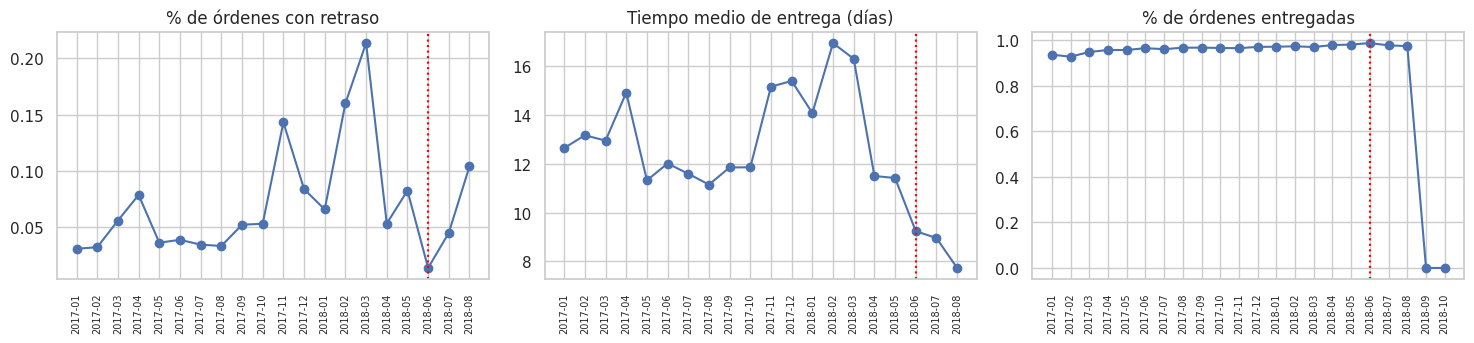

,AUC en train,AUC en test
variable,,
distancia_km,0.593,0.357
peso_total_g,0.516,0.497
volumen_total_dm3,0.507,0.490
flete_total,0.580,0.387
mes,0.462,0.695
dia_semana,0.489,0.447


In [60]:
# ---------- H.13  Diagnóstico adicional: evolución mensual y estabilidad de las variables ----------
base = df_f[df_f['order_purchase_timestamp'] >= '2017-01-01'].copy()      # desde 2017 (antes hay muy pocas órdenes)
base['mes_compra'] = base['order_purchase_timestamp'].dt.to_period('M').astype(str)   # año-mes de la compra, como texto (ej.: "2018-05")
base['resena_negativa'] = np.where(base['review_score'].notna(), (base['review_score'] <= 3).astype(float), np.nan)   # 1/0 si hay reseña; nulo si no

resumen_mes = (base.groupby('mes_compra')                         # una fila por mes de compra
               .agg(ordenes=('order_id', 'size'),                 # cantidad de órdenes del mes
                    pct_entregadas=('es_entregada', 'mean'),      # % ya entregadas al cierre del dataset (cae al final = censura)
                    tiempo_medio_dias=('tiempo_entrega_real_dias', 'mean'),   # tiempo medio de entrega (solo entregadas)
                    pct_retraso=('is_delayed', 'mean'),           # % con retraso (la media ignora los nulos = no entregadas)
                    pct_resena_negativa=('resena_negativa', 'mean')))   # % de reseñas de 1 a 3 estrellas
display(resumen_mes.round(3))                                     # tabla mensual

fig, ejes = plt.subplots(1, 3, figsize=(15, 3.6))                 # tres paneles: retraso, tiempo de entrega y % entregadas
for eje, col, tit in zip(ejes, ['pct_retraso', 'tiempo_medio_dias', 'pct_entregadas'],
                         ['% de órdenes con retraso', 'Tiempo medio de entrega (días)', '% de órdenes entregadas']):
    eje.plot(resumen_mes.index, resumen_mes[col], marker='o')     # evolución mensual
    eje.axvline(str(F_CORTE.to_period('M')), ls=':', c='red')     # mes de la fecha de corte train/test
    eje.set_title(tit); eje.tick_params(axis='x', rotation=90, labelsize=7)   # título y etiquetas legibles
plt.tight_layout(); plt.show()

# ---- Caso 1: AUC de cada variable por separado, en train y en test ----
filas_auc = []                                                    # acumulador
for col in FEAT_C1_SESG + FEAT_C1_SIM:                            # recorre las variables numéricas del Caso 1
    med = df_c1_tr[col].median()                                  # mediana de train para completar nulos
    filas_auc.append({'variable': col,
                      'AUC en train': roc_auc_score(df_c1_tr[TARGET_C1], df_c1_tr[col].fillna(med)),   # ¿ordena bien los retrasos en train?
                      'AUC en test': roc_auc_score(df_c1_te[TARGET_C1], df_c1_te[col].fillna(med))})   # ¿y en test?
display(pd.DataFrame(filas_auc).set_index('variable').round(3))   # 0,5 = sin información; si cruza 0,5 entre train y test, la relación se invirtió

---
##Próximos pasos implementados (H.14 a H.17)

Los cuatro «próximos pasos» del informe, resueltos como pruebas sobre las mismas copias y con la misma partición cronológica (train hasta may-2018, test jun-ago 2018). Cada bloque deja una tabla comparable con la versión anterior.


### Cómo leer H.14 a H.17

* **H.14 (cuantiles):** buscar el cuantil que **iguala el % tarde actual de Olist con la menor promesa media**; la columna «ahorro vs Olist» es el beneficio comercial (días menos prometidos al cliente). Si la cobertura real supera a la nominal, es la deriva temporal ya vista.
* **H.15 (feriados/clima):** una mejora del MAE por debajo de ~0,02 días indica que esas variables **no aportan** al modelo; el clima requiere cargar un archivo externo.
* **H.16 (TimeSeriesSplit):** si el MAE cambia mucho entre cortes, el desempeño **depende del período** y conviene reportar el rango y no un único número; el ajuste de hiperparámetros suele aportar poco frente a ese efecto.
* **H.17 (historial):** si el ROC-AUC sigue cerca de 0,5, el retraso no se puede anticipar con información previa a la compra y la conclusión del informe se mantiene; si sube de forma clara, las variables de historial pasan a ser parte del modelo recomendado.

##H.14 Paso 1 – Modelo de cuantiles para fijar la fecha prometida

**Idea:** en vez de predecir el tiempo *esperado*, se predice un **cuantil alto** (por ejemplo el 90 %): «el 90 % de las órdenes similares llega en ≤ X días». Esa X sirve como **fecha prometida con riesgo controlado**.

* Se entrena un modelo por cada α ∈ {0,50; 0,80; 0,90; 0,95} (LightGBM con `objective='quantile'`; si no estuviera instalado, `HistGradientBoostingRegressor(loss='quantile')`).
* **Cobertura** = % de entregas que llegaron dentro de la promesa (1 − cobertura = % tarde). Se compara con la estimación de Olist.
* **Pinball loss** es la métrica propia de los cuantiles (más baja = mejor).
* Como el test fue más rápido que el train (deriva temporal, ver H.13), se espera que la cobertura **real** quede por encima de la nominal: es un hallazgo, no un error.

,nivel nominal,cobertura real (a tiempo),% tarde,promesa media (días),pinball loss,ahorro vs Olist (días)
modelo,,,,,,
Cuantil 50%,0.500,0.728,0.272,9.978,1.794,10.822
Cuantil 80%,0.800,0.901,0.099,13.982,1.563,6.819
Cuantil 90%,0.900,0.951,0.049,16.869,1.123,3.931
Cuantil 95%,0.950,0.974,0.026,20.000,0.759,0.800
Estimación Olist (actual),NaN,0.945,0.055,20.800,NaN,0.000


Promesa recomendada: Cuantil 90% -> 16.9 días en promedio (Olist: 20.8), con 4.9% tarde (Olist: 5.5%).


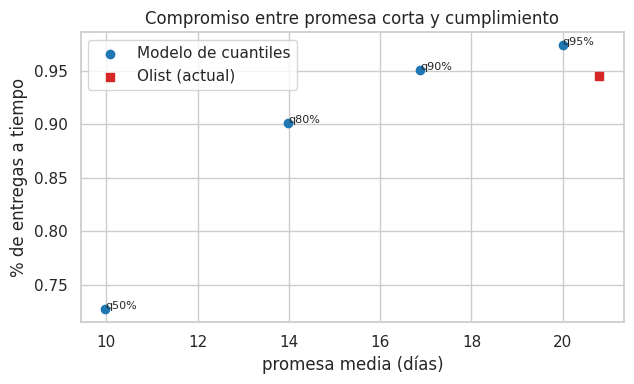

In [61]:
from sklearn.metrics import mean_pinball_loss                     # métrica propia de los modelos de cuantiles

ALFAS = [0.50, 0.80, 0.90, 0.95]                                  # niveles de confianza a probar (0.90 = "llega a tiempo en el 90% de los casos")

def nuevo_cuantil(alfa):
    """Crea un regresor que predice el cuantil 'alfa' de la distribución del tiempo de entrega."""
    if HAY_LGBM:                                                  # LightGBM si está instalado
        return lgb.LGBMRegressor(objective='quantile', alpha=alfa, n_estimators=400, learning_rate=0.05, num_leaves=31,
                                 subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEMILLA,
                                 n_jobs=-1, verbose=-1)           # objective='quantile' + alpha = cuantil buscado
    return HistGradientBoostingRegressor(loss='quantile', quantile=alfa, max_iter=300, learning_rate=0.05,
                                         random_state=SEMILLA)    # sustituto de sklearn con el mismo objetivo

est_te = df_p_te['tiempo_estimado_dias'].values                   # promesa actual de Olist para cada orden de test
filas_q, preds_q = [], {}                                         # métricas y predicciones por cuantil
for a in ALFAS:                                                   # un modelo por nivel
    pipe_q = armar_reg(nuevo_cuantil(a))                          # mismo preprocesador y objetivo logarítmico que el modelo de H.11
    pipe_q.fit(df_p_tr[FEAT_P], y_tr)                             # entrena SOLO con train
    pred_q = pipe_q.predict(df_p_te[FEAT_P])                      # días prometidos para cada orden de test
    preds_q[a] = pred_q                                           # se guarda para el gráfico
    filas_q.append({'modelo': f'Cuantil {int(a*100)}%', 'nivel nominal': a,
                    'cobertura real (a tiempo)': float(np.mean(y_te <= pred_q)),      # % de entregas dentro de la promesa
                    '% tarde': float(np.mean(y_te > pred_q)),                          # complemento
                    'promesa media (días)': float(pred_q.mean()),                      # días que se le prometen en promedio al cliente
                    'pinball loss': mean_pinball_loss(y_te, pred_q, alpha=a)})         # error propio del cuantil
filas_q.append({'modelo': 'Estimación Olist (actual)', 'nivel nominal': np.nan,
                'cobertura real (a tiempo)': float(np.mean(y_te <= est_te)), '% tarde': float(np.mean(y_te > est_te)),
                'promesa media (días)': float(est_te.mean()), 'pinball loss': np.nan})   # punto de comparación
tabla_q = pd.DataFrame(filas_q).set_index('modelo')               # tabla comparativa
tabla_q['ahorro vs Olist (días)'] = est_te.mean() - tabla_q['promesa media (días)']   # cuántos días menos se promete que hoy
display(tabla_q.round(3))

# ---- Promesa recomendada: la más corta que no empeora el % tarde actual de Olist ----
cob_olist = tabla_q.loc['Estimación Olist (actual)', 'cobertura real (a tiempo)']   # cobertura que hoy se logra
candidatos = tabla_q.iloc[:-1][tabla_q.iloc[:-1]['cobertura real (a tiempo)'] >= cob_olist]   # cuantiles que igualan o mejoran ese nivel
if len(candidatos):                                               # si alguno lo logra, se elige el de menor promesa
    mejor_q = candidatos['promesa media (días)'].idxmin()
    print(f'Promesa recomendada: {mejor_q} -> {candidatos.loc[mejor_q, "promesa media (días)"]:.1f} días en promedio '
          f'(Olist: {est_te.mean():.1f}), con {candidatos.loc[mejor_q, "% tarde"]:.1%} tarde (Olist: {1-cob_olist:.1%}).')
else:                                                             # si ninguno llega a la cobertura de Olist
    mejor_q = None
    print('Ningún cuantil probado alcanza la cobertura actual de Olist; probar α más altos (0.97, 0.99).')

# ---- Gráfico: cobertura vs. días prometidos ----
plt.figure(figsize=(6.5, 4))
plt.scatter(tabla_q.iloc[:-1]['promesa media (días)'], tabla_q.iloc[:-1]['cobertura real (a tiempo)'], c='tab:blue', label='Modelo de cuantiles')
for nombre, fila in tabla_q.iloc[:-1].iterrows():                 # etiqueta cada punto con su cuantil
    plt.annotate(nombre.replace('Cuantil ', 'q'), (fila['promesa media (días)'], fila['cobertura real (a tiempo)']), fontsize=8)
plt.scatter(est_te.mean(), cob_olist, c='tab:red', marker='s', label='Olist (actual)')
plt.xlabel('promesa media (días)'); plt.ylabel('% de entregas a tiempo'); plt.title('Compromiso entre promesa corta y cumplimiento')
plt.legend(); plt.tight_layout(); plt.show()
RESULTADOS['cuantiles'] = {'tabla': tabla_q, 'mejor': mejor_q}   # guarda para el cierre

## H.15 Paso 2 – Feriados regionales y clima para el *lead time*

* **Feriados (disponibles):** se agregan tres variables **conocidas al momento de comprar**: si la compra cae en feriado nacional, **cuántos feriados nacionales** y **cuántos feriados del estado del comprador** caen entre la compra y la fecha estimada de entrega (los feriados detienen el transporte y el reparto).
  La lista regional es **parcial** (solo feriados estaduales muy conocidos) y está en un diccionario editable: conviene revisarla antes de usar el resultado como definitivo.
* **Clima (requiere datos externos):** no hay datos meteorológicos en Olist ni acceso a ellos desde acá. La celda deja listo el código: si se completa `CLIMA_CSV` con un archivo diario por estado (columnas `fecha`, `estado`, `precipitacion_mm`, por ejemplo desde INMET), se agrega la **precipitación acumulada de los 7 días posteriores a la compra**.
  Atención: ese dato es **posterior a la compra**; sirve para **explicar** la demora o, en producción, con **pronóstico** del clima, pero no como dato observado al comprar.
* Se compara el mismo modelo (mismos hiperparámetros) **con y sin** las variables nuevas.

In [62]:
# ---------- H.15  Feriados regionales y clima ----------
CLIMA_CSV = None                                                  # ruta a un CSV con columnas: fecha, estado, precipitacion_mm (None = sin clima)

FERIADOS_REG = {                                                  # LISTA PARCIAL a verificar: estado (minúscula) -> fechas "mes-día" fijas
    'sp': ['07-09'],                                              # Revolución Constitucionalista
    'rj': ['04-23', '11-20'],                                     # San Jorge y Conciencia Negra
    'rs': ['09-20'],                                              # Revolución Farroupilha
    'pe': ['03-06'],                                              # Revolución Pernambucana
    'ba': ['07-02'],                                              # Independencia de Bahía
    'ce': ['03-25'],                                              # Abolición en Ceará
    'pr': ['12-19'],                                              # Emancipación de Paraná
    'sc': ['08-11'],                                              # Día de Santa Catarina
    'df': ['11-30']}                                              # Día del Evangélico

def contar_en_ventana(fechas_feriado, inicio, fin):
    """Cuenta cuántas fechas de 'fechas_feriado' caen entre inicio y fin (ambos inclusive), fila por fila."""
    f = np.sort(np.asarray(fechas_feriado, dtype='datetime64[D]'))            # feriados ordenados (días)
    i = np.asarray(inicio, dtype='datetime64[D]'); j = np.asarray(fin, dtype='datetime64[D]')   # inicio y fin de cada ventana
    n = np.searchsorted(f, j, side='right') - np.searchsorted(f, i, side='left')   # feriados <= fin menos feriados < inicio
    return np.clip(n, 0, None)                                    # si la ventana fuera inválida (fin < inicio), cuenta 0

df_p2 = df_p.copy()                                               # copia de df_p (órdenes entregadas y filtradas de H.11); df_p no se toca
inicio = df_p2['order_purchase_timestamp'].dt.normalize().values  # día de la compra
fin = df_p2['order_estimated_delivery_date'].dt.normalize().values   # día estimado de entrega (conocido al comprar)
fer_nac = pd.to_datetime(FERIADOS).normalize().values             # feriados nacionales de H.9 (2016-2018)
df_p2['es_feriado_compra'] = np.isin(inicio, fer_nac).astype(int)  # 1 si se compró en feriado nacional
df_p2['feriados_nac_ventana'] = contar_en_ventana(fer_nac, inicio, fin)   # feriados nacionales entre la compra y la entrega estimada
df_p2['feriados_reg_ventana'] = 0                                 # se completa por estado
for estado, lista in FERIADOS_REG.items():                        # recorre los estados con feriados propios
    fechas = [pd.Timestamp(f'{a}-{md}') for a in (2016, 2017, 2018) for md in lista]   # fechas de ese estado en cada año
    m = (df_p2['customer_state'] == estado).values                # filas cuyo comprador vive en ese estado
    df_p2.loc[m, 'feriados_reg_ventana'] = contar_en_ventana(fechas, inicio[m], fin[m])   # feriados del estado en la ventana
print('Órdenes con al menos 1 feriado en la ventana de entrega:',
      f'{((df_p2["feriados_nac_ventana"] + df_p2["feriados_reg_ventana"]) > 0).mean():.1%}')

def agregar_clima(df, ruta):
    """Suma la precipitación (mm) de los 7 días posteriores a la compra, por estado del comprador. Devuelve el df con 'precip_7d_mm'."""
    clima = pd.read_csv(ruta, parse_dates=['fecha'])              # clima diario por estado
    clima['estado'] = clima['estado'].astype(str).str.strip().str.lower()   # mismas minúsculas que customer_state
    out = pd.Series(np.nan, index=df.index)                       # resultado, alineado con df
    for estado, g in clima.groupby('estado'):                     # un estado por vez
        dias = pd.date_range(g['fecha'].min(), g['fecha'].max(), freq='D')   # calendario completo de ese estado
        s = g.set_index('fecha')['precipitacion_mm'].reindex(dias).fillna(0)   # días sin dato = 0 mm
        acum = np.concatenate([[0.0], s.cumsum().values])         # acumulado con un cero adelante (permite restar ventanas)
        m = (df['customer_state'] == estado).values               # compras de ese estado
        pos = (df.loc[m, 'order_purchase_timestamp'].dt.normalize() - dias[0]).dt.days.values   # posición del día de compra en el calendario
        ok = (pos >= 0) & (pos + 7 <= len(dias))                  # solo ventanas completas dentro del archivo de clima
        res = np.full(m.sum(), np.nan)                            # por defecto, sin dato
        res[ok] = acum[pos[ok] + 7] - acum[pos[ok]]               # suma de los 7 días [compra, compra+6]
        out[m] = res
    df = df.copy(); df['precip_7d_mm'] = out                      # copia con la nueva columna
    return df

extra_clima = []                                                  # lista de variables de clima disponibles
if CLIMA_CSV:                                                     # solo si se indicó un archivo
    df_p2 = agregar_clima(df_p2, CLIMA_CSV)                       # agrega precip_7d_mm
    extra_clima = ['precip_7d_mm']
else:
    print('Clima: sin datos externos (CLIMA_CSV = None). Se prueban solo los feriados.')

# ---- Comparación con y sin variables nuevas (mismo modelo y mismos hiperparámetros) ----
def boosting_defecto():
    """El mismo regresor de boosting que el modelo base del proyecto."""
    if HAY_LGBM:
        return lgb.LGBMRegressor(n_estimators=600, learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1,
                                 colsample_bytree=0.8, random_state=SEMILLA, n_jobs=-1, verbose=-1)
    return HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, random_state=SEMILLA)

def armar_reg_con(reg, prep):
    """Igual que armar_reg pero con el preprocesador indicado."""
    return Pipeline([('prep', clone(prep)),
                     ('reg', TransformedTargetRegressor(regressor=reg, func=np.log1p, inverse_func=np.expm1))])

FEAT_FER = ['es_feriado_compra', 'feriados_nac_ventana', 'feriados_reg_ventana'] + extra_clima   # variables nuevas
prep_fer = armar_preprocesador(sesgadas=FEAT_P_SESG + extra_clima,                                  # clima: positivo y asimétrico
                               simetricas=FEAT_P_SIM + ['feriados_nac_ventana', 'feriados_reg_ventana'],
                               binarias=BINARIAS + ['es_feriado_compra'], cat_ohe=CAT_OHE, cat_te=CAT_TE)
df_p2_tr, df_p2_te = dividir_temporal(df_p2)                      # misma partición cronológica
y2_tr, y2_te = df_p2_tr[Y_COL].values, df_p2_te[Y_COL].values     # objetivo

base_m = armar_reg_con(boosting_defecto(), prep_p).fit(df_p2_tr[FEAT_P], y2_tr)                   # sin variables nuevas
ext_m = armar_reg_con(boosting_defecto(), prep_fer).fit(df_p2_tr[FEAT_P + FEAT_FER], y2_tr)       # con feriados (y clima si hay)
tabla_fer = pd.DataFrame([metricas_reg('Base (H.11)', y2_te, base_m.predict(df_p2_te[FEAT_P])),
                          metricas_reg('Base + feriados' + (' + clima' if extra_clima else ''), y2_te,
                                       ext_m.predict(df_p2_te[FEAT_P + FEAT_FER]))]).set_index('modelo')
display(tabla_fer.round(3))
dif = tabla_fer['MAE (días)'].iloc[0] - tabla_fer['MAE (días)'].iloc[1]   # mejora del MAE (positiva = mejora)
print(f'Cambio del MAE al agregar las variables nuevas: {dif:+.3f} días ({dif / tabla_fer["MAE (días)"].iloc[0]:+.1%}). '
      'Diferencias menores a ~0,02 días no son distinguibles del ruido.')
RESULTADOS['feriados'] = {'tabla': tabla_fer, 'dif_mae': float(dif), 'con_clima': bool(extra_clima)}

Órdenes con al menos 1 feriado en la ventana de entrega: 54.7%
Clima: sin datos externos (CLIMA_CSV = None). Se prueban solo los feriados.


,MAE (días),RMSE (días),R²,MAPE %
modelo,,,,
Base (H.11),3.683,5.171,0.190,55.264
Base + feriados,3.628,5.144,0.198,53.698


Cambio del MAE al agregar las variables nuevas: +0.055 días (+1.5%). Diferencias menores a ~0,02 días no son distinguibles del ruido.


## H.16 Paso 3 – Validación cruzada temporal (`TimeSeriesSplit`) y ajuste de hiperparámetros

* `TimeSeriesSplit` arma **varios cortes en el tiempo**: en cada uno se entrena con el pasado y se valida con el tramo siguiente (nunca al revés). Así se ve si el error **es estable** o depende del período.
* Todo se hace **solo dentro del train**; el test (jun-ago 2018) se usa una única vez, al final.
* Primero se mide la estabilidad del modelo por defecto en cada corte; luego `RandomizedSearchCV` (8 combinaciones) busca hiperparámetros con ese mismo esquema de validación.

In [63]:
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV, cross_val_score   # validación temporal y búsqueda

df_cv = df_p_tr.sort_values('order_purchase_timestamp').reset_index(drop=True)   # train ordenado cronológicamente (requisito de TimeSeriesSplit)
X_cv, y_cv = df_cv[FEAT_P], df_cv[Y_COL].values                   # variables y objetivo del train
tscv = TimeSeriesSplit(n_splits=4)                                # 4 cortes: entrena con el pasado y valida con el tramo siguiente

# ---- 1) Estabilidad del modelo por defecto en cada corte ----
modelo_def = armar_reg_con(boosting_defecto(), prep_p)            # modelo base de H.11
maes = -cross_val_score(modelo_def, X_cv, y_cv, cv=tscv, scoring='neg_mean_absolute_error')   # MAE de cada corte (el signo se invierte)
filas_cv = []                                                     # tabla de cortes
for k, (i_tr, i_va) in enumerate(tscv.split(X_cv), start=1):      # recorre los cortes para mostrar sus fechas
    filas_cv.append({'corte': k, 'entrena con (hasta)': df_cv['order_purchase_timestamp'].iloc[i_tr].max().date(),
                     'valida (desde)': df_cv['order_purchase_timestamp'].iloc[i_va].min().date(),
                     'valida (hasta)': df_cv['order_purchase_timestamp'].iloc[i_va].max().date(),
                     'MAE validación (días)': maes[k - 1]})
display(pd.DataFrame(filas_cv).set_index('corte').round(3))
print(f'MAE entre cortes: media {maes.mean():.2f} d | desvío {maes.std():.2f} d | rango {maes.min():.2f}-{maes.max():.2f} d')

# ---- 2) Búsqueda de hiperparámetros con validación temporal ----
if HAY_LGBM:                                                      # nombres de parámetros según el regresor (Pipeline -> reg -> regressor)
    espacio = {'reg__regressor__num_leaves': [15, 31, 63], 'reg__regressor__learning_rate': [0.03, 0.05, 0.1],
               'reg__regressor__n_estimators': [300, 600, 900], 'reg__regressor__min_child_samples': [20, 50, 100],
               'reg__regressor__colsample_bytree': [0.6, 0.8, 1.0]}
else:
    espacio = {'reg__regressor__max_leaf_nodes': [15, 31, 63], 'reg__regressor__learning_rate': [0.03, 0.05, 0.1],
               'reg__regressor__max_iter': [200, 400, 600], 'reg__regressor__min_samples_leaf': [20, 50, 100]}
busqueda = RandomizedSearchCV(armar_reg_con(boosting_defecto(), prep_p), espacio, n_iter=8, cv=tscv,
                              scoring='neg_mean_absolute_error', random_state=SEMILLA, n_jobs=1, refit=True)   # refit=True: reentrena el mejor con todo el train
busqueda.fit(X_cv, y_cv)                                          # prueba 8 combinaciones x 4 cortes
print('Mejores hiperparámetros:', {k.split('__')[-1]: v for k, v in busqueda.best_params_.items()})
print(f'MAE de validación temporal del mejor: {-busqueda.best_score_:.3f} d (por defecto: {maes.mean():.3f} d)')

# ---- 3) Evaluación final en test (una sola vez) ----
modelo_def.fit(X_cv, y_cv)                                        # modelo por defecto reentrenado con todo el train
tabla_cv = pd.DataFrame([
    metricas_reg('Boosting por defecto', y_te, modelo_def.predict(df_p_te[FEAT_P])),
    metricas_reg('Boosting ajustado (TimeSeriesSplit)', y_te, busqueda.predict(df_p_te[FEAT_P]))]).set_index('modelo')
display(tabla_cv.round(3))
RESULTADOS['cv_temporal'] = {'maes': maes, 'tabla': tabla_cv, 'mejores': busqueda.best_params_}

,entrena con (hasta),valida (desde),valida (hasta),MAE validación (días)
corte,,,,
1,2017-07-12,2017-07-12,2017-11-03,5.579
2,2017-11-03,2017-11-03,2018-01-14,5.909
3,2018-01-14,2018-01-14,2018-03-22,7.056
4,2018-03-22,2018-03-22,2018-05-31,4.662


MAE entre cortes: media 5.80 d | desvío 0.86 d | rango 4.66-7.06 d
Mejores hiperparámetros: {'num_leaves': 15, 'n_estimators': 900, 'min_child_samples': 100, 'learning_rate': 0.03, 'colsample_bytree': 0.6}
MAE de validación temporal del mejor: 5.762 d (por defecto: 5.802 d)


,MAE (días),RMSE (días),R²,MAPE %
modelo,,,,
Boosting por defecto,3.671,5.173,0.189,54.877
Boosting ajustado (TimeSeriesSplit),3.640,5.123,0.205,54.740


## H.17 Paso 4 – RFM del cliente, historial del vendedor y carga de la plataforma en el Caso 1

Se rehace el Caso 1 (retraso) agregando variables **conocidas al momento de comprar**, todas calculadas **solo con el pasado** de cada orden:

| Variable | Qué mide | Cómo evita la fuga |
|---|---|---|
| `vend_tasa_retraso_hist`, `vend_n_prev` | Tasa de retraso del vendedor (suavizada hacia el promedio de train) y cantidad de entregas previas | Usa solo órdenes del vendedor **ya entregadas antes de la fecha de compra** |
| `cli_n_previas`, `cli_dias_desde_ultima`, `cli_gasto_previo` | RFM del cliente *al momento de cada compra* (versión «punto en el tiempo» del RFM al corte) | Solo compras anteriores del mismo `customer_unique_id` |
| `carga_7d`, `carga_rel` | Órdenes de los 7 días previos y su relación con el promedio de las 4 semanas previas (saturación logística) | Solo días anteriores a la compra |
| `tiempo_estimado_dias` | Promesa de Olist para esa orden | Se conoce al comprar. **Ojo:** si el modelo mejora mucho, parte del mérito es de esta variable (captura cuán holgada es la promesa, no la logística); por eso se agrega una **prueba de control sin ella** |

Además se **quita `mes`**, que en H.13 mostró relaciones que se invierten entre train y test.

In [64]:
# ---------- H.17  Variables de historial (punto en el tiempo) para el Caso 1 ----------
base_c1 = df_ent.sort_values('order_purchase_timestamp').reset_index(drop=True)   # órdenes entregadas, en orden cronológico (copia; df_ent no se toca)
prior_ret = base_c1.loc[base_c1['order_purchase_timestamp'] < F_CORTE, 'is_delayed'].mean()   # tasa global de retraso en train (prior)
K_V = 10                                                          # peso del prior: equivale a 10 entregas ficticias con la tasa global

# ---- (a) Historial del vendedor: solo entregas ocurridas ANTES de la compra de cada orden ----
vend_n = np.zeros(len(base_c1)); vend_ret = np.zeros(len(base_c1))   # entregas previas y retrasos previos de cada orden
for sid, idx in base_c1.groupby('seller_id').groups.items():     # un vendedor por vez (idx = posiciones de sus órdenes)
    idx = np.asarray(idx)                                         # posiciones como arreglo
    sub = base_c1.iloc[idx]                                       # órdenes de ese vendedor
    orden = np.argsort(sub['order_delivered_customer_date'].values)   # orden de sus entregas en el tiempo
    t_ent = sub['order_delivered_customer_date'].values[orden].astype('datetime64[ns]')   # momentos de entrega, ordenados
    acum_ret = np.cumsum(sub['is_delayed'].values[orden])         # retrasos acumulados en ese orden
    pos = np.searchsorted(t_ent, sub['order_purchase_timestamp'].values.astype('datetime64[ns]'), side='left')   # nº de entregas anteriores a cada compra
    vend_n[idx] = pos                                             # entregas previas
    vend_ret[idx] = np.where(pos > 0, acum_ret[np.maximum(pos - 1, 0)], 0)   # retrasos previos (0 si no hay entregas previas)
base_c1['vend_n_prev'] = vend_n                                   # cantidad de entregas previas del vendedor
base_c1['vend_tasa_retraso_hist'] = (vend_ret + K_V * prior_ret) / (vend_n + K_V)   # tasa suavizada

# ---- (b) RFM del cliente "punto en el tiempo" ----
g_cli = base_c1.groupby('customer_unique_id')                     # compras de cada persona real
base_c1['cli_n_previas'] = g_cli.cumcount()                       # frecuencia previa: 0 si es su primera compra
ult = g_cli['order_purchase_timestamp'].shift(1)                  # fecha de la compra anterior (nula si no hay)
base_c1['cli_dias_desde_ultima'] = (base_c1['order_purchase_timestamp'] - ult) / UN_DIA   # recencia previa
monto = base_c1['pago_total'].fillna(base_c1['precio_total'] + base_c1['flete_total']).fillna(0)   # gasto de cada orden
base_c1['cli_gasto_previo'] = monto.groupby(base_c1['customer_unique_id']).cumsum() - monto   # monetario previo (excluye la compra actual)

# ---- (c) Carga de la plataforma (todas las órdenes, no solo las entregadas) ----
diario = df_f.groupby(df_f['order_purchase_timestamp'].dt.normalize()).size()   # órdenes por día
diario = diario.reindex(pd.date_range(diario.index.min(), diario.index.max(), freq='D'), fill_value=0)   # días sin ventas = 0
c7 = diario.rolling(7).sum().shift(1); c28 = diario.rolling(28).sum().shift(1)   # últimas 1 y 4 semanas, SIN incluir el propio día
dia_compra = base_c1['order_purchase_timestamp'].dt.normalize()   # día de cada compra
base_c1['carga_7d'] = dia_compra.map(c7)                          # órdenes de los 7 días previos
base_c1['carga_rel'] = dia_compra.map(c7 / (c28 / 4))             # >1 = la última semana fue más cargada que el promedio mensual
print(f'Clientes con historial previo: {(base_c1["cli_n_previas"] > 0).mean():.1%} de las órdenes entregadas')

# ---- Variables y modelos ----
C1M_SESG = FEAT_C1_SESG + ['vend_n_prev', 'carga_7d', 'cli_gasto_previo']   # asimétricas -> winsorizar + log + robusto
C1M_SIM = ['dia_semana', 'tiempo_estimado_dias', 'vend_tasa_retraso_hist', 'carga_rel', 'cli_n_previas', 'cli_dias_desde_ultima']   # sin 'mes'
FEAT_C1M = C1M_SESG + C1M_SIM + CAT_OHE                           # lista total
prep_c1m = armar_preprocesador(sesgadas=C1M_SESG, simetricas=C1M_SIM, cat_ohe=CAT_OHE)   # nuevo preprocesador
c1m_tr, c1m_te = dividir_temporal(base_c1)                        # misma partición cronológica
peso_pos_m = (c1m_tr[TARGET_C1] == 0).sum() / max((c1m_tr[TARGET_C1] == 1).sum(), 1)   # negativos/positivos (para XGBoost)

modelos_c1m = {'Reg. Logística': armar_pipe(LogisticRegression(max_iter=1000, class_weight='balanced'), prep_c1m),
               'Random Forest': armar_pipe(RandomForestClassifier(n_estimators=200, min_samples_leaf=20, class_weight='balanced_subsample',
                                                                  n_jobs=-1, random_state=SEMILLA), prep_c1m)}
if HAY_XGB:
    modelos_c1m['XGBoost'] = armar_pipe(xgb.XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                                                          colsample_bytree=0.8, scale_pos_weight=peso_pos_m, eval_metric='aucpr',
                                                          n_jobs=-1, random_state=SEMILLA), prep_c1m)
if HAY_LGBM:
    modelos_c1m['LightGBM'] = armar_pipe(lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8,
                                                            subsample_freq=1, colsample_bytree=0.8, class_weight='balanced',
                                                            n_jobs=-1, random_state=SEMILLA, verbose=-1), prep_c1m)
if not (HAY_XGB and HAY_LGBM):
    modelos_c1m['HistGradientBoosting (sustituto)'] = armar_pipe(HistGradientBoostingClassifier(
        max_iter=300, learning_rate=0.05, class_weight='balanced', random_state=SEMILLA), prep_c1m)

filas_c1m = []                                                    # resultados del Caso 1 mejorado
for nombre, pipe in modelos_c1m.items():
    try:                                                          # si un modelo falla, se informa y se sigue
        fila, _ = evaluar_clasificador(nombre, pipe, c1m_tr, c1m_te, FEAT_C1M, TARGET_C1)   # misma función de H.7 (umbral validado en train)
        filas_c1m.append(fila)
    except Exception as e:
        print(f'AVISO: {nombre} no pudo entrenarse ({type(e).__name__}: {e})')
tabla_c1m = pd.DataFrame(filas_c1m).set_index('modelo')

# ---- Prueba de control: ¿cuánto aporta la promesa de Olist (tiempo_estimado_dias)? ----
mejor_m = tabla_c1m['PR-AUC'].idxmax()                            # mejor modelo de la tabla anterior
C1M_SIM_SIN = [c for c in C1M_SIM if c != 'tiempo_estimado_dias']   # simétricas sin la promesa de Olist
FEAT_C1M_SIN = C1M_SESG + C1M_SIM_SIN + CAT_OHE                   # mismas variables, sin esa columna
prep_sin = armar_preprocesador(sesgadas=C1M_SESG, simetricas=C1M_SIM_SIN, cat_ohe=CAT_OHE)   # preprocesador de control
pipe_sin = armar_pipe(clone(modelos_c1m[mejor_m].named_steps['clf']), prep_sin)   # mismo algoritmo, sin entrenar
fila_sin, _ = evaluar_clasificador(f'{mejor_m} (sin tiempo_estimado_dias)', pipe_sin, c1m_tr, c1m_te, FEAT_C1M_SIN, TARGET_C1)
tabla_c1m.loc[fila_sin['modelo']] = pd.Series(fila_sin).drop('modelo')   # agrega la fila de control a la tabla

# ---- Comparación contra el Caso 1 original (H.7) ----
comp = pd.concat([tabla_c1[['ROC-AUC', 'PR-AUC', 'F1 (umbral óptimo)']].assign(version='Original (H.7)'),
                  tabla_c1m[['ROC-AUC', 'PR-AUC', 'F1 (umbral óptimo)']].assign(version='Con historial (H.17)')])
display(comp.set_index('version', append=True).round(3))
prev_m = c1m_te[TARGET_C1].mean()                                 # prevalencia del test (referencia del azar para PR-AUC)
print(f'Referencia del azar: ROC-AUC 0.500 | PR-AUC {prev_m:.3f}. '
      f'Mejor PR-AUC original {tabla_c1["PR-AUC"].max():.3f} -> con historial {tabla_c1m["PR-AUC"].max():.3f}; '
      f'mejor ROC-AUC original {tabla_c1["ROC-AUC"].max():.3f} -> con historial {tabla_c1m["ROC-AUC"].max():.3f}.')

# ---- ¿Las variables nuevas se mantienen estables entre train y test? (AUC individual) ----
filas_u = []
for col in ['tiempo_estimado_dias', 'vend_tasa_retraso_hist', 'carga_rel', 'carga_7d', 'vend_n_prev']:
    med = c1m_tr[col].median()                                    # mediana de train para completar nulos
    filas_u.append({'variable': col,
                    'AUC en train': roc_auc_score(c1m_tr[TARGET_C1], c1m_tr[col].fillna(med)),
                    'AUC en test': roc_auc_score(c1m_te[TARGET_C1], c1m_te[col].fillna(med))})
display(pd.DataFrame(filas_u).set_index('variable').round(3))
RESULTADOS['caso1_hist'] = {'tabla': tabla_c1m, 'comparacion': comp}

Clientes con historial previo: 3.2% de las órdenes entregadas


,,ROC-AUC,PR-AUC,F1 (umbral óptimo)
modelo,version,,,
Regresión Logística (baseline),Original (H.7),0.414,0.054,0.074
Random Forest,Original (H.7),0.527,0.061,0.078
Reg. Logística + SMOTE,Original (H.7),0.419,0.054,0.072
XGBoost,Original (H.7),0.566,0.067,0.064
LightGBM,Original (H.7),0.559,0.067,0.060
Reg. Logística,Con historial (H.17),0.692,0.100,0.150
Random Forest,Con historial (H.17),0.556,0.059,0.065
XGBoost,Con historial (H.17),0.580,0.065,0.079
LightGBM,Con historial (H.17),0.564,0.063,0.080


Referencia del azar: ROC-AUC 0.500 | PR-AUC 0.055. Mejor PR-AUC original 0.067 -> con historial 0.100; mejor ROC-AUC original 0.566 -> con historial 0.692.


,AUC en train,AUC en test
variable,,
tiempo_estimado_dias,0.474,0.208
vend_tasa_retraso_hist,0.554,0.496
carga_rel,0.536,0.606
carga_7d,0.648,0.672
vend_n_prev,0.531,0.495


In [65]:
# ---------- H.17.1  Resumen automático de los próximos pasos (H.14 a H.17) ----------
from IPython.display import Markdown                              # texto con formato generado por código
def n2(x, d=2): return f'{x:,.{d}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')   # número con coma decimal
partes = ['### Resultados de los próximos pasos (generado con lo ejecutado en H.14 a H.17)']   # líneas del resumen

# --- H.14 Cuantiles ---
if 'cuantiles' in RESULTADOS:
    tq, mq = RESULTADOS['cuantiles']['tabla'], RESULTADOS['cuantiles']['mejor']
    ol = tq.loc['Estimación Olist (actual)']                      # fila de Olist
    if mq is not None:
        f = tq.loc[mq]
        partes.append(f"* **Cuantiles:** {mq} promete en promedio **{n2(f['promesa media (días)'], 1)} días** frente a {n2(ol['promesa media (días)'], 1)} de Olist "
                      f"({n2(abs(f['ahorro vs Olist (días)']), 1)} días {'menos' if f['ahorro vs Olist (días)'] >= 0 else 'más'}), con {n2(f['% tarde'] * 100, 1)} % de entregas tarde (Olist: {n2(ol['% tarde'] * 100, 1)} %).")
    else:
        partes.append('* **Cuantiles:** ningún cuantil probado alcanza el cumplimiento actual de Olist; probar α más altos.')
# --- H.15 Feriados / clima ---
if 'feriados' in RESULTADOS:
    r = RESULTADOS['feriados']
    util = 'aportan una mejora mínima pero medible' if r['dif_mae'] > 0.02 else 'no aportan una mejora distinguible del ruido'
    partes.append(f"* **Feriados{' y clima' if r['con_clima'] else ''}:** el MAE cambia en {n2(r['dif_mae'], 3)} días; las variables nuevas {util}.")
# --- H.16 TimeSeriesSplit ---
if 'cv_temporal' in RESULTADOS:
    r = RESULTADOS['cv_temporal']; m = r['maes']; t = r['tabla']
    partes.append(f"* **Validación temporal:** el MAE por corte va de {n2(m.min())} a {n2(m.max())} días (media {n2(m.mean())}, desvío {n2(m.std())}); "
                  f"en test, por defecto {n2(t['MAE (días)'].iloc[0], 3)} vs ajustado {n2(t['MAE (días)'].iloc[1], 3)} días: el ajuste de hiperparámetros "
                  f"{'aporta poco' if abs(t['MAE (días)'].iloc[0] - t['MAE (días)'].iloc[1]) < 0.05 else 'cambia el resultado de forma apreciable'}.")
# --- H.17 Historial + RFM ---
if 'caso1_hist' in RESULTADOS:
    tm = RESULTADOS['caso1_hist']['tabla']; t0 = tabla_c1
    sin = [i for i in tm.index if 'sin tiempo_estimado_dias' in i]
    con = tm.drop(index=sin)
    texto = (f"* **Caso 1 con historial:** mejor ROC-AUC {n2(t0['ROC-AUC'].max(), 3)} → {n2(con['ROC-AUC'].max(), 3)}; "
             f"mejor PR-AUC {n2(t0['PR-AUC'].max(), 3)} → {n2(con['PR-AUC'].max(), 3)}.")
    if sin:
        texto += (f" Sin la promesa de Olist (`tiempo_estimado_dias`) el ROC-AUC es {n2(tm.loc[sin[0], 'ROC-AUC'], 3)}: "
                  f"{'la mejora viene sobre todo de esa variable' if tm.loc[sin[0], 'ROC-AUC'] < t0['ROC-AUC'].max() + 0.03 else 'el historial aporta señal propia'}.")
    partes.append(texto)
display(Markdown('\n'.join(partes)))

### Resultados de los próximos pasos (generado con lo ejecutado en H.14 a H.17)
* **Cuantiles:** Cuantil 90% promete en promedio **16,9 días** frente a 20,8 de Olist (3,9 días menos), con 4,9 % de entregas tarde (Olist: 5,5 %).
* **Feriados:** el MAE cambia en 0,055 días; las variables nuevas aportan una mejora mínima pero medible.
* **Validación temporal:** el MAE por corte va de 4,66 a 7,06 días (media 5,80, desvío 0,86); en test, por defecto 3,671 vs ajustado 3,640 días: el ajuste de hiperparámetros aporta poco.
* **Caso 1 con historial:** mejor ROC-AUC 0,566 → 0,692; mejor PR-AUC 0,067 → 0,100. Sin la promesa de Olist (`tiempo_estimado_dias`) el ROC-AUC es 0,524: la mejora viene sobre todo de esa variable.

## H.18 Conclusiones y cierre final

*Los números de este texto corresponden a la corrida del 09/11/2026; al volver a ejecutar (sobre todo el Caso 3, corregido en esta versión) pueden variar. Lo marcado como **hipótesis** se confirma o descarta con la celda H.13.*

### 1. Síntesis

El trabajo cumple el recorrido completo del documento: consolidación y limpieza sin tocar los `raw_*`, ingeniería de variables (distancia Haversine, volumen, tiempos, ratios), preprocesamiento **sin fuga** (todo aprendido solo con train), validación **cronológica** y cuatro casos más el proyecto de *lead time*. El resultado más sólido es la **predicción del tiempo de entrega**; el más débil, la **predicción de retrasos al momento de comprar**. Entre ambos hay un hallazgo común que ordena todo lo demás: **el período de test no se comporta como el de entrenamiento**.

### 2. Resultados por consigna

| Consigna | Resultado clave | Lectura honesta |
|---|---|---|
| **Caso 1** – Retraso (clasificación) | Mejor ROC-AUC 0,566 (XGBoost); PR-AUC 0,068 frente a 0,055 del azar (1,2×); F1 ≤ 0,078 | Mejora el 0,52 del Paso 7, pero sigue siendo **débil**. La regresión logística (0,414) **ordena al revés** en test: lo que aprendió en train se invirtió |
| **Caso 2** – Satisfacción, variables tabulares | ROC-AUC 0,653; F1 de la clase negativa 0,351 (Random Forest) | Modesto, útil para priorizar casos. La *accuracy* (0,771) es menor que la de «todo positivo» (0,834) porque el modelo sí intenta detectar negativas |
| **Caso 2** – Satisfacción, texto | Accuracy 0,896; F1 negativa 0,824; ROC-AUC 0,950 | Muy bueno, pero solo para reseñas con comentario (≈ 38 % del test) y el texto se conoce **después** de la compra: sirve para **monitorear y clasificar reseñas**, no para anticipar |
| **Caso 3** – Ventas diarias | Total: Prophet MAPE 20,6 % (MAE 40,7) vs referencia (promedio de 4 semanas) 21,2 % (MAE 43,3); XGBoost 31,3 %, SARIMAX 32,8 %. São Paulo: XGBoost MAPE 25,6 % (MAE 20,7) vs 28,7 % (MAE 24,4) de la referencia | A nivel nacional Prophet supera a la referencia por poco (≈ 6 % menos de MAE); en São Paulo XGBoost mejora el MAE ≈ 15 %. En ambos casos la ganancia sobre un promedio simple es **modesta** |
| **Caso 4** – RFM | K-Means k = 4 (Silhouette 0,376); 97 % compró una sola vez | Segmentación **descriptiva útil**, pero con estructura débil (DBSCAN: Silhouette −0,03) |
| **Proyecto** – *Lead time* | LightGBM: MAE 3,68 días, RMSE 5,17, R² 0,19 (RF y XGBoost casi iguales); Ridge 4,52 días | El mejor resultado del trabajo. Reduce **71 %** el error frente a la estimación de Olist (12,71 días) y acierta más cerca en el **88 %** de las órdenes |

### 3. Hallazgos que aparecieron al ejecutar

**3.1 Deriva temporal (transversal a los casos).** Entre train y test baja el retraso (8,74 % → 5,48 %), las reseñas negativas (22,1 % → 16,6 %) y el tiempo medio de entrega (13,4 → 8,6 días). Consecuencias: el modelo del *lead time* **sobreestima** (sesgo +1,53 días), la media de train da R² negativo (−0,70) y, en el Caso 1, los árboles apenas superan al azar. Dos **hipótesis** que no se excluyen: (a) el train incluye los meses más conflictivos (fines de 2017 y comienzo de 2018) que no se repiten en jun-ago 2018; (b) **censura**: al filtrar solo las entregadas, el test excluye los pedidos lentos de los últimos meses que al cierre del dataset todavía no habían llegado (2.965 órdenes sin entrega en total), lo que hace ver el test «más rápido» de lo que fue. La celda H.13 muestra el % de entregadas por mes y la evolución mensual para confirmarlo.

**3.2 La estimación de Olist es una promesa conservadora, no una predicción.** Promete en promedio ≈ 12 días de más y llega tarde solo el 5,5 % de las veces. El modelo erra mucho menos, pero si se usara su **predicción puntual** como fecha prometida llegaría tarde el **25,6 %**. Un dato orientativo: el percentil 95 del residuo es ≈ 6,1 días; prometer «predicción + 6 días» dejaría un ≈ 5 % tarde (similar al actual) con una promesa media de ≈ 16 días en lugar de ≈ 21. Es una estimación hecha sobre el mismo test; para usarla hay que calibrar el margen en un período de validación o, mejor, entrenar un **modelo de cuantiles**.

**3.3 Defecto corregido en el Caso 3.** Los gráficos mostraban un pico falso el 12/06/2018 en Prophet y SARIMAX: Black Friday y los eventos menores (Día de las Madres, Enamorados) compartían una única marca, y el efecto enorme de Black Friday se aplicaba a fechas comunes. Al **separarlos**, Prophet mejora de 22,3 % a 20,6 % de MAPE y pasa a ser el mejor modelo del total (por margen estrecho frente a la referencia); XGBoost empeora en el total (27,7 % → 31,3 %) pero mejora en São Paulo (26,6 % → 25,6 %); SARIMAX queda igual (≈ 33 %). Cada evento tiene una o dos ocurrencias en la historia, así que sus efectos están poco estimados; con ~17 meses de historia y crecimiento irregular, un promedio de 4 semanas es una vara alta.

**3.4 Métricas que engañan.** La *accuracy* del Caso 2 premia a quien no detecta negativas; en el proyecto el **MAPE (55 %)** se infla por las entregas cortas (denominador chico), por lo que conviene leer MAE, la mediana del error y el R². Que las variables más influyentes sean distancia, peso y **día de la semana** de la compra es coherente con la logística (hipótesis: los pedidos del fin de semana se despachan después).

**3.5 RFM.** El 97 % compró una sola vez y solo el 2,3 % de quienes compraron después del corte ya era cliente: la **retención** es la gran oportunidad. La etiqueta automática «Nuevos de alto valor» del grupo 3 es generosa (gasto medio 122, apenas sobre la mediana de 108): conviene leerla como «recientes de valor medio». El segmento «En riesgo de alto valor» (30 % de los clientes, gasto medio 320, ~11 meses sin comprar) es el objetivo natural de campañas de reactivación.

### 4. Ajustes aplicados en esta versión del Colab
* Referencias **F.x → H.x** unificadas con los nombres de bloque.
* **Caso 3:** Black Friday y eventos menores como marcas separadas (calendario, XGBoost, SARIMAX y Prophet).
* **Informe automático (H.12):** el texto del Caso 3 ya no dice «mejor modelo» cuando gana la referencia.
* **H.13:** diagnóstico de la deriva temporal. **H.14 a H.17:** los cuatro próximos pasos del informe (cuantiles, feriados y clima, validación temporal, historial del vendedor y RFM). **H.18:** este cierre.

### 5. Próximos pasos recomendados
Los cuatro pasos propuestos en el informe se implementaron en **H.14 a H.17**; sus resultados numéricos se resumen automáticamente en la celda siguiente. Quedan abiertos:
1. Si H.14 muestra que un cuantil alto iguala el % tarde actual con una promesa más corta, **validar el margen en un período de calibración separado** (cuantiles conformales) antes de usarlo.
2. Cargar datos de **clima** (por ejemplo INMET) en H.15 si se quiere medir ese efecto; hoy solo se probaron feriados.
3. **Caso 2:** usar el modelo de texto como alerta temprana de reseñas negativas y el tabular, con `dias_retraso` real, para priorizar atención.
4. **Caso 4:** endurecer la regla de etiquetas (por ejemplo, «alto valor» desde el percentil 75) y probar RFM con puntajes por quintiles.

### 6. Cierre

El ejercicio muestra que **un buen preprocesamiento y una validación honesta importan más que el algoritmo**: con las mismas variables, los modelos más complejos rindieron casi igual, y los resultados cambian de signo cuando el futuro no se parece al pasado. El aporte más claro para el negocio es el modelo de tiempo de entrega (menos error y promesas más ajustadas, a condición de agregarle un margen), mientras que la predicción de retrasos al momento de comprar necesita información adicional antes de ser accionable. Todo se hizo sobre copias con los `raw_*` intactos y, por eso, cada cifra es reproducible.